In [2]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
/home/afanali/miniconda3/envs/wcnc/bin/python


In [3]:
import os
import numpy as np
import torch
import sionna
import sionna.rt as rt
import mitsuba as mi
import drjit as dr

# Configure OptiX for WSL2
os.environ["DRJIT_LIBOPTIX_PATH"] = (
    "/home/afanali/driver-dist/libnvoptix.so.1"
)
os.environ["LD_LIBRARY_PATH"] = (
    "/home/afanali/driver-dist:"
    + os.environ.get("LD_LIBRARY_PATH", "")
)

# Select Sionna-compatible GPU variant
mi.set_variant("cuda_ad_mono_polarized")

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("Sionna:", sionna.__version__)
print("Mitsuba variant:", mi.variant())
print("Environment initialized successfully.")

Python: /home/afanali/miniconda3/envs/wcnc/bin/python
PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
Sionna: 2.1.0
Mitsuba variant: cuda_ad_mono_polarized
Environment initialized successfully.


In [4]:
from pathlib import Path

# Main project directory
PROJECT_ROOT = Path("/home/afanali/wcnc_project")

# Project subdirectories
SCENE_DIR = PROJECT_ROOT / "scenes"
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"

# KFUPM Sionna RT scene
SCENE_PATH = (
    SCENE_DIR
    / "kfupm_terrain"
    / "kfupm_terrain.xml"
)

# Create output directories if needed
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Scene path:", SCENE_PATH)
print("Scene exists:", SCENE_PATH.exists())
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)

Project root: /home/afanali/wcnc_project
Scene path: /home/afanali/wcnc_project/scenes/kfupm_terrain/kfupm_terrain.xml
Scene exists: True
Results directory: /home/afanali/wcnc_project/results
Figures directory: /home/afanali/wcnc_project/figures


In [5]:
IMPROVED_ROOT = PROJECT_ROOT / "improved_experiment"

IMPROVED_DATA_DIR = IMPROVED_ROOT / "data"
IMPROVED_RESULTS_DIR = IMPROVED_ROOT / "results"
IMPROVED_FIGURES_DIR = IMPROVED_ROOT / "figures"
IMPROVED_MODELS_DIR = IMPROVED_ROOT / "models"

for folder in [
    IMPROVED_DATA_DIR,
    IMPROVED_RESULTS_DIR,
    IMPROVED_FIGURES_DIR,
    IMPROVED_MODELS_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Separate output folders created:")
print("Data:", IMPROVED_DATA_DIR)
print("Results:", IMPROVED_RESULTS_DIR)
print("Figures:", IMPROVED_FIGURES_DIR)
print("Models:", IMPROVED_MODELS_DIR)

Separate output folders created:
Data: /home/afanali/wcnc_project/improved_experiment/data
Results: /home/afanali/wcnc_project/improved_experiment/results
Figures: /home/afanali/wcnc_project/improved_experiment/figures
Models: /home/afanali/wcnc_project/improved_experiment/models


In [6]:
# Load the KFUPM 3D digital-twin scene
scene = rt.load_scene(
    str(SCENE_PATH),
    merge_shapes=False
)

# Set carrier frequency
scene.frequency = 3.5e9

print("KFUPM scene loaded successfully.")
print("Number of scene objects:", len(scene.objects))
print("Carrier frequency:", scene.frequency / 1e9, "GHz")

KFUPM scene loaded successfully.
Number of scene objects: 2817
Carrier frequency: [3.5] GHz


In [7]:
from math import pi

# ============================================================
# Research scenario and antenna configuration
# ============================================================

C0 = 299_792_458.0

RADIO_CONFIG = {
    "carrier_frequency_hz": 3.5e9,
    "bandwidth_hz": 100e6,
    "wavelength_m": C0 / 3.5e9,

    # Initial reproducible assumption used for all gNBs
    "gnb_transmit_power_dbm": 44.0,

    # Sionna PlanarArray spacings are expressed in wavelengths
    "tx_rows": 8,
    "tx_cols": 8,
    "tx_spacing_lambda": 0.5,

    "rx_rows": 2,
    "rx_cols": 2,
    "rx_spacing_lambda": 0.5,

    # 3GPP-like element pattern with vertical polarization
    # This preserves 64 TX elements and 4 RX elements.
    "antenna_pattern": "tr38901",
    "polarization": "V",
    "polarization_model": "tr38901_2",
}

scene.frequency = RADIO_CONFIG["carrier_frequency_hz"]

# ============================================================
# Transmitter array
# ============================================================

scene.tx_array = rt.PlanarArray(
    num_rows=RADIO_CONFIG["tx_rows"],
    num_cols=RADIO_CONFIG["tx_cols"],
    vertical_spacing=RADIO_CONFIG["tx_spacing_lambda"],
    horizontal_spacing=RADIO_CONFIG["tx_spacing_lambda"],
    pattern=RADIO_CONFIG["antenna_pattern"],
    polarization=RADIO_CONFIG["polarization"],
    polarization_model=RADIO_CONFIG["polarization_model"],
)

# ============================================================
# Receiver array
# ============================================================

scene.rx_array = rt.PlanarArray(
    num_rows=RADIO_CONFIG["rx_rows"],
    num_cols=RADIO_CONFIG["rx_cols"],
    vertical_spacing=RADIO_CONFIG["rx_spacing_lambda"],
    horizontal_spacing=RADIO_CONFIG["rx_spacing_lambda"],
    pattern=RADIO_CONFIG["antenna_pattern"],
    polarization=RADIO_CONFIG["polarization"],
    polarization_model=RADIO_CONFIG["polarization_model"],
)

# ============================================================
# KFUPM gNB configuration
# Coordinates are retained exactly from the validated scenario.
# z-coordinate represents the antenna phase-center height.
# ============================================================

GNB_CONFIG = [
    {
        "id": "gNB1_B59",
        "short_label": "gNB1",
        "site_label": "Building 59",
        "position_m": np.array([-541.7, 204.4, 69.0], dtype=np.float64),
        "color_hex": "#0072B2",
        "color_rgb": (0.000, 0.447, 0.698),
        "role": "activity-area serving site",
    },
    {
        "id": "gNB2_B21",
        "short_label": "gNB2",
        "site_label": "Building 21",
        "position_m": np.array([-513.0, -19.3, 87.0], dtype=np.float64),
        "color_hex": "#E69F00",
        "color_rgb": (0.902, 0.624, 0.000),
        "role": "activity-area serving site",
    },
    {
        "id": "gNB3_B15",
        "short_label": "gNB3",
        "site_label": "Building 15",
        "position_m": np.array([-903.3, 98.0, 91.2], dtype=np.float64),
        "color_hex": "#D55E00",
        "color_rgb": (0.835, 0.369, 0.000),
        "role": "activity-area serving site",
    },
]

# Compatibility dictionary for later Sionna and benchmark cells
GNB_POSITIONS = {
    item["id"]: item["position_m"].tolist()
    for item in GNB_CONFIG
}

GNB_NAMES = [item["id"] for item in GNB_CONFIG]

# Activity center used later for map zooming and figure framing
ACTIVITY_CENTER_XY = np.mean(
    [item["position_m"][:2] for item in GNB_CONFIG],
    axis=0
)

# ============================================================
# UE configuration
# ============================================================

UE_CONFIG = {
    "id": "UE_vehicle",
    "label": "UE vehicle",
    "initial_position_m": np.array(
        [-600.0, 150.0, 45.0],
        dtype=np.float64
    ),
    "antenna_mount": "vehicle roof",
    "color_hex": "#000000",
    "color_rgb": (0.0, 0.0, 0.0),
}

# ============================================================
# IEEE figure style
# ============================================================

IEEE_FIGURE_STYLE = {
    "font_family": "DejaVu Sans",
    "title_size": 16,
    "axis_label_size": 14,
    "tick_size": 12,
    "legend_size": 11,
    "line_width": 1.8,
    "grid_alpha": 0.25,
    "building_face_color": "#D9D9D9",
    "building_edge_color": "#555555",
    "road_color": "#BDBDBD",
    "route_color": "#111111",
    "ue_color": "#000000",
}

# Physical array dimensions for reporting
tx_aperture_y_m = (
    (RADIO_CONFIG["tx_cols"] - 1)
    * RADIO_CONFIG["tx_spacing_lambda"]
    * RADIO_CONFIG["wavelength_m"]
)

tx_aperture_z_m = (
    (RADIO_CONFIG["tx_rows"] - 1)
    * RADIO_CONFIG["tx_spacing_lambda"]
    * RADIO_CONFIG["wavelength_m"]
)

rx_aperture_y_m = (
    (RADIO_CONFIG["rx_cols"] - 1)
    * RADIO_CONFIG["rx_spacing_lambda"]
    * RADIO_CONFIG["wavelength_m"]
)

rx_aperture_z_m = (
    (RADIO_CONFIG["rx_rows"] - 1)
    * RADIO_CONFIG["rx_spacing_lambda"]
    * RADIO_CONFIG["wavelength_m"]
)

print("Radio configuration")
print("-------------------")
print(f"Carrier frequency: {RADIO_CONFIG['carrier_frequency_hz'] / 1e9:.2f} GHz")
print(f"Wavelength: {RADIO_CONFIG['wavelength_m']:.4f} m")
print(f"TX elements: {scene.tx_array.num_ant}")
print(f"RX elements: {scene.rx_array.num_ant}")
print(f"TX physical aperture: {tx_aperture_y_m:.3f} m x {tx_aperture_z_m:.3f} m")
print(f"RX physical aperture: {rx_aperture_y_m:.3f} m x {rx_aperture_z_m:.3f} m")

print("\nKFUPM gNB configuration")
print("-----------------------")
for item in GNB_CONFIG:
    print(
        f"{item['id']} | {item['site_label']} | "
        f"position={item['position_m'].tolist()}"
    )

print("\nActivity center:")
print(ACTIVITY_CENTER_XY)

Radio configuration
-------------------
Carrier frequency: 3.50 GHz
Wavelength: 0.0857 m
TX elements: 64
RX elements: 4
TX physical aperture: 0.300 m x 0.300 m
RX physical aperture: 0.043 m x 0.043 m

KFUPM gNB configuration
-----------------------
gNB1_B59 | Building 59 | position=[-541.7, 204.4, 69.0]
gNB2_B21 | Building 21 | position=[-513.0, -19.3, 87.0]
gNB3_B15 | Building 15 | position=[-903.3, 98.0, 91.2]

Activity center:
[-652.66666667   94.36666667]


In [8]:
# ============================================================
# Dense-data configuration and expanded KFUPM coverage
# ============================================================

DATA_CONFIG = {
    # Existing notebook used approximately 20 observations.
    # We will use a much denser route for the improved study.
    "route_points_per_trajectory": 240,

    # Start with six trajectories; increase later if runtime is acceptable.
    "num_trajectories": 6,

    # Mobility sampling interval
    "time_step_s": 0.5,

    # Different UE speeds for diversity
    "speeds_mps": [5.0, 8.0, 12.0],

    # Ray-tracing configuration
    "max_depth": 5,
    "los": True,
    "specular_reflection": True,
    "diffuse_reflection": False,
    "refraction": True,
    "synthetic_array": True,

    # Process observations in manageable batches
    "receiver_batch_size": 16,

    # Reproducibility
    "random_seed": 2026,
}

# Height of an antenna above the selected building roof.
# This is an explicit modeling assumption for the two added sites.
ADDITIONAL_GNB_ROOFTOP_OFFSET_M = 8.0

print("Dense-data configuration")
print("------------------------")
print(
    "Route points per trajectory:",
    DATA_CONFIG["route_points_per_trajectory"]
)
print("Number of trajectories:", DATA_CONFIG["num_trajectories"])
print("UE speeds:", DATA_CONFIG["speeds_mps"], "m/s")
print("Receiver batch size:", DATA_CONFIG["receiver_batch_size"])

Dense-data configuration
------------------------
Route points per trajectory: 240
Number of trajectories: 6
UE speeds: [5.0, 8.0, 12.0] m/s
Receiver batch size: 16


In [9]:
# ============================================================
# Find candidate building rooftops from the actual KFUPM scene
# ============================================================

def point3_to_numpy(point):
    """Convert a Mitsuba Point3f-like object to a NumPy vector."""
    return np.array(
        [float(point[0]), float(point[1]), float(point[2])],
        dtype=np.float64
    )


# Existing validated gNB locations
existing_gnb_xy = np.array(
    [
        item["position_m"][:2]
        for item in GNB_CONFIG
    ],
    dtype=np.float64
)

building_candidates = []

for object_name, scene_object in scene.objects.items():

    if not hasattr(scene_object, "mi_mesh"):
        continue

    try:
        bbox = scene_object.mi_mesh.bbox()
        bbox_min = point3_to_numpy(bbox.min)
        bbox_max = point3_to_numpy(bbox.max)
    except Exception:
        continue

    name_lower = object_name.lower()

    # Select likely building/structure meshes.
    # This avoids treating terrain, trees, and small objects as rooftops.
    looks_like_structure = (
        "itu_" in name_lower
        or "building" in name_lower
        or "mosque" in name_lower
        or "hall" in name_lower
        or "tower" in name_lower
    )

    if not looks_like_structure:
        continue

    size_xyz = bbox_max - bbox_min
    footprint_area = size_xyz[0] * size_xyz[1]

    # Geometry filters for plausible building-like structures
    if size_xyz[0] < 8.0 or size_xyz[1] < 8.0:
        continue

    if size_xyz[2] < 4.0:
        continue

    if size_xyz[0] > 300.0 or size_xyz[1] > 300.0:
        continue

    if footprint_area < 100.0 or footprint_area > 50_000.0:
        continue

    center_xy = 0.5 * (bbox_min[:2] + bbox_max[:2])
    roof_height = bbox_max[2]

    distance_to_existing = min(
        np.linalg.norm(center_xy - existing_xy)
        for existing_xy in existing_gnb_xy
    )

    building_candidates.append(
        {
            "object_name": object_name,
            "center_xy": center_xy,
            "roof_height_m": roof_height,
            "bbox_min": bbox_min,
            "bbox_max": bbox_max,
            "footprint_area_m2": footprint_area,
            "distance_to_existing_m": distance_to_existing,
        }
    )

print("Candidate building structures found:", len(building_candidates))

# Display the most spatially separated candidates
ranked_candidates = sorted(
    building_candidates,
    key=lambda item: item["distance_to_existing_m"],
    reverse=True
)

print("\nMost spatially separated candidates:")
print("-----------------------------------")

for index, candidate in enumerate(ranked_candidates[:15], start=1):
    print(
        f"{index:02d}. {candidate['object_name'][:55]:55s} | "
        f"center=({candidate['center_xy'][0]:8.2f}, "
        f"{candidate['center_xy'][1]:8.2f}) | "
        f"roof z={candidate['roof_height_m']:6.2f} m | "
        f"distance={candidate['distance_to_existing_m']:7.2f} m"
    )

Candidate building structures found: 1292

Most spatially separated candidates:
-----------------------------------
01. element_169-itu_brick                                   | center=( 1034.83, -1170.83) | roof z= 13.31 m | distance=1929.19 m
02. element_094-itu_brick                                   | center=( 1028.31, -1126.71) | roof z= 28.13 m | distance=1897.89 m
03. element_008-itu_brick                                   | center=( 1101.26,  -976.82) | roof z= 13.27 m | distance=1876.88 m
04. element_133-itu_brick                                   | center=(  774.75, -1383.15) | roof z= 22.96 m | distance=1875.74 m
05. element_159-itu_brick                                   | center=( 1074.09, -1017.21) | roof z= 12.28 m | distance=1874.74 m
06. element_009-itu_brick                                   | center=( 1085.13,  -974.68) | roof z= 22.18 m | distance=1861.93 m
07. element_108-itu_brick                                   | center=(  820.34, -1307.90) | roof z= 22.23 m | 

In [10]:
# ============================================================
# Select two additional gNB sites using farthest-point sampling
# ============================================================

if "building_candidates" not in globals():
    raise NameError(
        "building_candidates is not defined. "
        "Run the candidate-rooftop search cell first."
    )

if len(building_candidates) < 2:
    raise RuntimeError(
        "Fewer than two suitable building candidates were found."
    )

# Always preserve only the original three validated sites
BASE_GNB_CONFIG = [
    dict(item)
    for item in GNB_CONFIG[:3]
]

# Start coverage anchors from the original three gNBs
coverage_anchors = [
    item["position_m"][:2].copy()
    for item in BASE_GNB_CONFIG
]

remaining_candidates = building_candidates.copy()
selected_candidates = []

# Select two candidates that maximize spatial separation
for _ in range(2):

    best_candidate = max(
        remaining_candidates,
        key=lambda candidate: min(
            np.linalg.norm(
                candidate["center_xy"] - anchor
            )
            for anchor in coverage_anchors
        )
    )

    selected_candidates.append(best_candidate)
    coverage_anchors.append(best_candidate["center_xy"])
    remaining_candidates.remove(best_candidate)

# Colorblind-friendly colors for the new sites
additional_colors = [
    ("#009E73", (0.000, 0.620, 0.451)),
    ("#CC79A7", (0.800, 0.475, 0.655)),
]

EXPANDED_GNB_CONFIG = [
    dict(item)
    for item in BASE_GNB_CONFIG
]

for index, (candidate, color_info) in enumerate(
    zip(selected_candidates, additional_colors),
    start=4
):

    color_hex, color_rgb = color_info

    roof_position = np.array(
        [
            candidate["center_xy"][0],
            candidate["center_xy"][1],
            candidate["roof_height_m"]
            + ADDITIONAL_GNB_ROOFTOP_OFFSET_M,
        ],
        dtype=np.float64,
    )

    EXPANDED_GNB_CONFIG.append(
        {
            "id": f"gNB{index}_EXPANDED",
            "short_label": f"gNB{index}",
            "site_label": f"Expanded site {index}",
            "position_m": roof_position,
            "color_hex": color_hex,
            "color_rgb": color_rgb,
            "role": "coverage-expansion site",
            "source_scene_object": candidate["object_name"],
            "roof_height_m": candidate["roof_height_m"],
            "rooftop_offset_m": ADDITIONAL_GNB_ROOFTOP_OFFSET_M,
        }
    )

# Update the active configuration
GNB_CONFIG = EXPANDED_GNB_CONFIG

GNB_POSITIONS = {
    item["id"]: item["position_m"].tolist()
    for item in GNB_CONFIG
}

GNB_NAMES = [
    item["id"]
    for item in GNB_CONFIG
]

print("Expanded gNB configuration")
print("--------------------------")

for item in GNB_CONFIG:
    print(
        f"{item['id']:18s} | "
        f"{item['site_label']:22s} | "
        f"position={np.round(item['position_m'], 2).tolist()}"
    )

print("\nTotal number of gNBs:", len(GNB_CONFIG))

Expanded gNB configuration
--------------------------
gNB1_B59           | Building 59            | position=[-541.7, 204.4, 69.0]
gNB2_B21           | Building 21            | position=[-513.0, -19.3, 87.0]
gNB3_B15           | Building 15            | position=[-903.3, 98.0, 91.2]
gNB4_EXPANDED      | Expanded site 4        | position=[1034.83, -1170.83, 21.31]
gNB5_EXPANDED      | Expanded site 5        | position=[-894.79, -1422.2, 55.09]

Total number of gNBs: 5


Selected expansion sites
------------------------
Site: gNB4_EXPANDED
Source object: element_169-itu_brick
Roof height: 13.31 m
Antenna position: [ 1034.83 -1170.83    21.31]

Site: gNB5_EXPANDED
Source object: element_1412-itu_brick
Roof height: 47.09 m
Antenna position: [ -894.79 -1422.2     55.09]



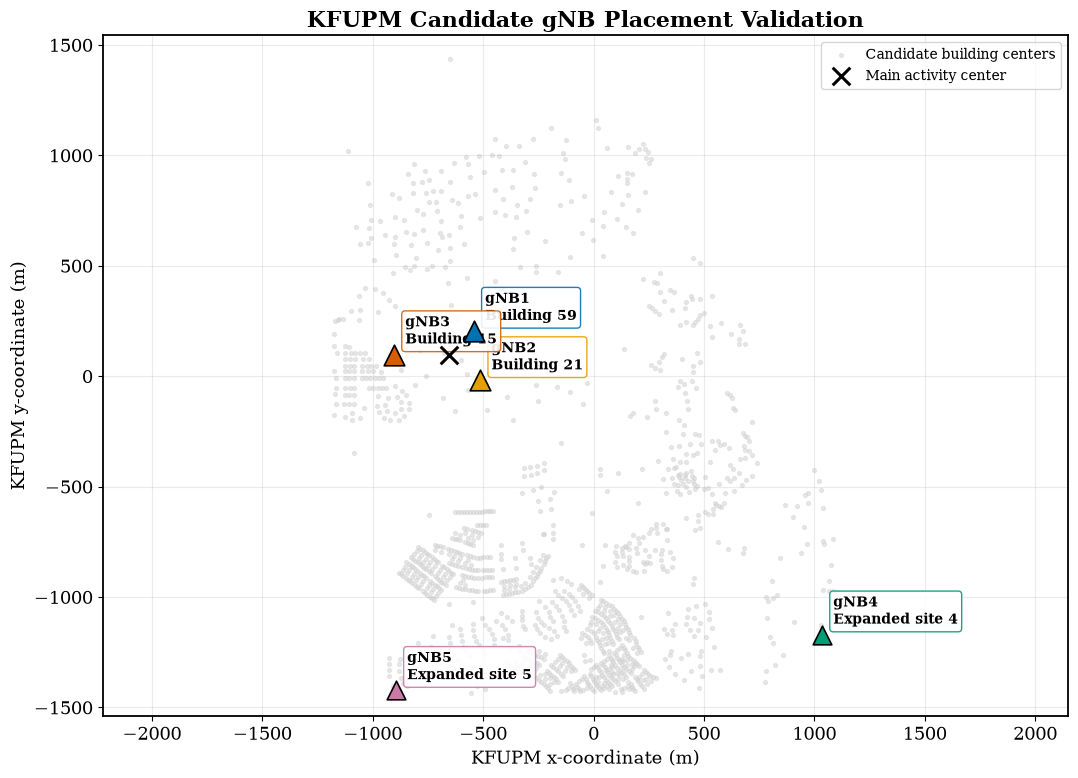

Validation figure saved to:
/home/afanali/wcnc_project/improved_experiment/figures/gnb_placement_validation.png


In [11]:
import matplotlib.pyplot as plt

# Display the selected scene objects and rooftop information
print("Selected expansion sites")
print("------------------------")

for item in GNB_CONFIG[3:]:
    print("Site:", item["id"])
    print("Source object:", item["source_scene_object"])
    print("Roof height:", round(item["roof_height_m"], 2), "m")
    print("Antenna position:", np.round(item["position_m"], 2))
    print()

# Candidate building centers
candidate_xy = np.array(
    [
        candidate["center_xy"]
        for candidate in building_candidates
    ]
)

# Plot validation map
plt.figure(figsize=(11, 8))

plt.scatter(
    candidate_xy[:, 0],
    candidate_xy[:, 1],
    s=8,
    color="#D0D0D0",
    alpha=0.45,
    label="Candidate building centers"
)

for item in GNB_CONFIG:
    position = item["position_m"]
    is_expanded = "EXPANDED" in item["id"]

    plt.scatter(
        position[0],
        position[1],
        s=180 if is_expanded else 220,
        color=item["color_hex"],
        edgecolor="black",
        linewidth=1.2,
        marker="^",
        zorder=5,
    )

    plt.annotate(
        f"{item['short_label']}\n{item['site_label']}",
        xy=(position[0], position[1]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="white",
            edgecolor=item["color_hex"],
            alpha=0.9,
        ),
    )

# Activity center
plt.scatter(
    ACTIVITY_CENTER_XY[0],
    ACTIVITY_CENTER_XY[1],
    marker="x",
    s=160,
    color="black",
    linewidth=2.2,
    label="Main activity center",
    zorder=6,
)

plt.xlabel("KFUPM x-coordinate (m)", fontsize=13)
plt.ylabel("KFUPM y-coordinate (m)", fontsize=13)
plt.title(
    "KFUPM Candidate gNB Placement Validation",
    fontsize=16,
    fontweight="bold",
)

plt.grid(alpha=0.25)
plt.axis("equal")
plt.legend(fontsize=10)
plt.tight_layout()

validation_path = (
    IMPROVED_FIGURES_DIR
    / "gnb_placement_validation.png"
)

plt.savefig(
    validation_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Validation figure saved to:")
print(validation_path)

In [12]:
# ============================================================
# Reset to the only currently verified gNB site
# ============================================================

b59_item = next(
    item
    for item in GNB_CONFIG
    if item["short_label"] == "gNB1"
)

b59_item["id"] = "gNB1_B59"
b59_item["short_label"] = "gNB1"
b59_item["building_name"] = (
    "Building 59 – Electrical Engineering Department"
)
b59_item["site_label"] = (
    "Building 59 – Electrical Engineering Department"
)
b59_item["role"] = "primary activity-area site"
b59_item["distance_from_b59_m"] = 0.0

GNB_CONFIG = [b59_item]

GNB_POSITIONS = {
    item["id"]: item["position_m"].tolist()
    for item in GNB_CONFIG
}

GNB_NAMES = [
    item["id"]
    for item in GNB_CONFIG
]

print("Verified gNB configuration")
print("--------------------------")

for item in GNB_CONFIG:
    print(
        item["id"],
        "|",
        item["building_name"],
        "|",
        np.round(item["position_m"], 2).tolist()
    )

Verified gNB configuration
--------------------------
gNB1_B59 | Building 59 – Electrical Engineering Department | [-541.7, 204.4, 69.0]


In [13]:
# ============================================================
# Discover meaningful building names in the KFUPM scene
# ============================================================

import re

def remove_material_suffix(name):
    return re.split(
        r"-itu_",
        name,
        maxsplit=1,
        flags=re.IGNORECASE
    )[0]


def readable_scene_name(name):
    name = remove_material_suffix(name)
    name = re.sub(r"[_-]+", " ", name)
    name = re.sub(r"\s+", " ", name)
    return name.strip()


meaningful_buildings = {}

for candidate in building_candidates:

    raw_name = candidate["object_name"]
    readable_name = readable_scene_name(raw_name)

    # Reject generic mesh identifiers
    if re.match(
        r"^element\s+\d+$",
        readable_name,
        flags=re.IGNORECASE
    ):
        continue

    # Keep only semantically meaningful objects
    name_lower = readable_name.lower()

    meaningful_keywords = [
        "building",
        "department",
        "library",
        "physics",
        "mathematics",
        "math",
        "administration",
        "research",
        "mosque",
        "hall",
        "tower",
        "college",
        "institute",
        "center",
    ]

    if not any(
        keyword in name_lower
        for keyword in meaningful_keywords
    ):
        continue

    # Keep the largest mesh if several material meshes exist
    if (
        readable_name not in meaningful_buildings
        or candidate["footprint_area_m2"]
        > meaningful_buildings[readable_name]["footprint_area_m2"]
    ):
        candidate_copy = dict(candidate)
        candidate_copy["readable_name"] = readable_name
        meaningful_buildings[readable_name] = candidate_copy

meaningful_buildings = list(
    meaningful_buildings.values()
)

b59_xy = np.array(
    [-541.7, 204.4],
    dtype=np.float64
)

meaningful_buildings.sort(
    key=lambda item: np.linalg.norm(
        item["center_xy"] - b59_xy
    )
)

print(
    "Meaningful named scene objects found:",
    len(meaningful_buildings)
)

print("\nNamed buildings and structures:")
print("--------------------------------")

for index, candidate in enumerate(
    meaningful_buildings,
    start=1
):

    distance = np.linalg.norm(
        candidate["center_xy"] - b59_xy
    )

    print(
        f"{index:03d}. "
        f"{candidate['readable_name'][:65]:65s} | "
        f"distance from B59: {distance:8.2f} m | "
        f"center: "
        f"{np.round(candidate['center_xy'], 2).tolist()}"
    )

Meaningful named scene objects found: 50

Named buildings and structures:
--------------------------------
001. Building 59 Electrical Engineering Dept                           | distance from B59:    27.01 m | center: [-530.28, 179.92]
002. Building 6 Physics department                                     | distance from B59:   135.46 m | center: [-673.02, 171.15]
003. Building 8 Main Liberary                                          | distance from B59:   141.89 m | center: [-598.71, 74.47]
004. Building 68 deanships                                             | distance from B59:   156.76 m | center: [-643.69, 323.44]
005. Building 7                                                        | distance from B59:   168.18 m | center: [-678.72, 106.89]
006. Building 9                                                        | distance from B59:   195.90 m | center: [-571.51, 10.78]
007. Building 5 Mathematics department                                 | distance from B59:   211.97 m | cent

In [14]:
# ============================================================
# Final verified five-gNB KFUPM layout
#
# gNB1: fixed at Building 59
# gNB2-gNB5: meaningful buildings at least 400 m away
# ============================================================

import re

B59_POSITION = np.array(
    [-541.7, 204.4, 69.0],
    dtype=np.float64
)

B59_XY = B59_POSITION[:2]
MIN_DISTANCE_FROM_B59_M = 400.0

# Exclude religious structures from the initial radio-site layout.
# They remain available for visualization.
excluded_keywords = [
    "mosque"
]

eligible_buildings = []

for candidate in meaningful_buildings:

    name_lower = candidate["readable_name"].lower()

    if any(
        keyword in name_lower
        for keyword in excluded_keywords
    ):
        continue

    distance_from_b59 = np.linalg.norm(
        candidate["center_xy"] - B59_XY
    )

    if distance_from_b59 < MIN_DISTANCE_FROM_B59_M:
        continue

    candidate_copy = dict(candidate)
    candidate_copy["distance_from_b59_m"] = distance_from_b59
    eligible_buildings.append(candidate_copy)

if len(eligible_buildings) < 4:
    raise RuntimeError(
        f"Only {len(eligible_buildings)} named buildings are "
        f"at least {MIN_DISTANCE_FROM_B59_M:.0f} m from B59."
    )

# Select four sites using farthest-point sampling.
# This spreads the sites spatially across the scene.
selected_buildings = []

coverage_anchors = [
    B59_XY.copy()
]

remaining_buildings = eligible_buildings.copy()

for _ in range(4):

    selected = max(
        remaining_buildings,
        key=lambda candidate: min(
            np.linalg.norm(
                candidate["center_xy"] - anchor
            )
            for anchor in coverage_anchors
        )
    )

    selected_buildings.append(selected)
    coverage_anchors.append(
        selected["center_xy"]
    )

    remaining_buildings.remove(selected)


def polish_building_label(label):
    """Create a clean label for the IEEE figure."""

    corrections = {
        "Building 59 Electrical Engineering Dept":
            "Building 59 – Electrical Engineering Department",

        "Building 5 Mathematics department":
            "Building 5 – Mathematics Department",

        "Building 6 Physics department":
            "Building 6 – Physics Department",

        "Building 8 Main Liberary":
            "Building 8 – Main Library",

        "Building 14 ITC":
            "Building 14 – ITC",

        "Building 15 Research Institute":
            "Building 15 – Research Institute",

        "Building 21 Administration":
            "Building 21 – Administration",

        "Building 22 Computer Science Department":
            "Building 22 – Computer Science Department",

        "Building 76 Petrolum Engineering Geosciences Department":
            "Building 76 – Petroleum Engineering and Geosciences Department",
    }

    if label in corrections:
        return corrections[label]

    # Remove mesh/subcomponent suffixes such as "Building 44 001"
    label = re.sub(
        r"^(Building\s+\d+)\s+\d+$",
        r"\1",
        label,
        flags=re.IGNORECASE
    )

    return label


def safe_identifier(label):
    """Create a clean Sionna device identifier."""
    identifier = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        label
    )
    return identifier.strip("_")[:35]


# Colorblind-friendly site colors
site_colors = [
    ("#0072B2", (0.000, 0.447, 0.698)),
    ("#E69F00", (0.902, 0.624, 0.000)),
    ("#D55E00", (0.835, 0.369, 0.000)),
    ("#009E73", (0.000, 0.620, 0.451)),
    ("#CC79A7", (0.800, 0.475, 0.655)),
]

# Fixed Building 59 site
FINAL_GNB_CONFIG = [
    {
        "id": "gNB1_B59",
        "short_label": "gNB1",
        "site_label": (
            "Building 59 – Electrical Engineering Department"
        ),
        "building_name": (
            "Building 59 – Electrical Engineering Department"
        ),
        "position_m": B59_POSITION,
        "color_hex": site_colors[0][0],
        "color_rgb": site_colors[0][1],
        "role": "primary activity-area site",
        "distance_from_b59_m": 0.0,
        "source_scene_object": (
            "Building_59_Electrical_Engineering_Dept-itu_brick"
        ),
    }
]

# Add four distant, meaningful buildings
for index, (candidate, color_info) in enumerate(
    zip(selected_buildings, site_colors[1:]),
    start=2
):

    building_label = polish_building_label(
        candidate["readable_name"]
    )

    gnb_position = np.array(
        [
            candidate["center_xy"][0],
            candidate["center_xy"][1],
            candidate["roof_height_m"]
            + ADDITIONAL_GNB_ROOFTOP_OFFSET_M,
        ],
        dtype=np.float64
    )

    FINAL_GNB_CONFIG.append(
        {
            "id": (
                f"gNB{index}_"
                f"{safe_identifier(building_label)}"
            ),
            "short_label": f"gNB{index}",
            "site_label": building_label,
            "building_name": building_label,
            "position_m": gnb_position,
            "color_hex": color_info[0],
            "color_rgb": color_info[1],
            "role": "campus-wide coverage site",
            "distance_from_b59": candidate[
                "distance_from_b59_m"
            ],
            "distance_from_b59_m": candidate[
                "distance_from_b59_m"
            ],
            "roof_height_m": candidate[
                "roof_height_m"
            ],
            "source_scene_object": candidate[
                "object_name"
            ],
        }
    )

# Activate final configuration
GNB_CONFIG = FINAL_GNB_CONFIG

GNB_POSITIONS = {
    item["id"]: item["position_m"].tolist()
    for item in GNB_CONFIG
}

GNB_NAMES = [
    item["id"]
    for item in GNB_CONFIG
]

print("Final verified KFUPM gNB layout")
print("--------------------------------")

for item in GNB_CONFIG:
    print(
        f"{item['short_label']:5s} | "
        f"{item['building_name'][:65]:65s} | "
        f"distance from B59: "
        f"{item['distance_from_b59_m']:8.2f} m | "
        f"position: "
        f"{np.round(item['position_m'], 2).tolist()}"
    )

print("\nTotal gNBs:", len(GNB_CONFIG))

Final verified KFUPM gNB layout
--------------------------------
gNB1  | Building 59 – Electrical Engineering Department                   | distance from B59:     0.00 m | position: [-541.7, 204.4, 69.0]
gNB2  | Building 44                                                       | distance from B59:  1103.95 m | position: [9.22, 1161.06, 53.16]
gNB3  | Building 54                                                       | distance from B59:   948.88 m | position: [398.56, 76.74, 46.07]
gNB4  | Building 29 Community Center                                      | distance from B59:   859.74 m | position: [-745.97, -630.72, 74.32]
gNB5  | Building 617                                                      | distance from B59:   661.19 m | position: [-726.94, 839.11, 60.5]

Total gNBs: 5


In [15]:
# ============================================================
# Add final gNB transmitters and UE receiver to the scene
# ============================================================

# Remove previously added radio devices if this cell is rerun
for tx_name in list(scene.transmitters.keys()):
    scene.remove(tx_name)

for rx_name in list(scene.receivers.keys()):
    scene.remove(rx_name)

# Common boresight target for the activity area
sector_target = (
    float(ACTIVITY_CENTER_XY[0]),
    float(ACTIVITY_CENTER_XY[1]),
    45.0,
)

# Add all gNB transmitters
for item in GNB_CONFIG:

    tx_position = tuple(
        float(value)
        for value in item["position_m"]
    )

    transmitter = rt.Transmitter(
        name=item["id"],
        position=tx_position,
        look_at=sector_target,
        power_dbm=RADIO_CONFIG[
            "gnb_transmit_power_dbm"
        ],
        color=item["color_rgb"],
        display_radius=10.0,
    )

    scene.add(transmitter)

# Add the initial UE receiver
ue_position = tuple(
    float(value)
    for value in UE_CONFIG["initial_position_m"]
)

receiver = rt.Receiver(
    name=UE_CONFIG["id"],
    position=ue_position,
    orientation=(0.0, 0.0, 0.0),
    color=UE_CONFIG["color_rgb"],
    display_radius=2.5,
)

scene.add(receiver)

print("Radio devices added successfully.")
print("Transmitters:", len(scene.transmitters))
print("Receivers:", len(scene.receivers))

print("\nTransmitters:")
for item in GNB_CONFIG:
    print(
        f"{item['short_label']} | "
        f"{item['building_name']} | "
        f"{np.round(item['position_m'], 2).tolist()}"
    )

print("\nUE position:")
print(np.round(UE_CONFIG["initial_position_m"], 2))

Radio devices added successfully.
Transmitters: 5
Receivers: 1

Transmitters:
gNB1 | Building 59 – Electrical Engineering Department | [-541.7, 204.4, 69.0]
gNB2 | Building 44 | [9.22, 1161.06, 53.16]
gNB3 | Building 54 | [398.56, 76.74, 46.07]
gNB4 | Building 29 Community Center | [-745.97, -630.72, 74.32]
gNB5 | Building 617 | [-726.94, 839.11, 60.5]

UE position:
[-600.  150.   45.]


In [16]:
# ============================================================
# Interactive KFUPM Digital-Twin Visualization
# ============================================================

import numpy as np
import plotly.graph_objects as go
import re

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------

def point3_to_numpy_local(point):
    return np.array(
        [
            float(point[0]),
            float(point[1]),
            float(point[2]),
        ],
        dtype=np.float64,
    )


def get_scene_bbox(scene_object):
    try:
        bbox = scene_object.mi_mesh.bbox()

        bbox_min = point3_to_numpy_local(bbox.min)
        bbox_max = point3_to_numpy_local(bbox.max)

        return bbox_min, bbox_max

    except Exception:
        return None, None


def add_building_box(
    figure,
    bbox_min,
    bbox_max,
    label,
    color="#BDBDBD",
    opacity=0.65,
    show_legend=False,
):
    """
    Add an extruded building box using the actual scene bounding box.
    """

    xmin, ymin, zmin = bbox_min
    xmax, ymax, zmax = bbox_max

    x = [
        xmin, xmax, xmax, xmin,
        xmin, xmax, xmax, xmin,
    ]

    y = [
        ymin, ymin, ymax, ymax,
        ymin, ymin, ymax, ymax,
    ]

    z = [
        zmin, zmin, zmin, zmin,
        zmax, zmax, zmax, zmax,
    ]

    # Cuboid triangular faces
    i = [
        0, 0, 4, 4,
        0, 0, 1, 1,
        2, 2, 3, 3,
    ]

    j = [
        1, 2, 5, 6,
        4, 5, 5, 6,
        6, 7, 7, 4,
    ]

    k = [
        2, 3, 6, 7,
        5, 1, 6, 2,
        7, 3, 4, 0,
    ]

    figure.add_trace(
        go.Mesh3d(
            x=x,
            y=y,
            z=z,
            i=i,
            j=j,
            k=k,
            color=color,
            opacity=opacity,
            flatshading=True,
            name="Buildings",
            showlegend=show_legend,
            hovertemplate=(
                f"<b>{label}</b><br>"
                "x: %{x:.1f} m<br>"
                "y: %{y:.1f} m<br>"
                "z: %{z:.1f} m"
                "<extra></extra>"
            ),
            lighting=dict(
                ambient=0.65,
                diffuse=0.75,
                specular=0.15,
            ),
        )
    )


def add_flat_rectangle(
    figure,
    bbox_min,
    bbox_max,
    label,
    color,
    opacity=0.45,
    show_legend=False,
):
    """
    Add a flat surface for roads, paths, or terrain.
    """

    xmin, ymin, zmin = bbox_min
    xmax, ymax, zmax = bbox_max

    z_surface = zmin + 0.5

    figure.add_trace(
        go.Mesh3d(
            x=[xmin, xmax, xmax, xmin],
            y=[ymin, ymin, ymax, ymax],
            z=[
                z_surface,
                z_surface,
                z_surface,
                z_surface,
            ],
            i=[0, 0],
            j=[1, 2],
            k=[2, 3],
            color=color,
            opacity=opacity,
            name=label,
            showlegend=show_legend,
            hovertemplate=(
                f"<b>{label}</b><br>"
                "x: %{x:.1f} m<br>"
                "y: %{y:.1f} m"
                "<extra></extra>"
            ),
        )
    )


# ------------------------------------------------------------
# Detect roads and vegetation from the actual scene
# ------------------------------------------------------------

ROAD_TOKENS = (
    "road",
    "street",
    "avenue",
    "asphalt",
    "pavement",
    "sidewalk",
    "parking",
    "path",
    "driveway",
)

VEGETATION_TOKENS = (
    "tree",
    "palm",
    "grass",
    "shrub",
    "bush",
    "plant",
    "vegetation",
    "lawn",
    "date",
)

road_objects = []
vegetation_objects = []

for object_name, scene_object in scene.objects.items():

    bbox_min, bbox_max = get_scene_bbox(scene_object)

    if bbox_min is None:
        continue

    name_lower = object_name.lower()
    object_size = bbox_max - bbox_min

    if any(token in name_lower for token in ROAD_TOKENS):

        # Ignore enormous terrain-like objects
        if object_size[0] < 1000 and object_size[1] < 1000:
            road_objects.append(
                {
                    "name": object_name,
                    "bbox_min": bbox_min,
                    "bbox_max": bbox_max,
                    "center_xy": 0.5 * (
                        bbox_min[:2] + bbox_max[:2]
                    ),
                }
            )

    if any(
        token in name_lower
        for token in VEGETATION_TOKENS
    ):

        vegetation_objects.append(
            {
                "name": object_name,
                "bbox_min": bbox_min,
                "bbox_max": bbox_max,
                "center_xy": 0.5 * (
                    bbox_min[:2] + bbox_max[:2]
                ),
            }
        )

print("Detected road-like scene objects:", len(road_objects))
print(
    "Detected vegetation-like scene objects:",
    len(vegetation_objects),
)


# ------------------------------------------------------------
# Route, if already available
# ------------------------------------------------------------

route_array = None

if "ue_route" in globals():

    try:
        route_array = np.asarray(ue_route, dtype=np.float64)

        if route_array.ndim != 2 or route_array.shape[1] < 3:
            route_array = None

    except Exception:
        route_array = None


# ------------------------------------------------------------
# Figure generator
# ------------------------------------------------------------

def make_digital_twin_figure(
    radius_m=None,
    title="KFUPM Digital Twin",
    output_filename="kfupm_digital_twin.html",
):

    figure = go.Figure()

    center_xy = np.asarray(
        ACTIVITY_CENTER_XY,
        dtype=np.float64,
    )

    def visible_xy(xy):
        if radius_m is None:
            return True

        return (
            np.linalg.norm(
                np.asarray(xy) - center_xy
            )
            <= radius_m
        )

    # --------------------------------------------------------
    # Select named buildings
    # --------------------------------------------------------

    visible_buildings = [
        candidate
        for candidate in meaningful_buildings
        if visible_xy(candidate["center_xy"])
    ]

    # --------------------------------------------------------
    # Select roads and vegetation
    # --------------------------------------------------------

    visible_roads = [
        road
        for road in road_objects
        if visible_xy(road["center_xy"])
    ]

    visible_vegetation = [
        vegetation
        for vegetation in vegetation_objects
        if visible_xy(vegetation["center_xy"])
    ]

    # Limit vegetation markers for browser performance
    visible_vegetation = sorted(
        visible_vegetation,
        key=lambda item: np.linalg.norm(
            item["center_xy"] - center_xy
        ),
    )[:500]

    # --------------------------------------------------------
    # Select gNBs
    # --------------------------------------------------------

    visible_gnbs = [
        item
        for item in GNB_CONFIG
        if visible_xy(item["position_m"][:2])
    ]

    # --------------------------------------------------------
    # Determine visualization bounds
    # --------------------------------------------------------

    xy_points = []

    for candidate in visible_buildings:
        xy_points.extend(
            [
                candidate["bbox_min"][:2],
                candidate["bbox_max"][:2],
            ]
        )

    for road in visible_roads:
        xy_points.extend(
            [
                road["bbox_min"][:2],
                road["bbox_max"][:2],
            ]
        )

    for item in visible_gnbs:
        xy_points.append(item["position_m"][:2])

    if route_array is not None:
        for point in route_array:
            if visible_xy(point[:2]):
                xy_points.append(point[:2])

    if len(xy_points) == 0:
        xy_points = [
            center_xy - np.array([300.0, 300.0]),
            center_xy + np.array([300.0, 300.0]),
        ]

    xy_points = np.asarray(xy_points)

    xmin = xy_points[:, 0].min() - 50.0
    xmax = xy_points[:, 0].max() + 50.0
    ymin = xy_points[:, 1].min() - 50.0
    ymax = xy_points[:, 1].max() + 50.0

    building_z_values = []

    for candidate in visible_buildings:
        building_z_values.extend(
            [
                candidate["bbox_min"][2],
                candidate["bbox_max"][2],
            ]
        )

    if building_z_values:
        ground_z = min(building_z_values) - 2.0
    else:
        ground_z = 0.0

    # --------------------------------------------------------
    # Ground plane
    # --------------------------------------------------------

    add_flat_rectangle(
        figure,
        np.array([xmin, ymin, ground_z]),
        np.array([xmax, ymax, ground_z + 0.1]),
        label="KFUPM terrain reference",
        color="#E8E3D3",
        opacity=0.30,
        show_legend=True,
    )

    # --------------------------------------------------------
    # Roads
    # --------------------------------------------------------

    for road_index, road in enumerate(visible_roads):

        add_flat_rectangle(
            figure,
            road["bbox_min"],
            road["bbox_max"],
            label="Roads and paved areas",
            color="#777777",
            opacity=0.52,
            show_legend=(road_index == 0),
        )

    # --------------------------------------------------------
    # Buildings
    # --------------------------------------------------------

    gnb_building_centers = [
        item["position_m"][:2]
        for item in GNB_CONFIG
    ]

    for building_index, candidate in enumerate(
        visible_buildings
    ):

        label = candidate.get(
            "readable_name",
            candidate["object_name"],
        )

        building_center = candidate["center_xy"]

        is_gnb_building = any(
            np.linalg.norm(
                building_center - gnb_center
            ) < 60.0
            for gnb_center in gnb_building_centers
        )

        building_color = (
            "#AFC6D8"
            if is_gnb_building
            else "#C9C9C9"
        )

        add_building_box(
            figure,
            candidate["bbox_min"],
            candidate["bbox_max"],
            label=label,
            color=building_color,
            opacity=0.72,
            show_legend=(
                building_index == 0
            ),
        )

    # --------------------------------------------------------
    # Vegetation
    # --------------------------------------------------------

    if visible_vegetation:

        vegetation_x = []
        vegetation_y = []
        vegetation_z = []
        vegetation_sizes = []
        vegetation_hover = []

        for vegetation in visible_vegetation:

            bbox_min = vegetation["bbox_min"]
            bbox_max = vegetation["bbox_max"]
            center = 0.5 * (
                bbox_min + bbox_max
            )

            object_width = max(
                bbox_max[0] - bbox_min[0],
                bbox_max[1] - bbox_min[1],
                1.0,
            )

            vegetation_x.append(center[0])
            vegetation_y.append(center[1])
            vegetation_z.append(bbox_max[2])
            vegetation_sizes.append(
                float(np.clip(
                    3.0 + object_width * 0.4,
                    3.0,
                    11.0,
                ))
            )
            vegetation_hover.append(
                vegetation["name"]
            )

        figure.add_trace(
            go.Scatter3d(
                x=vegetation_x,
                y=vegetation_y,
                z=vegetation_z,
                mode="markers",
                name="Vegetation",
                showlegend=True,
                marker=dict(
                    size=vegetation_sizes,
                    color="#2E7D32",
                    opacity=0.75,
                    symbol="circle",
                ),
                text=vegetation_hover,
                hovertemplate=(
                    "<b>Vegetation</b><br>"
                    "%{text}<br>"
                    "x: %{x:.1f} m<br>"
                    "y: %{y:.1f} m"
                    "<extra></extra>"
                ),
            )
        )

    # --------------------------------------------------------
    # UE route
    # --------------------------------------------------------

    if route_array is not None:

        route_visible = np.array(
            [
                point
                for point in route_array
                if visible_xy(point[:2])
            ]
        )

        if len(route_visible) > 1:

            figure.add_trace(
                go.Scatter3d(
                    x=route_visible[:, 0],
                    y=route_visible[:, 1],
                    z=route_visible[:, 2] + 2.0,
                    mode="lines",
                    name="UE route",
                    line=dict(
                        color="#111111",
                        width=7,
                    ),
                    hovertemplate=(
                        "UE route<br>"
                        "x: %{x:.1f} m<br>"
                        "y: %{y:.1f} m"
                        "<extra></extra>"
                    ),
                )
            )

    # --------------------------------------------------------
    # gNB markers
    # --------------------------------------------------------

    if visible_gnbs:

        figure.add_trace(
            go.Scatter3d(
                x=[
                    item["position_m"][0]
                    for item in visible_gnbs
                ],
                y=[
                    item["position_m"][1]
                    for item in visible_gnbs
                ],
                z=[
                    item["position_m"][2]
                    for item in visible_gnbs
                ],
                mode="markers+text",
                name="gNBs",
                text=[
                    item["short_label"]
                    for item in visible_gnbs
                ],
                textposition="top center",
                marker=dict(
                    size=12,
                    symbol="diamond",
                    color=[
                        item["color_hex"]
                        for item in visible_gnbs
                    ],
                    line=dict(
                        color="black",
                        width=1.5,
                    ),
                ),
                customdata=[
                    [
                        item["building_name"],
                        item["position_m"][2],
                    ]
                    for item in visible_gnbs
                ],
                hovertemplate=(
                    "<b>%{text}</b><br>"
                    "Site: %{customdata[0]}<br>"
                    "x: %{x:.1f} m<br>"
                    "y: %{y:.1f} m<br>"
                    "antenna height: %{customdata[1]:.1f} m"
                    "<extra></extra>"
                ),
            )
        )

    # --------------------------------------------------------
    # UE marker
    # --------------------------------------------------------

    ue_position = np.asarray(
        UE_CONFIG["initial_position_m"],
        dtype=np.float64,
    )

    if visible_xy(ue_position[:2]):

        figure.add_trace(
            go.Scatter3d(
                x=[ue_position[0]],
                y=[ue_position[1]],
                z=[ue_position[2]],
                mode="markers+text",
                name="UE vehicle",
                text=["UE"],
                textposition="top center",
                marker=dict(
                    size=10,
                    symbol="circle",
                    color="#000000",
                    line=dict(
                        color="white",
                        width=2,
                    ),
                ),
                hovertemplate=(
                    "<b>UE vehicle</b><br>"
                    "x: %{x:.1f} m<br>"
                    "y: %{y:.1f} m<br>"
                    "z: %{z:.1f} m"
                    "<extra></extra>"
                ),
            )
        )

    # --------------------------------------------------------
    # Professional interactive layout
    # --------------------------------------------------------

    figure.update_layout(
        title=dict(
            text=title,
            x=0.5,
            xanchor="center",
            font=dict(
                size=20,
                family="Arial",
            ),
        ),
        template="plotly_white",
        width=1250,
        height=850,
        margin=dict(
            l=0,
            r=0,
            t=70,
            b=0,
        ),
        legend=dict(
            x=0.01,
            y=0.99,
            bgcolor="rgba(255,255,255,0.85)",
            bordercolor="#777777",
            borderwidth=1,
        ),
        scene=dict(
            xaxis_title="KFUPM x-coordinate (m)",
            yaxis_title="KFUPM y-coordinate (m)",
            zaxis_title="Elevation (m)",
            aspectmode="data",
            camera=dict(
                eye=dict(
                    x=1.45,
                    y=1.45,
                    z=1.15,
                )
            ),
            xaxis=dict(
                showgrid=True,
                gridcolor="#D9D9D9",
                zeroline=False,
            ),
            yaxis=dict(
                showgrid=True,
                gridcolor="#D9D9D9",
                zeroline=False,
            ),
            zaxis=dict(
                showgrid=True,
                gridcolor="#D9D9D9",
                zeroline=False,
            ),
        ),
    )

    output_path = (
        IMPROVED_FIGURES_DIR
        / output_filename
    )

    figure.write_html(
        str(output_path),
        include_plotlyjs=True,
        full_html=True,
    )

    print("\nFigure saved to:")
    print(output_path)
    print("Buildings shown:", len(visible_buildings))
    print("Road objects shown:", len(visible_roads))
    print("Vegetation objects shown:", len(visible_vegetation))
    print("gNBs shown:", len(visible_gnbs))

    return figure


# ============================================================
# Generate overview and close-up figures
# ============================================================

overview_figure = make_digital_twin_figure(
    radius_m=None,
    title="KFUPM Digital Twin — Campus-Wide gNB Deployment",
    output_filename=(
        "kfupm_digital_twin_campus_overview.html"
    ),
)

focus_figure = make_digital_twin_figure(
    radius_m=1000.0,
    title=(
        "KFUPM Digital Twin — "
        "Activity-Area Close-Up"
    ),
    output_filename=(
        "kfupm_digital_twin_activity_area.html"
    ),
)

# Display the close-up interactively in VS Code
focus_figure.show()

Detected road-like scene objects: 2
Detected vegetation-like scene objects: 0

Figure saved to:
/home/afanali/wcnc_project/improved_experiment/figures/kfupm_digital_twin_campus_overview.html
Buildings shown: 50
Road objects shown: 2
Vegetation objects shown: 0
gNBs shown: 5

Figure saved to:
/home/afanali/wcnc_project/improved_experiment/figures/kfupm_digital_twin_activity_area.html
Buildings shown: 44
Road objects shown: 2
Vegetation objects shown: 0
gNBs shown: 3


In [17]:
# ============================================================
# Locate gNB and UE icons from the previous notebook
# ============================================================

from pathlib import Path

asset_search_roots = [
    IMPROVED_ROOT / "assets",
    PROJECT_ROOT / "figures",
    PROJECT_ROOT / "data",
    PROJECT_ROOT / "notebooks",
]

image_files = []

for root in asset_search_roots:
    if root.exists():
        image_files.extend(
            root.rglob("*.png")
        )

# Remove duplicate paths
image_files = sorted(set(image_files))

gnb_icon_candidates = [
    path for path in image_files
    if any(
        token in path.name.lower()
        for token in ["gnodeb", "gnb", "base_station"]
    )
]

ue_icon_candidates = [
    path for path in image_files
    if any(
        token in path.name.lower()
        for token in ["car", "ue", "vehicle"]
    )
]

print("gNB icon candidates:")
for path in gnb_icon_candidates:
    print(path)

print("\nUE icon candidates:")
for path in ue_icon_candidates:
    print(path)

if not gnb_icon_candidates:
    raise FileNotFoundError(
        "No gNB PNG was found. Copy the previous gNB image into "
        f"{IMPROVED_ROOT / 'assets'}."
    )

if not ue_icon_candidates:
    raise FileNotFoundError(
        "No UE/car PNG was found. Copy the previous UE image into "
        f"{IMPROVED_ROOT / 'assets'}."
    )

GNB_ICON_PATH = gnb_icon_candidates[0]
UE_ICON_PATH = ue_icon_candidates[0]

print("\nSelected gNB icon:", GNB_ICON_PATH)
print("Selected UE icon:", UE_ICON_PATH)

gNB icon candidates:
/home/afanali/wcnc_project/figures/gnb_icon.png

UE icon candidates:
/home/afanali/wcnc_project/figures/car_icon.png

Selected gNB icon: /home/afanali/wcnc_project/figures/gnb_icon.png
Selected UE icon: /home/afanali/wcnc_project/figures/car_icon.png


In [18]:
# ============================================================
# Improved road and vegetation detection
# Uses both object names and radio-material names
# ============================================================

ROAD_TOKENS = (
    "road",
    "street",
    "avenue",
    "asphalt",
    "pavement",
    "sidewalk",
    "parking",
    "path",
    "driveway",
    "curb",
)

VEGETATION_TOKENS = (
    "tree",
    "palm",
    "grass",
    "shrub",
    "bush",
    "plant",
    "vegetation",
    "lawn",
    "leaf",
    "leaves",
    "foliage",
    "trunk",
    "wood",
    "garden",
)

road_objects = []
vegetation_objects = []

matched_road_names = []
matched_vegetation_names = []

for object_name, scene_object in scene.objects.items():

    bbox_min, bbox_max = get_scene_bbox(scene_object)

    if bbox_min is None:
        continue

    # Inspect both the mesh name and its assigned radio material
    object_text = str(object_name).lower()

    try:
        material_text = str(
            scene_object.radio_material
        ).lower()
    except Exception:
        material_text = ""

    searchable_text = (
        object_text + " " + material_text
    )

    object_size = bbox_max - bbox_min
    footprint_area = (
        object_size[0] * object_size[1]
    )

    center_xy = 0.5 * (
        bbox_min[:2] + bbox_max[:2]
    )

    # Roads and paved areas
    if any(
        token in searchable_text
        for token in ROAD_TOKENS
    ):

        # Remove extremely large terrain-like meshes
        if (
            object_size[0] < 1000.0
            and object_size[1] < 1000.0
            and footprint_area > 10.0
        ):
            road_objects.append(
                {
                    "name": object_name,
                    "material": material_text,
                    "bbox_min": bbox_min,
                    "bbox_max": bbox_max,
                    "center_xy": center_xy,
                }
            )

            matched_road_names.append(
                (
                    object_name,
                    material_text,
                )
            )

    # Vegetation
    if any(
        token in searchable_text
        for token in VEGETATION_TOKENS
    ):

        vegetation_objects.append(
            {
                "name": object_name,
                "material": material_text,
                "bbox_min": bbox_min,
                "bbox_max": bbox_max,
                "center_xy": center_xy,
            }
        )

        matched_vegetation_names.append(
            (
                object_name,
                material_text,
            )
        )

print("Detected road/pavement objects:")
print(len(road_objects))

print("\nDetected vegetation objects:")
print(len(vegetation_objects))

print("\nExample road matches:")
for name, material in matched_road_names[:15]:
    print("-", name, "|", material)

print("\nExample vegetation matches:")
for name, material in matched_vegetation_names[:15]:
    print("-", name, "|", material)

Detected road/pavement objects:
2

Detected vegetation objects:
0

Example road matches:
- Building_74_Parking-itu_brick | ituradiomaterial type=brick
                 eta_r=3.910
                 sigma=0.029
                 thickness=0.100
                 scattering_coefficient=0.000
                 xpd_coefficient=0.000
- Building_74_Parking-itu_metal | ituradiomaterial type=metal
                 eta_r=1.000
                 sigma=10000000.000
                 thickness=0.100
                 scattering_coefficient=0.000
                 xpd_coefficient=0.000

Example vegetation matches:


In [19]:
# ============================================================
# Dense UE trajectory bank for the improved experiment
# ============================================================

ROUTE_CONFIG = {
    "num_trajectories": 6,
    "points_per_trajectory": 240,
    "ue_height_m": float(
        UE_CONFIG["initial_position_m"][2]
    ),
    "site_offset_m": 35.0,
    "time_step_s": 0.5,
    "speeds_mps": [5.0, 8.0, 12.0],
    "random_seed": 2026,
}

np.random.seed(
    ROUTE_CONFIG["random_seed"]
)


def sample_polyline(waypoints_xy, num_points):
    """
    Uniformly sample a polyline by travelled distance.
    """

    waypoints_xy = np.asarray(
        waypoints_xy,
        dtype=np.float64,
    )

    segment_vectors = np.diff(
        waypoints_xy,
        axis=0,
    )

    segment_lengths = np.linalg.norm(
        segment_vectors,
        axis=1,
    )

    cumulative_distance = np.concatenate(
        [
            [0.0],
            np.cumsum(segment_lengths),
        ]
    )

    total_distance = cumulative_distance[-1]

    target_distances = np.linspace(
        0.0,
        total_distance,
        num_points,
    )

    sampled_points = []

    for distance in target_distances:

        segment_index = np.searchsorted(
            cumulative_distance,
            distance,
            side="right",
        ) - 1

        segment_index = int(
            np.clip(
                segment_index,
                0,
                len(segment_lengths) - 1,
            )
        )

        segment_start_distance = (
            cumulative_distance[segment_index]
        )

        segment_length = max(
            segment_lengths[segment_index],
            1e-9,
        )

        interpolation_factor = (
            distance - segment_start_distance
        ) / segment_length

        point = (
            waypoints_xy[segment_index]
            + interpolation_factor
            * segment_vectors[segment_index]
        )

        sampled_points.append(point)

    return np.asarray(
        sampled_points,
        dtype=np.float64,
    )


# ------------------------------------------------------------
# Build route waypoints near the five gNB sites
# ------------------------------------------------------------

site_waypoints = []

for item in GNB_CONFIG:

    site_xy = np.asarray(
        item["position_m"][:2],
        dtype=np.float64,
    )

    direction_to_activity_center = (
        np.asarray(ACTIVITY_CENTER_XY)
        - site_xy
    )

    direction_norm = np.linalg.norm(
        direction_to_activity_center
    )

    if direction_norm > 1e-6:
        direction_unit = (
            direction_to_activity_center
            / direction_norm
        )
    else:
        direction_unit = np.zeros(2)

    # Place the UE route near, but not on top of,
    # each gNB building.
    roadside_xy = (
        site_xy
        + ROUTE_CONFIG["site_offset_m"]
        * direction_unit
    )

    site_waypoints.append(
        {
            "gNB": item["short_label"],
            "building": item["building_name"],
            "xy": roadside_xy,
        }
    )

# ------------------------------------------------------------
# Order waypoints using a nearest-neighbor route
# ------------------------------------------------------------

ordered_waypoints = [
    site_waypoints[0]
]

remaining_waypoints = site_waypoints[1:].copy()

while remaining_waypoints:

    current_xy = ordered_waypoints[-1]["xy"]

    next_waypoint = min(
        remaining_waypoints,
        key=lambda item: np.linalg.norm(
            item["xy"] - current_xy
        )
    )

    ordered_waypoints.append(next_waypoint)
    remaining_waypoints.remove(next_waypoint)

base_waypoints_xy = np.array(
    [
        item["xy"]
        for item in ordered_waypoints
    ],
    dtype=np.float64,
)

print("UE route waypoint order:")
for item in ordered_waypoints:
    print(
        f"{item['gNB']} | "
        f"{item['building']} | "
        f"{np.round(item['xy'], 2).tolist()}"
    )

# ------------------------------------------------------------
# Generate six spatially different trajectories
# ------------------------------------------------------------

trajectory_offsets = np.array(
    [
        [-25.0, -20.0],
        [-15.0, 15.0],
        [0.0, 0.0],
        [15.0, -10.0],
        [25.0, 20.0],
        [40.0, -25.0],
    ],
    dtype=np.float64,
)

route_bank = []

for trajectory_id in range(
    ROUTE_CONFIG["num_trajectories"]
):

    offset = trajectory_offsets[
        trajectory_id
        % len(trajectory_offsets)
    ]

    shifted_waypoints = (
        base_waypoints_xy + offset
    )

    route_xy = sample_polyline(
        shifted_waypoints,
        ROUTE_CONFIG[
            "points_per_trajectory"
        ],
    )

    route_z = np.full(
        (
            len(route_xy),
            1,
        ),
        ROUTE_CONFIG["ue_height_m"],
        dtype=np.float64,
    )

    route_xyz = np.hstack(
        [
            route_xy,
            route_z,
        ]
    )

    route_bank.append(
        {
            "trajectory_id": trajectory_id,
            "speed_mps": ROUTE_CONFIG[
                "speeds_mps"
            ][
                trajectory_id
                % len(ROUTE_CONFIG["speeds_mps"])
            ],
            "positions": route_xyz,
            "offset_xy": offset,
        }
    )

# Use trajectory 0 for the current interactive map
ue_route = route_bank[0]["positions"]

total_observations = sum(
    len(route["positions"])
    for route in route_bank
)

print("\nTrajectory bank created.")
print("Number of trajectories:", len(route_bank))
print(
    "Points per trajectory:",
    ROUTE_CONFIG["points_per_trajectory"],
)
print("Total UE observations:", total_observations)
print(
    "First UE position:",
    np.round(route_bank[0]["positions"][0], 2)
)
print(
    "Last UE position:",
    np.round(route_bank[0]["positions"][-1], 2)
)

# ------------------------------------------------------------
# Save trajectory bank separately
# ------------------------------------------------------------

trajectory_positions = np.stack(
    [
        route["positions"]
        for route in route_bank
    ],
    axis=0,
)

trajectory_speeds = np.array(
    [
        route["speed_mps"]
        for route in route_bank
    ],
    dtype=np.float64,
)

trajectory_offsets_array = np.stack(
    [
        route["offset_xy"]
        for route in route_bank
    ],
    axis=0,
)

trajectory_file = (
    IMPROVED_DATA_DIR
    / "dense_ue_trajectory_bank.npz"
)

np.savez_compressed(
    trajectory_file,
    positions=trajectory_positions,
    speeds_mps=trajectory_speeds,
    offsets_xy=trajectory_offsets_array,
    time_step_s=ROUTE_CONFIG["time_step_s"],
)

print("\nTrajectory data saved to:")
print(trajectory_file)

UE route waypoint order:
gNB1 | Building 59 – Electrical Engineering Department | [-566.55, 179.76]
gNB5 | Building 617 | [-723.47, 804.29]
gNB2 | Building 44 | [-9.23, 1131.32]
gNB3 | Building 54 | [363.56, 77.33]
gNB4 | Building 29 Community Center | [-741.5, -596.01]

Trajectory bank created.
Number of trajectories: 6
Points per trajectory: 240
Total UE observations: 1440
First UE position: [-591.55  159.76   45.  ]
Last UE position: [-766.5  -616.01   45.  ]

Trajectory data saved to:
/home/afanali/wcnc_project/improved_experiment/data/dense_ue_trajectory_bank.npz


In [20]:
# ============================================================
# Add visualization-only roads and vegetation
# ============================================================

if "ue_route" not in globals():
    raise NameError(
        "ue_route is not defined. Run the dense trajectory cell first."
    )

if "make_icon_digital_twin_map" not in globals():
    raise NameError(
        "Run the interactive PNG map function cell first."
    )

# ------------------------------------------------------------
# Schematic road corridor derived from the UE route
# ------------------------------------------------------------

route_for_roads = np.asarray(
    ue_route,
    dtype=np.float64,
)

# Reduce the number of rectangles for browser performance
road_step = max(
    1,
    len(route_for_roads) // 40
)

road_centerline = route_for_roads[
    ::road_step
]

if not np.array_equal(
    road_centerline[-1],
    route_for_roads[-1],
):
    road_centerline = np.vstack(
        [
            road_centerline,
            route_for_roads[-1],
        ]
    )

schematic_road_objects = []

road_half_width_m = 11.0

for point_a, point_b in zip(
    road_centerline[:-1],
    road_centerline[1:],
):

    xmin = min(point_a[0], point_b[0])
    xmax = max(point_a[0], point_b[0])
    ymin = min(point_a[1], point_b[1])
    ymax = max(point_a[1], point_b[1])

    schematic_road_objects.append(
        {
            "name": (
                "Route-aligned roadway corridor "
                "(schematic)"
            ),
            "material": "visualization_only",
            "bbox_min": np.array(
                [
                    xmin - road_half_width_m,
                    ymin - road_half_width_m,
                    0.0,
                ],
                dtype=np.float64,
            ),
            "bbox_max": np.array(
                [
                    xmax + road_half_width_m,
                    ymax + road_half_width_m,
                    0.3,
                ],
                dtype=np.float64,
            ),
            "center_xy": np.array(
                [
                    0.5 * (xmin + xmax),
                    0.5 * (ymin + ymax),
                ],
                dtype=np.float64,
            ),
        }
    )

# Use detected roads if available; otherwise use the
# route-aligned schematic roadway
if len(road_objects) == 0:
    road_objects = schematic_road_objects
    roads_are_schematic = True
else:
    roads_are_schematic = False


# ------------------------------------------------------------
# Schematic vegetation clusters around building footprints
# ------------------------------------------------------------

if len(vegetation_objects) == 0:

    rng = np.random.default_rng(2026)
    schematic_vegetation_objects = []

    for building_index, building in enumerate(
        meaningful_buildings
    ):

        building_center = np.asarray(
            building["center_xy"],
            dtype=np.float64,
        )

        bbox_min = np.asarray(
            building["bbox_min"],
            dtype=np.float64,
        )

        bbox_max = np.asarray(
            building["bbox_max"],
            dtype=np.float64,
        )

        # Three deterministic landscaping points around
        # each named building
        for plant_index in range(3):

            angle = (
                2.0
                * np.pi
                * plant_index
                / 3.0
                + 0.35
            )

            radius = rng.uniform(
                18.0,
                38.0,
            )

            candidate_xy = (
                building_center
                + radius
                * np.array(
                    [
                        np.cos(angle),
                        np.sin(angle),
                    ]
                )
            )

            # Avoid placing a vegetation marker inside
            # the building footprint
            if (
                bbox_min[0] - 3.0
                <= candidate_xy[0]
                <= bbox_max[0] + 3.0
                and
                bbox_min[1] - 3.0
                <= candidate_xy[1]
                <= bbox_max[1] + 3.0
            ):
                candidate_xy = (
                    building_center
                    + 1.8
                    * radius
                    * np.array(
                        [
                            np.cos(angle),
                            np.sin(angle),
                        ]
                    )
                )

            schematic_vegetation_objects.append(
                {
                    "name": (
                        "Landscaping tree cluster "
                        "(schematic)"
                    ),
                    "material": "visualization_only",
                    "bbox_min": np.array(
                        [
                            candidate_xy[0] - 2.0,
                            candidate_xy[1] - 2.0,
                            0.0,
                        ],
                        dtype=np.float64,
                    ),
                    "bbox_max": np.array(
                        [
                            candidate_xy[0] + 2.0,
                            candidate_xy[1] + 2.0,
                            5.0,
                        ],
                        dtype=np.float64,
                    ),
                    "center_xy": candidate_xy,
                }
            )

    vegetation_objects = schematic_vegetation_objects
    vegetation_is_schematic = True

else:
    vegetation_is_schematic = False


print(
    "Road objects used:",
    len(road_objects),
)

print(
    "Vegetation objects used:",
    len(vegetation_objects),
)

print(
    "Road layer:",
    "schematic route-aligned"
    if roads_are_schematic
    else "scene-derived",
)

print(
    "Vegetation layer:",
    "schematic landscaping"
    if vegetation_is_schematic
    else "scene-derived",
)


# ============================================================
# Regenerate the maps
# ============================================================

icon_overview = make_icon_digital_twin_map(
    radius_m=None,
    title=(
        "KFUPM Digital Twin — "
        "Five-gNB Campus Overview"
    ),
    output_filename=(
        "kfupm_digital_twin_icon_overview_context.html"
    ),
)

icon_focus = make_icon_digital_twin_map(
    radius_m=1000.0,
    title=(
        "KFUPM Digital Twin — "
        "Activity-Area Close-Up"
    ),
    output_filename=(
        "kfupm_digital_twin_icon_activity_context.html"
    ),
)

# Make the visualization-layer labels explicit
for figure in [
    icon_overview,
    icon_focus,
]:

    for trace in figure.data:

        if trace.name == "Roads":
            trace.name = (
                "Road corridor (schematic)"
            )

        if trace.name == "Vegetation":
            trace.name = (
                "Landscaping (schematic)"
            )

    figure.write_html(
        str(
            IMPROVED_FIGURES_DIR
            / (
                "kfupm_digital_twin_context_"
                + (
                    "overview.html"
                    if figure is icon_overview
                    else "activity_area.html"
                )
            )
        ),
        include_plotlyjs=True,
        full_html=True,
    )

print("\nUpdated figures saved in:")
print(IMPROVED_FIGURES_DIR)

icon_focus.show()

NameError: Run the interactive PNG map function cell first.

In [21]:
# ============================================================
# Five-gNB GPU ray-tracing pilot — corrected version
# ============================================================

import json
import time
import numpy as np

# Create a deterministic path solver
path_solver = rt.PathSolver(
    deterministic=True
)

# Get the UE receiver from the scene
ue_receiver = scene.get(
    UE_CONFIG["id"]
)

# Select representative points along trajectory 0
pilot_indices = np.linspace(
    0,
    len(ue_route) - 1,
    8,
    dtype=int,
)

pilot_records = []

pilot_start_time = time.perf_counter()

try:

    for pilot_number, route_index in enumerate(
        pilot_indices,
        start=1,
    ):

        # Ensure a native Python integer
        route_index = int(route_index)

        ue_position = np.asarray(
            ue_route[route_index],
            dtype=np.float64,
        )

        # Move the UE receiver
        ue_receiver.position = tuple(
            float(value)
            for value in ue_position
        )

        point_start_time = time.perf_counter()

        # Use a native Python integer for Dr.Jit
        pilot_seed = int(
            DATA_CONFIG["random_seed"]
        ) + route_index

        paths = path_solver(
            scene=scene,
            max_depth=int(
                DATA_CONFIG["max_depth"]
            ),
            los=bool(
                DATA_CONFIG["los"]
            ),
            specular_reflection=bool(
                DATA_CONFIG[
                    "specular_reflection"
                ]
            ),
            diffuse_reflection=bool(
                DATA_CONFIG[
                    "diffuse_reflection"
                ]
            ),
            refraction=bool(
                DATA_CONFIG["refraction"]
            ),
            synthetic_array=bool(
                DATA_CONFIG[
                    "synthetic_array"
                ]
            ),
            seed=pilot_seed,
        )

        point_runtime = (
            time.perf_counter()
            - point_start_time
        )

        # Convert Dr.Jit outputs to NumPy
        valid_array = np.asarray(
            paths.valid
        )

        delay_array = np.asarray(
            paths.tau
        )

        # Remove the source/receiver batch dimension
        if (
            valid_array.ndim == 3
            and valid_array.shape[0] == 1
        ):
            valid_array = valid_array[0]

        if (
            delay_array.ndim == 3
            and delay_array.shape[0] == 1
        ):
            delay_array = delay_array[0]

        valid_counts = []
        minimum_delays = []

        for gnb_index in range(
            len(GNB_CONFIG)
        ):

            valid_mask = (
                valid_array[gnb_index] > 0
            )

            valid_count = int(
                np.sum(valid_mask)
            )

            valid_counts.append(
                valid_count
            )

            if valid_count > 0:

                valid_delays = (
                    delay_array[gnb_index][
                        valid_mask
                    ]
                )

                valid_delays = valid_delays[
                    np.isfinite(valid_delays)
                ]

                valid_delays = valid_delays[
                    valid_delays >= 0.0
                ]

                if len(valid_delays) > 0:
                    minimum_delays.append(
                        float(
                            np.min(
                                valid_delays
                            )
                        )
                    )
                else:
                    minimum_delays.append(
                        None
                    )

            else:
                minimum_delays.append(
                    None
                )

        pilot_record = {
            "pilot_number": int(
                pilot_number
            ),
            "route_index": route_index,
            "position_xyz_m": (
                ue_position.tolist()
            ),
            "valid_path_counts": (
                valid_counts
            ),
            "minimum_delays_s": (
                minimum_delays
            ),
            "runtime_s": float(
                point_runtime
            ),
        }

        pilot_records.append(
            pilot_record
        )

        print(
            f"Pilot {pilot_number}/"
            f"{len(pilot_indices)} | "
            f"route index {route_index:3d} | "
            f"valid paths {valid_counts} | "
            f"time {point_runtime:.2f} s"
        )

finally:

    # Always restore the initial UE position
    ue_receiver.position = tuple(
        float(value)
        for value in UE_CONFIG[
            "initial_position_m"
        ]
    )


total_pilot_runtime = (
    time.perf_counter()
    - pilot_start_time
)

pilot_output = {
    "number_of_gnbs": len(GNB_CONFIG),
    "number_of_pilot_points": len(
        pilot_indices
    ),
    "total_runtime_s": float(
        total_pilot_runtime
    ),
    "average_runtime_s": float(
        total_pilot_runtime
        / len(pilot_indices)
    ),
    "records": pilot_records,
}

pilot_file = (
    IMPROVED_RESULTS_DIR
    / "five_gnb_ray_tracing_pilot.json"
)

with open(
    pilot_file,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        pilot_output,
        file,
        indent=2,
    )

print("\nFive-gNB pilot completed.")
print(
    "Average runtime per point:",
    round(
        pilot_output[
            "average_runtime_s"
        ],
        3,
    ),
    "seconds",
)
print("Pilot results saved to:")
print(pilot_file)

Pilot 1/8 | route index   0 | valid paths [3, 0, 0, 2, 1] | time 1.95 s
Pilot 2/8 | route index  34 | valid paths [1, 0, 0, 1, 15] | time 1.46 s
Pilot 3/8 | route index  68 | valid paths [3, 2, 1, 0, 12] | time 1.36 s
Pilot 4/8 | route index 102 | valid paths [3, 18, 2, 1, 0] | time 1.41 s
Pilot 5/8 | route index 136 | valid paths [3, 5, 3, 1, 3] | time 1.42 s
Pilot 6/8 | route index 170 | valid paths [5, 1, 7, 1, 5] | time 1.40 s
Pilot 7/8 | route index 204 | valid paths [0, 0, 0, 1, 0] | time 1.27 s
Pilot 8/8 | route index 239 | valid paths [0, 0, 0, 3, 1] | time 1.29 s

Five-gNB pilot completed.
Average runtime per point: 1.445 seconds
Pilot results saved to:
/home/afanali/wcnc_project/improved_experiment/results/five_gnb_ray_tracing_pilot.json


In [ ]:
# ============================================================
# Dense five-gNB RF dataset generation with checkpointing
# ============================================================

import csv
import json
import time
import numpy as np

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

N_GNBS = len(GNB_CONFIG)
CHECKPOINT_INTERVAL = 50

if "route_bank" not in globals():
    raise NameError(
        "route_bank is not defined. "
        "Run the dense UE trajectory cell first."
    )

if N_GNBS != 5:
    print(
        "Warning: expected five gNBs, found",
        N_GNBS,
    )

# ------------------------------------------------------------
# Flatten all trajectories into one observation list
# ------------------------------------------------------------

observation_rows = []

for trajectory in route_bank:

    trajectory_id = int(
        trajectory["trajectory_id"]
    )

    speed_mps = float(
        trajectory["speed_mps"]
    )

    positions = np.asarray(
        trajectory["positions"],
        dtype=np.float64,
    )

    for route_index, position in enumerate(
        positions
    ):

        observation_rows.append(
            {
                "trajectory_id": trajectory_id,
                "route_index": int(route_index),
                "speed_mps": speed_mps,
                "position_xyz_m": position,
            }
        )

N_OBSERVATIONS = len(
    observation_rows
)

positions = np.asarray(
    [
        row["position_xyz_m"]
        for row in observation_rows
    ],
    dtype=np.float64,
)

trajectory_ids = np.asarray(
    [
        row["trajectory_id"]
        for row in observation_rows
    ],
    dtype=np.int32,
)

route_indices = np.asarray(
    [
        row["route_index"]
        for row in observation_rows
    ],
    dtype=np.int32,
)

speeds_mps = np.asarray(
    [
        row["speed_mps"]
        for row in observation_rows
    ],
    dtype=np.float64,
)

# ------------------------------------------------------------
# Preallocate output arrays
# ------------------------------------------------------------

rf_power_db = np.full(
    (N_OBSERVATIONS, N_GNBS),
    -300.0,
    dtype=np.float32,
)

valid_path_counts = np.zeros(
    (N_OBSERVATIONS, N_GNBS),
    dtype=np.int32,
)

minimum_delay_s = np.full(
    (N_OBSERVATIONS, N_GNBS),
    -1.0,
    dtype=np.float64,
)

completed = np.zeros(
    N_OBSERVATIONS,
    dtype=bool,
)

# ------------------------------------------------------------
# Checkpoint support
# ------------------------------------------------------------

checkpoint_file = (
    IMPROVED_RESULTS_DIR
    / "rf_dense_dataset_checkpoint.npz"
)

if checkpoint_file.exists():

    print("Checkpoint found. Attempting to resume...")

    checkpoint = np.load(
        checkpoint_file,
        allow_pickle=False,
    )

    checkpoint_valid = (
        checkpoint["rf_power_db"].shape
        == rf_power_db.shape
        and checkpoint[
            "valid_path_counts"
        ].shape
        == valid_path_counts.shape
        and checkpoint[
            "minimum_delay_s"
        ].shape
        == minimum_delay_s.shape
    )

    if checkpoint_valid:

        rf_power_db[:] = checkpoint[
            "rf_power_db"
        ]

        valid_path_counts[:] = checkpoint[
            "valid_path_counts"
        ]

        minimum_delay_s[:] = checkpoint[
            "minimum_delay_s"
        ]

        completed[:] = checkpoint[
            "completed"
        ]

        print(
            "Completed observations loaded:",
            int(completed.sum()),
        )

    else:

        print(
            "Checkpoint dimensions do not match "
            "the current scenario. Starting again."
        )


def save_checkpoint():

    np.savez_compressed(
        checkpoint_file,
        rf_power_db=rf_power_db,
        valid_path_counts=valid_path_counts,
        minimum_delay_s=minimum_delay_s,
        completed=completed,
    )


# ------------------------------------------------------------
# Ray-tracing loop
# ------------------------------------------------------------

full_path_solver = rt.PathSolver(
    deterministic=True
)

full_ue_receiver = scene.get(
    UE_CONFIG["id"]
)

run_start_time = time.perf_counter()
processed_since_start = 0

try:

    for observation_index in range(
        N_OBSERVATIONS
    ):

        if completed[observation_index]:
            continue

        observation = observation_rows[
            observation_index
        ]

        route_position = np.asarray(
            observation["position_xyz_m"],
            dtype=np.float64,
        )

        full_ue_receiver.position = tuple(
            float(value)
            for value in route_position
        )

        paths = full_path_solver(
            scene=scene,
            max_depth=int(
                DATA_CONFIG["max_depth"]
            ),
            los=bool(
                DATA_CONFIG["los"]
            ),
            specular_reflection=bool(
                DATA_CONFIG[
                    "specular_reflection"
                ]
            ),
            diffuse_reflection=bool(
                DATA_CONFIG[
                    "diffuse_reflection"
                ]
            ),
            refraction=bool(
                DATA_CONFIG["refraction"]
            ),
            synthetic_array=bool(
                DATA_CONFIG[
                    "synthetic_array"
                ]
            ),
            seed=(
                int(
                    DATA_CONFIG[
                        "random_seed"
                    ]
                )
                + int(observation_index)
            ),
        )

        # ----------------------------------------------------
        # Valid path counts
        # ----------------------------------------------------

        valid_array = np.asarray(
            paths.valid
        )

        if (
            valid_array.ndim == 3
            and valid_array.shape[0] == 1
        ):
            valid_array = valid_array[0]

        valid_array = (
            valid_array > 0
        )

        valid_path_counts[
            observation_index,
            :,
        ] = valid_array.sum(
            axis=-1
        ).astype(np.int32)

        # ----------------------------------------------------
        # Path delays
        # ----------------------------------------------------

        delay_array = np.asarray(
            paths.tau
        )

        if (
            delay_array.ndim == 3
            and delay_array.shape[0] == 1
        ):
            delay_array = delay_array[0]

        for gnb_index in range(
            N_GNBS
        ):

            gnb_valid = valid_array[
                gnb_index
            ]

            if np.any(gnb_valid):

                gnb_delays = (
                    delay_array[
                        gnb_index
                    ][gnb_valid]
                )

                gnb_delays = gnb_delays[
                    np.isfinite(gnb_delays)
                ]

                gnb_delays = gnb_delays[
                    gnb_delays >= 0.0
                ]

                if len(gnb_delays) > 0:

                    minimum_delay_s[
                        observation_index,
                        gnb_index,
                    ] = np.min(
                        gnb_delays
                    )

        # ----------------------------------------------------
        # RF path-coefficient power
        # ----------------------------------------------------

        path_real = np.asarray(
            paths.a[0]
        )

        path_imag = np.asarray(
            paths.a[1]
        )

        # Expected shape before squeezing:
        # (1, RX antennas, gNBs, TX antennas, paths)
        if (
            path_real.ndim == 5
            and path_real.shape[0] == 1
        ):
            path_real = path_real[0]
            path_imag = path_imag[0]

        # Shape:
        # (RX antennas, gNBs, TX antennas, paths)
        path_power = (
            path_real ** 2
            + path_imag ** 2
        )

        # Broadcast valid-path mask:
        # (1, gNBs, 1, paths)
        valid_mask = valid_array[
            np.newaxis,
            :,
            np.newaxis,
            :,
        ]

        path_power = (
            path_power
            * valid_mask
        )

        # Sum over paths, then average over
        # RX and TX antenna dimensions
        power_linear = (
            path_power.sum(axis=-1)
            .mean(axis=(0, 2))
        )

        power_db = 10.0 * np.log10(
            np.maximum(
                power_linear,
                1e-30,
            )
        )

        power_db = np.maximum(
            power_db,
            -300.0,
        )

        rf_power_db[
            observation_index,
            :,
        ] = power_db.astype(
            np.float32
        )

        completed[
            observation_index
        ] = True

        processed_since_start += 1

        # ----------------------------------------------------
        # Periodic checkpoint and progress report
        # ----------------------------------------------------

        if (
            processed_since_start
            % CHECKPOINT_INTERVAL
            == 0
            or observation_index
            == N_OBSERVATIONS - 1
        ):

            save_checkpoint()

            elapsed = (
                time.perf_counter()
                - run_start_time
            )

            completed_count = int(
                completed.sum()
            )

            remaining_count = (
                N_OBSERVATIONS
                - completed_count
            )

            average_time = (
                elapsed
                / max(
                    processed_since_start,
                    1,
                )
            )

            estimated_remaining = (
                remaining_count
                * average_time
                / 60.0
            )

            print(
                f"Processed "
                f"{completed_count}/"
                f"{N_OBSERVATIONS} | "
                f"average "
                f"{average_time:.2f} s/point | "
                f"estimated remaining "
                f"{estimated_remaining:.1f} min"
            )

finally:

    # Always restore initial UE position
    full_ue_receiver.position = tuple(
        float(value)
        for value in UE_CONFIG[
            "initial_position_m"
        ]
    )

# ------------------------------------------------------------
# Save final RF dataset
# ------------------------------------------------------------

final_rf_file = (
    IMPROVED_DATA_DIR
    / "rf_dense_five_gnb_dataset.npz"
)

np.savez_compressed(
    final_rf_file,
    positions_xyz_m=positions,
    trajectory_ids=trajectory_ids,
    route_indices=route_indices,
    speeds_mps=speeds_mps,
    rf_power_db=rf_power_db,
    valid_path_counts=valid_path_counts,
    minimum_delay_s=minimum_delay_s,
    completed=completed,
    gnb_names=np.asarray(
        GNB_NAMES
    ),
)

# ------------------------------------------------------------
# Save a human-readable summary CSV
# ------------------------------------------------------------

summary_csv = (
    IMPROVED_RESULTS_DIR
    / "rf_dense_five_gnb_summary.csv"
)

with open(
    summary_csv,
    "w",
    newline="",
    encoding="utf-8",
) as file:

    writer = csv.writer(file)

    header = [
        "observation_index",
        "trajectory_id",
        "route_index",
        "x_m",
        "y_m",
        "z_m",
        "speed_mps",
    ]

    for gnb_name in GNB_NAMES:
        header.extend(
            [
                f"{gnb_name}_rf_power_db",
                f"{gnb_name}_valid_paths",
                f"{gnb_name}_minimum_delay_s",
            ]
        )

    writer.writerow(header)

    for observation_index in range(
        N_OBSERVATIONS
    ):

        row = [
            observation_index,
            int(
                trajectory_ids[
                    observation_index
                ]
            ),
            int(
                route_indices[
                    observation_index
                ]
            ),
            float(
                positions[
                    observation_index,
                    0,
                ]
            ),
            float(
                positions[
                    observation_index,
                    1,
                ]
            ),
            float(
                positions[
                    observation_index,
                    2,
                ]
            ),
            float(
                speeds_mps[
                    observation_index
                ]
            ),
        ]

        for gnb_index in range(
            N_GNBS
        ):

            row.extend(
                [
                    float(
                        rf_power_db[
                            observation_index,
                            gnb_index,
                        ]
                    ),
                    int(
                        valid_path_counts[
                            observation_index,
                            gnb_index,
                        ]
                    ),
                    float(
                        minimum_delay_s[
                            observation_index,
                            gnb_index,
                        ]
                    ),
                ]
            )

        writer.writerow(row)

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

metadata_file = (
    IMPROVED_RESULTS_DIR
    / "rf_dense_five_gnb_metadata.json"
)

metadata = {
    "number_of_observations": N_OBSERVATIONS,
    "number_of_gnbs": N_GNBS,
    "gnb_names": GNB_NAMES,
    "gnb_buildings": [
        item["building_name"]
        for item in GNB_CONFIG
    ],
    "carrier_frequency_hz": float(
        RADIO_CONFIG[
            "carrier_frequency_hz"
        ]
    ),
    "max_depth": int(
        DATA_CONFIG["max_depth"]
    ),
    "trajectory_count": len(
        route_bank
    ),
    "points_per_trajectory": int(
        ROUTE_CONFIG[
            "points_per_trajectory"
        ]
    ),
}

with open(
    metadata_file,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        metadata,
        file,
        indent=2,
    )

print("\nDense RF dataset completed.")
print("Dataset:", final_rf_file)
print("Summary:", summary_csv)
print("Metadata:", metadata_file)

Processed 50/1440 | average 1.22 s/point | estimated remaining 28.2 min
Processed 100/1440 | average 1.19 s/point | estimated remaining 26.6 min
Processed 150/1440 | average 1.17 s/point | estimated remaining 25.2 min
Processed 200/1440 | average 1.15 s/point | estimated remaining 23.8 min
Processed 250/1440 | average 1.13 s/point | estimated remaining 22.5 min
Processed 300/1440 | average 1.12 s/point | estimated remaining 21.4 min
Processed 350/1440 | average 1.12 s/point | estimated remaining 20.3 min
Processed 400/1440 | average 1.11 s/point | estimated remaining 19.3 min
Processed 450/1440 | average 1.11 s/point | estimated remaining 18.3 min
Processed 500/1440 | average 1.10 s/point | estimated remaining 17.3 min
Processed 550/1440 | average 1.10 s/point | estimated remaining 16.3 min
Processed 600/1440 | average 1.10 s/point | estimated remaining 15.4 min
Processed 650/1440 | average 1.10 s/point | estimated remaining 14.5 min
Processed 700/1440 | average 1.10 s/point | estimate

In [22]:
# ============================================================
# Validate completed dense five-gNB RF dataset
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.home() / "wcnc_project"
EXPERIMENT_ROOT = PROJECT_ROOT / "improved_experiment"

DATA_FILE = EXPERIMENT_ROOT / "data" / "rf_dense_five_gnb_dataset.npz"
SUMMARY_FILE = EXPERIMENT_ROOT / "results" / "rf_dense_five_gnb_summary.csv"
METADATA_FILE = EXPERIMENT_ROOT / "results" / "rf_dense_five_gnb_metadata.json"
VALIDATION_FILE = EXPERIMENT_ROOT / "results" / "rf_dense_validation_report.json"

for file_path in [DATA_FILE, SUMMARY_FILE, METADATA_FILE]:
    print(file_path)
    print("Exists:", file_path.exists())
    if file_path.exists():
        print("Size:", round(file_path.stat().st_size / 1024, 2), "KB")
    print()

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found:\n{DATA_FILE}")

# Load NPZ dataset
with np.load(DATA_FILE, allow_pickle=True) as dataset_file:
    dataset_keys = list(dataset_file.files)
    dataset_arrays = {
        key: dataset_file[key]
        for key in dataset_keys
    }

print("Dataset keys:")
print(dataset_keys)

def get_array(candidates, required=False):
    for name in candidates:
        if name in dataset_arrays:
            return dataset_arrays[name], name

    if required:
        raise KeyError(
            f"Required array not found. Tried: {candidates}"
        )

    return None, None


rf_power_db, rf_key = get_array(
    ["rf_power_db"],
    required=True
)

valid_path_counts, valid_key = get_array(
    ["valid_path_counts"],
    required=True
)

minimum_delay_s, delay_key = get_array(
    ["minimum_delay_s", "minimum_delays_s"],
    required=True
)

positions_xyz_m, position_key = get_array(
    ["positions_xyz_m", "positions", "ue_positions"]
)

route_indices, route_key = get_array(
    ["route_indices", "route_index"]
)

trajectory_ids, trajectory_key = get_array(
    ["trajectory_ids", "trajectory_id"]
)

completed_mask, completed_key = get_array(
    ["completed", "completed_mask"]
)

print("\nDetected arrays:")
print("RF power:", rf_key, rf_power_db.shape)
print("Valid paths:", valid_key, valid_path_counts.shape)
print("Minimum delays:", delay_key, minimum_delay_s.shape)

if positions_xyz_m is not None:
    print("UE positions:", position_key, positions_xyz_m.shape)

if route_indices is not None:
    print("Route indices:", route_key, route_indices.shape)

if trajectory_ids is not None:
    print("Trajectory IDs:", trajectory_key, trajectory_ids.shape)

# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

EXPECTED_OBSERVATIONS = 6 * 240
EXPECTED_GNBS = 5

errors = []
warnings = []

if rf_power_db.shape != (EXPECTED_OBSERVATIONS, EXPECTED_GNBS):
    errors.append(
        f"Unexpected RF shape: {rf_power_db.shape}. "
        f"Expected {(EXPECTED_OBSERVATIONS, EXPECTED_GNBS)}."
    )

if valid_path_counts.shape != rf_power_db.shape:
    errors.append(
        "Valid-path tensor shape does not match RF power shape."
    )

if minimum_delay_s.shape != rf_power_db.shape:
    errors.append(
        "Delay tensor shape does not match RF power shape."
    )

if not np.all(np.isfinite(rf_power_db)):
    errors.append("RF power contains NaN or infinite values.")

if not np.all(np.isfinite(valid_path_counts)):
    errors.append("Valid-path counts contain NaN or infinite values.")

if not np.all(valid_path_counts >= 0):
    errors.append("Valid-path counts contain negative values.")

valid_delay_values = minimum_delay_s[minimum_delay_s >= 0]

if not np.all(np.isfinite(valid_delay_values)):
    errors.append(
        "Valid minimum delays contain NaN or infinite values."
    )

if np.any(valid_delay_values < 0):
    errors.append("Valid delays contain negative values.")

if positions_xyz_m is not None:
    if not np.all(np.isfinite(positions_xyz_m)):
        errors.append("UE positions contain NaN or infinite values.")

if completed_mask is not None:
    print("\nCompleted-mask status:")
    print("Completed observations:", int(np.sum(completed_mask)))
    print("Total observations:", len(completed_mask))

    if not np.all(completed_mask):
        warnings.append(
            "Some observations are marked incomplete."
        )

# ------------------------------------------------------------
# Per-gNB summary
# ------------------------------------------------------------

gnb_labels = globals().get(
    "GNB_NAMES",
    [f"gNB{i+1}" for i in range(EXPECTED_GNBS)]
)

per_gnb_summary = []

for gnb_index in range(EXPECTED_GNBS):

    power_column = rf_power_db[:, gnb_index]
    path_column = valid_path_counts[:, gnb_index]
    delay_column = minimum_delay_s[:, gnb_index]

    # -300 dB is the dataset sentinel for no usable RF path
    usable_power = power_column > -299.0
    usable_delay = delay_column >= 0.0

    record = {
        "gNB": str(gnb_labels[gnb_index]),
        "usable_rf_fraction": float(
            np.mean(usable_power)
        ),
        "valid_path_fraction": float(
            np.mean(path_column > 0)
        ),
        "mean_rf_power_db": (
            float(np.mean(power_column[usable_power]))
            if np.any(usable_power)
            else None
        ),
        "minimum_rf_power_db": (
            float(np.min(power_column[usable_power]))
            if np.any(usable_power)
            else None
        ),
        "maximum_valid_path_count": int(
            np.max(path_column)
        ),
        "mean_valid_path_count": float(
            np.mean(path_column)
        ),
        "mean_delay_us": (
            float(np.mean(delay_column[usable_delay]) * 1e6)
            if np.any(usable_delay)
            else None
        ),
    }

    per_gnb_summary.append(record)

summary_table = pd.DataFrame(per_gnb_summary)

print("\nPer-gNB dataset summary:")
display(summary_table)

# ------------------------------------------------------------
# Load auxiliary outputs
# ------------------------------------------------------------

if SUMMARY_FILE.exists():
    summary_csv = pd.read_csv(SUMMARY_FILE)
    print("\nSummary CSV shape:", summary_csv.shape)
    print("Summary CSV columns:")
    print(summary_csv.columns.tolist())

metadata = {}

if METADATA_FILE.exists():
    with open(METADATA_FILE, "r", encoding="utf-8") as file:
        metadata = json.load(file)

    print("\nMetadata keys:")
    print(list(metadata.keys()))

# ------------------------------------------------------------
# Save validation report
# ------------------------------------------------------------

validation_report = {
    "dataset_file": str(DATA_FILE),
    "number_of_observations": int(rf_power_db.shape[0]),
    "number_of_gnbs": int(rf_power_db.shape[1]),
    "rf_power_shape": list(rf_power_db.shape),
    "valid_path_shape": list(valid_path_counts.shape),
    "minimum_delay_shape": list(minimum_delay_s.shape),
    "errors": errors,
    "warnings": warnings,
    "per_gnb_summary": per_gnb_summary,
}

with open(VALIDATION_FILE, "w", encoding="utf-8") as file:
    json.dump(validation_report, file, indent=2)

print("\nValidation report saved to:")
print(VALIDATION_FILE)

if errors:
    print("\nDATASET VALIDATION FAILED")
    for error in errors:
        print("ERROR:", error)
else:
    print("\nDATASET VALIDATION PASSED")

if warnings:
    print("\nWarnings:")
    for warning in warnings:
        print("WARNING:", warning)

/home/afanali/wcnc_project/improved_experiment/data/rf_dense_five_gnb_dataset.npz
Exists: True
Size: 60.97 KB

/home/afanali/wcnc_project/improved_experiment/results/rf_dense_five_gnb_summary.csv
Exists: True
Size: 319.69 KB

/home/afanali/wcnc_project/improved_experiment/results/rf_dense_five_gnb_metadata.json
Exists: True
Size: 0.49 KB

Dataset keys:
['positions_xyz_m', 'trajectory_ids', 'route_indices', 'speeds_mps', 'rf_power_db', 'valid_path_counts', 'minimum_delay_s', 'completed', 'gnb_names']

Detected arrays:
RF power: rf_power_db (1440, 5)
Valid paths: valid_path_counts (1440, 5)
Minimum delays: minimum_delay_s (1440, 5)
UE positions: positions_xyz_m (1440, 3)
Route indices: route_indices (1440,)
Trajectory IDs: trajectory_ids (1440,)

Completed-mask status:
Completed observations: 1440
Total observations: 1440

Per-gNB dataset summary:


,gNB,usable_rf_fraction,valid_path_fraction,mean_rf_power_db,minimum_rf_power_db,maximum_valid_path_count,mean_valid_path_count,mean_delay_us
0,gNB1_B59,0.725694,0.725694,-142.698990,-173.590088,14,2.465972,2.641921
1,gNB2_Building_44,0.758333,0.758333,-117.990913,-194.358673,43,3.584722,3.066374
2,gNB3_Building_54,0.561111,0.561111,-108.772392,-160.218079,31,3.403472,2.264012
3,gNB4_Building_29_Community_Center,0.472917,0.472917,-129.229919,-164.307877,7,0.815278,3.212601
4,gNB5_Building_617,0.793056,0.793056,-126.742287,-212.036102,59,3.625000,2.673217



Summary CSV shape: (1440, 22)
Summary CSV columns:
['observation_index', 'trajectory_id', 'route_index', 'x_m', 'y_m', 'z_m', 'speed_mps', 'gNB1_B59_rf_power_db', 'gNB1_B59_valid_paths', 'gNB1_B59_minimum_delay_s', 'gNB2_Building_44_rf_power_db', 'gNB2_Building_44_valid_paths', 'gNB2_Building_44_minimum_delay_s', 'gNB3_Building_54_rf_power_db', 'gNB3_Building_54_valid_paths', 'gNB3_Building_54_minimum_delay_s', 'gNB4_Building_29_Community_Center_rf_power_db', 'gNB4_Building_29_Community_Center_valid_paths', 'gNB4_Building_29_Community_Center_minimum_delay_s', 'gNB5_Building_617_rf_power_db', 'gNB5_Building_617_valid_paths', 'gNB5_Building_617_minimum_delay_s']

Metadata keys:
['number_of_observations', 'number_of_gnbs', 'gnb_names', 'gnb_buildings', 'carrier_frequency_hz', 'max_depth', 'trajectory_count', 'points_per_trajectory']

Validation report saved to:
/home/afanali/wcnc_project/improved_experiment/results/rf_dense_validation_report.json

DATASET VALIDATION PASSED


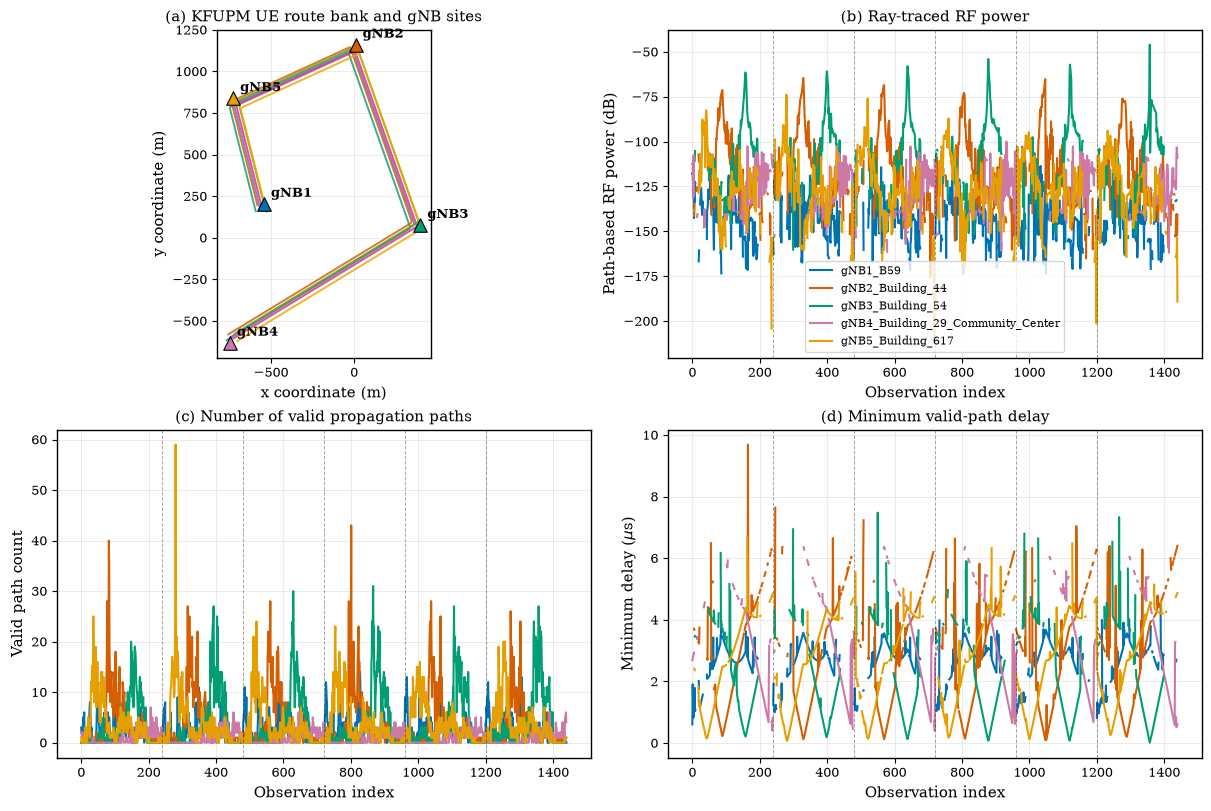

Dense route diagnostic figure saved:
/home/afanali/wcnc_project/improved_experiment/figures/dense_five_gnb_route_diagnostics.pdf
/home/afanali/wcnc_project/improved_experiment/figures/dense_five_gnb_route_diagnostics.png


In [25]:
# ============================================================
# Dense five-gNB route and RF diagnostic figure
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.home() / "wcnc_project"
EXPERIMENT_ROOT = PROJECT_ROOT / "improved_experiment"
FIGURE_DIR = EXPERIMENT_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = (
    EXPERIMENT_ROOT
    / "data"
    / "rf_dense_five_gnb_dataset.npz"
)

with np.load(DATA_FILE, allow_pickle=True) as data:

    positions_xyz_m = data["positions_xyz_m"].astype(float)
    trajectory_ids = data["trajectory_ids"].astype(int)
    route_indices = data["route_indices"].astype(int)
    speeds_mps = data["speeds_mps"].astype(float)
    rf_power_db = data["rf_power_db"].astype(float)
    valid_path_counts = data["valid_path_counts"].astype(float)
    minimum_delay_s = data["minimum_delay_s"].astype(float)

    raw_gnb_names = data["gnb_names"].tolist()

def clean_name(value):
    if isinstance(value, bytes):
        return value.decode("utf-8")
    return str(value)

gnb_names = [
    clean_name(value)
    for value in raw_gnb_names
]

number_of_gnbs = rf_power_db.shape[1]
observation_indices = np.arange(
    rf_power_db.shape[0]
)

# -300 dB and negative delays are sentinel values
rf_plot = np.where(
    rf_power_db <= -299.0,
    np.nan,
    rf_power_db
)

delay_plot_us = np.where(
    minimum_delay_s < 0.0,
    np.nan,
    minimum_delay_s * 1e6
)

# IEEE-style plotting configuration
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.linewidth": 1.0,
    "lines.linewidth": 1.5,
})

gnb_colors = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
]

trajectory_colors = [
    "#1B9E77",
    "#D95F02",
    "#7570B3",
    "#E7298A",
    "#66A61E",
    "#E6AB02",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8),
    constrained_layout=True,
)

ax_map = axes[0, 0]
ax_power = axes[0, 1]
ax_paths = axes[1, 0]
ax_delay = axes[1, 1]

# ------------------------------------------------------------
# Panel (a): UE route bank and gNB locations
# ------------------------------------------------------------

unique_trajectories = np.unique(trajectory_ids)

for trajectory_index, trajectory_id in enumerate(
    unique_trajectories
):

    trajectory_mask = (
        trajectory_ids == trajectory_id
    )

    order = np.argsort(
        route_indices[trajectory_mask]
    )

    trajectory_positions = positions_xyz_m[
        trajectory_mask
    ][order]

    ax_map.plot(
        trajectory_positions[:, 0],
        trajectory_positions[:, 1],
        color=trajectory_colors[
            trajectory_index
            % len(trajectory_colors)
        ],
        linewidth=1.4,
        alpha=0.85,
        label=f"UE route {trajectory_id}",
    )

# Plot gNBs if configuration exists in the notebook kernel
if "GNB_CONFIG" in globals():

    for gnb_index, gnb_config in enumerate(
        GNB_CONFIG
    ):

        gnb_position = np.asarray(
            gnb_config["position_m"],
            dtype=float,
        )

        gnb_label = gnb_config.get(
            "short_label",
            f"gNB{gnb_index + 1}",
        )

        ax_map.scatter(
            gnb_position[0],
            gnb_position[1],
            s=95,
            marker="^",
            color=gnb_colors[
                gnb_index % len(gnb_colors)
            ],
            edgecolor="black",
            linewidth=0.8,
            zorder=5,
        )

        ax_map.annotate(
            gnb_label,
            xy=(
                gnb_position[0],
                gnb_position[1],
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
        )

ax_map.set_title(
    "(a) KFUPM UE route bank and gNB sites"
)
ax_map.set_xlabel("x coordinate (m)")
ax_map.set_ylabel("y coordinate (m)")
ax_map.grid(
    True,
    alpha=0.25,
    linewidth=0.7,
)
ax_map.set_aspect("equal", adjustable="box")

# ------------------------------------------------------------
# Panel (b): RF power
# ------------------------------------------------------------

for gnb_index in range(number_of_gnbs):

    ax_power.plot(
        observation_indices,
        rf_plot[:, gnb_index],
        color=gnb_colors[
            gnb_index % len(gnb_colors)
        ],
        label=gnb_names[gnb_index],
    )

ax_power.set_title(
    "(b) Ray-traced RF power"
)
ax_power.set_xlabel("Observation index")
ax_power.set_ylabel("Path-based RF power (dB)")
ax_power.grid(
    True,
    alpha=0.25,
    linewidth=0.7,
)
ax_power.legend(
    loc="best",
    frameon=True,
)

# ------------------------------------------------------------
# Panel (c): Valid path counts
# ------------------------------------------------------------

for gnb_index in range(number_of_gnbs):

    ax_paths.plot(
        observation_indices,
        valid_path_counts[:, gnb_index],
        color=gnb_colors[
            gnb_index % len(gnb_colors)
        ],
        label=gnb_names[gnb_index],
    )

ax_paths.set_title(
    "(c) Number of valid propagation paths"
)
ax_paths.set_xlabel("Observation index")
ax_paths.set_ylabel("Valid path count")
ax_paths.grid(
    True,
    alpha=0.25,
    linewidth=0.7,
)

# ------------------------------------------------------------
# Panel (d): Minimum path delay
# ------------------------------------------------------------

for gnb_index in range(number_of_gnbs):

    ax_delay.plot(
        observation_indices,
        delay_plot_us[:, gnb_index],
        color=gnb_colors[
            gnb_index % len(gnb_colors)
        ],
        label=gnb_names[gnb_index],
    )

ax_delay.set_title(
    "(d) Minimum valid-path delay"
)
ax_delay.set_xlabel("Observation index")
ax_delay.set_ylabel("Minimum delay ($\\mu$s)")
ax_delay.grid(
    True,
    alpha=0.25,
    linewidth=0.7,
)

# Mark trajectory boundaries
trajectory_boundaries = (
    np.where(
        np.diff(trajectory_ids) != 0
    )[0]
    + 0.5
)

for axis in [
    ax_power,
    ax_paths,
    ax_delay,
]:

    for boundary in trajectory_boundaries:

        axis.axvline(
            boundary,
            color="black",
            linestyle="--",
            linewidth=0.7,
            alpha=0.35,
        )

# Save publication formats
pdf_file = (
    FIGURE_DIR
    / "dense_five_gnb_route_diagnostics.pdf"
)

png_file = (
    FIGURE_DIR
    / "dense_five_gnb_route_diagnostics.png"
)

fig.savefig(
    pdf_file,
    bbox_inches="tight",
)

fig.savefig(
    png_file,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Dense route diagnostic figure saved:")
print(pdf_file)
print(png_file)

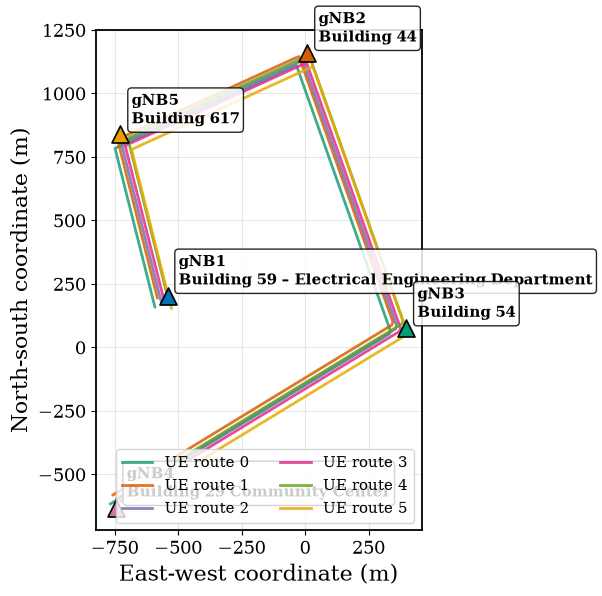

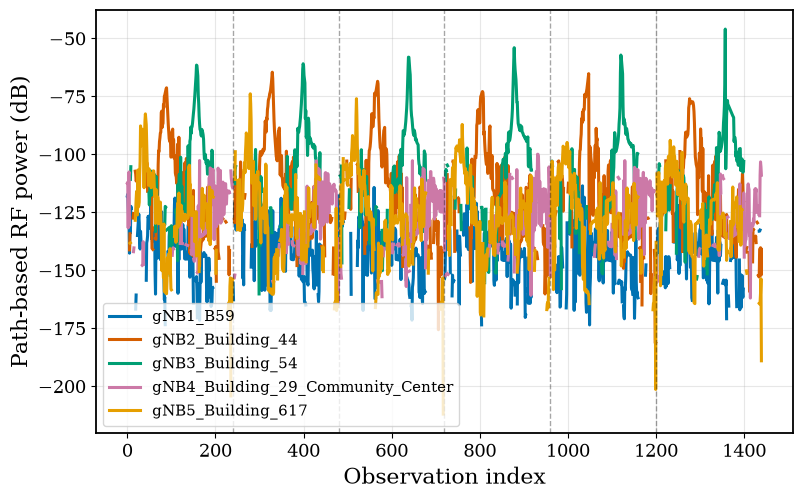

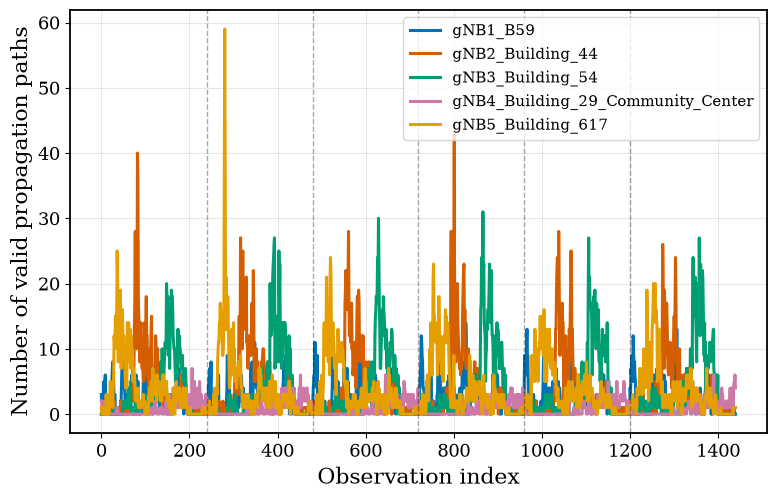

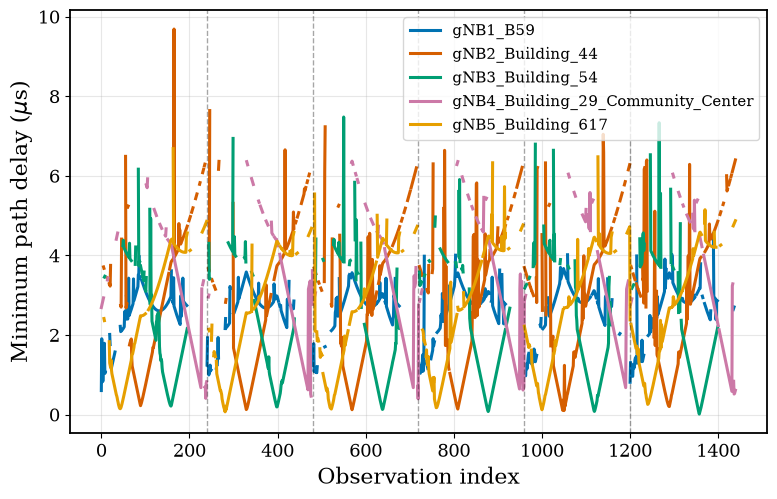

Separate IEEE-style PDF figures saved:
/home/afanali/wcnc_project/improved_experiment/figures/kfupm_ue_route_bank.pdf
/home/afanali/wcnc_project/improved_experiment/figures/rf_power_per_gnb.pdf
/home/afanali/wcnc_project/improved_experiment/figures/valid_path_count_per_gnb.pdf
/home/afanali/wcnc_project/improved_experiment/figures/minimum_path_delay_per_gnb.pdf


In [24]:
# ============================================================
# Save separate title-free IEEE figures as PDF
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.home() / "wcnc_project"
EXPERIMENT_ROOT = PROJECT_ROOT / "improved_experiment"
FIGURE_DIR = EXPERIMENT_ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = (
    EXPERIMENT_ROOT
    / "data"
    / "rf_dense_five_gnb_dataset.npz"
)

with np.load(DATA_FILE, allow_pickle=True) as data:

    positions_xyz_m = data["positions_xyz_m"].astype(float)
    trajectory_ids = data["trajectory_ids"].astype(int)
    route_indices = data["route_indices"].astype(int)
    rf_power_db = data["rf_power_db"].astype(float)
    valid_path_counts = data["valid_path_counts"].astype(float)
    minimum_delay_s = data["minimum_delay_s"].astype(float)
    raw_gnb_names = data["gnb_names"].tolist()

def clean_name(value):
    if isinstance(value, bytes):
        return value.decode("utf-8")
    return str(value)

gnb_names = [
    clean_name(value)
    for value in raw_gnb_names
]

number_of_gnbs = rf_power_db.shape[1]
observation_indices = np.arange(
    rf_power_db.shape[0]
)

# Treat unavailable links as missing values
rf_plot = np.where(
    rf_power_db <= -299.0,
    np.nan,
    rf_power_db
)

delay_plot_us = np.where(
    minimum_delay_s < 0.0,
    np.nan,
    minimum_delay_s * 1e6
)

# Large-font IEEE configuration
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 11,
    "axes.linewidth": 1.3,
    "lines.linewidth": 2.2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

gnb_colors = [
    "#0072B2",
    "#D55E00",
    "#009E73",
    "#CC79A7",
    "#E69F00",
]

trajectory_colors = [
    "#1B9E77",
    "#D95F02",
    "#7570B3",
    "#E7298A",
    "#66A61E",
    "#E6AB02",
]

unique_trajectories = np.unique(
    trajectory_ids
)

trajectory_boundaries = (
    np.where(
        np.diff(trajectory_ids) != 0
    )[0]
    + 0.5
)

# ------------------------------------------------------------
# Figure 1: UE route bank and gNB locations
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

for trajectory_index, trajectory_id in enumerate(
    unique_trajectories
):

    trajectory_mask = (
        trajectory_ids == trajectory_id
    )

    order = np.argsort(
        route_indices[trajectory_mask]
    )

    trajectory_positions = positions_xyz_m[
        trajectory_mask
    ][order]

    ax.plot(
        trajectory_positions[:, 0],
        trajectory_positions[:, 1],
        color=trajectory_colors[
            trajectory_index
            % len(trajectory_colors)
        ],
        linewidth=2.0,
        alpha=0.85,
        label=f"UE route {trajectory_id}",
    )

if "GNB_CONFIG" in globals():

    for gnb_index, gnb_config in enumerate(
        GNB_CONFIG
    ):

        gnb_position = np.asarray(
            gnb_config["position_m"],
            dtype=float,
        )

        short_label = gnb_config.get(
            "short_label",
            f"gNB{gnb_index + 1}",
        )

        site_label = gnb_config.get(
            "site_label",
            gnb_config.get("id", ""),
        )

        ax.scatter(
            gnb_position[0],
            gnb_position[1],
            s=150,
            marker="^",
            color=gnb_colors[
                gnb_index % len(gnb_colors)
            ],
            edgecolor="black",
            linewidth=1.2,
            zorder=5,
        )

        ax.annotate(
            f"{short_label}\n{site_label}",
            xy=(
                gnb_position[0],
                gnb_position[1],
            ),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=11,
            fontweight="bold",
            bbox={
                "boxstyle": "round,pad=0.25",
                "facecolor": "white",
                "edgecolor": "black",
                "alpha": 0.85,
            },
        )

ax.set_xlabel("East-west coordinate (m)")
ax.set_ylabel("North-south coordinate (m)")
ax.grid(
    True,
    alpha=0.3,
    linewidth=0.8,
)
ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.legend(
    loc="best",
    frameon=True,
    ncol=2,
)

route_file = (
    FIGURE_DIR
    / "kfupm_ue_route_bank.pdf"
)

fig.savefig(
    route_file,
    format="pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Figure 2: RF power
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

for gnb_index in range(number_of_gnbs):

    ax.plot(
        observation_indices,
        rf_plot[:, gnb_index],
        color=gnb_colors[
            gnb_index % len(gnb_colors)
        ],
        label=gnb_names[gnb_index],
    )

for boundary in trajectory_boundaries:

    ax.axvline(
        boundary,
        color="black",
        linestyle="--",
        linewidth=1.0,
        alpha=0.35,
    )

ax.set_xlabel("Observation index")
ax.set_ylabel("Path-based RF power (dB)")
ax.grid(
    True,
    alpha=0.3,
    linewidth=0.8,
)

ax.legend(
    loc="best",
    frameon=True,
)

rf_file = (
    FIGURE_DIR
    / "rf_power_per_gnb.pdf"
)

fig.savefig(
    rf_file,
    format="pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Figure 3: Valid path counts
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

for gnb_index in range(number_of_gnbs):

    ax.plot(
        observation_indices,
        valid_path_counts[:, gnb_index],
        color=gnb_colors[
            gnb_index % len(gnb_colors)
        ],
        label=gnb_names[gnb_index],
    )

for boundary in trajectory_boundaries:

    ax.axvline(
        boundary,
        color="black",
        linestyle="--",
        linewidth=1.0,
        alpha=0.35,
    )

ax.set_xlabel("Observation index")
ax.set_ylabel("Number of valid propagation paths")
ax.grid(
    True,
    alpha=0.3,
    linewidth=0.8,
)

ax.legend(
    loc="best",
    frameon=True,
)

path_file = (
    FIGURE_DIR
    / "valid_path_count_per_gnb.pdf"
)

fig.savefig(
    path_file,
    format="pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Figure 4: Minimum path delay
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

for gnb_index in range(number_of_gnbs):

    ax.plot(
        observation_indices,
        delay_plot_us[:, gnb_index],
        color=gnb_colors[
            gnb_index % len(gnb_colors)
        ],
        label=gnb_names[gnb_index],
    )

for boundary in trajectory_boundaries:

    ax.axvline(
        boundary,
        color="black",
        linestyle="--",
        linewidth=1.0,
        alpha=0.35,
    )

ax.set_xlabel("Observation index")
ax.set_ylabel("Minimum path delay ($\\mu$s)")
ax.grid(
    True,
    alpha=0.3,
    linewidth=0.8,
)

ax.legend(
    loc="best",
    frameon=True,
)

delay_file = (
    FIGURE_DIR
    / "minimum_path_delay_per_gnb.pdf"
)

fig.savefig(
    delay_file,
    format="pdf",
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Separate IEEE-style PDF figures saved:")
print(route_file)
print(rf_file)
print(path_file)
print(delay_file)

In [ ]:
# ============================================================
# Synchronized multimodal KFUPM dataset
# RF + mobility + scene-derived virtual LiDAR/range features
# ============================================================

from pathlib import Path
import csv
import json
import time
import hashlib

import numpy as np
import mitsuba as mi
import drjit as dr


# ------------------------------------------------------------
# 1. Paths and scene checks
# ------------------------------------------------------------

PROJECT_ROOT = Path.home() / "wcnc_project"

DATA_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
)

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

DENSE_RF_FILE = (
    DATA_DIR
    / "rf_dense_five_gnb_dataset.npz"
)

MULTIMODAL_FILE = (
    DATA_DIR
    / "synchronized_multimodal_five_gnb_dataset.npz"
)

CHECKPOINT_FILE = (
    RESULTS_DIR
    / "virtual_lidar_range_checkpoint.npz"
)

METADATA_FILE = (
    RESULTS_DIR
    / "synchronized_multimodal_metadata.json"
)

SUMMARY_FILE = (
    RESULTS_DIR
    / "synchronized_multimodal_summary.csv"
)


if not DENSE_RF_FILE.exists():
    raise FileNotFoundError(
        f"Dense RF dataset not found:\n{DENSE_RF_FILE}"
    )

if "scene" not in globals():
    raise RuntimeError(
        "The variable 'scene' is not defined. "
        "Run the KFUPM scene-loading cell first."
    )

mi_scene = getattr(
    scene,
    "mi_scene",
    None,
)

if mi_scene is None:
    raise RuntimeError(
        "The Sionna scene does not expose scene.mi_scene."
    )


# ------------------------------------------------------------
# 2. Load the dense five-gNB RF dataset
# ------------------------------------------------------------

with np.load(
    DENSE_RF_FILE,
    allow_pickle=True,
) as dense_data:

    required_keys = [
        "positions_xyz_m",
        "trajectory_ids",
        "route_indices",
        "speeds_mps",
        "rf_power_db",
        "valid_path_counts",
        "minimum_delay_s",
        "completed",
        "gnb_names",
    ]

    missing_keys = [
        key
        for key in required_keys
        if key not in dense_data.files
    ]

    if missing_keys:
        raise KeyError(
            f"Missing keys: {missing_keys}"
        )

    positions_raw = np.asarray(
        dense_data["positions_xyz_m"],
        dtype=np.float64,
    )

    trajectory_ids_raw = np.asarray(
        dense_data["trajectory_ids"],
        dtype=np.int32,
    )

    route_indices_raw = np.asarray(
        dense_data["route_indices"],
        dtype=np.int32,
    )

    speeds_raw = np.asarray(
        dense_data["speeds_mps"],
        dtype=np.float32,
    )

    rf_power_raw = np.asarray(
        dense_data["rf_power_db"],
        dtype=np.float32,
    )

    valid_paths_raw = np.asarray(
        dense_data["valid_path_counts"],
        dtype=np.float32,
    )

    minimum_delay_raw = np.asarray(
        dense_data["minimum_delay_s"],
        dtype=np.float32,
    )

    completed_raw = np.asarray(
        dense_data["completed"],
        dtype=bool,
    )

    def decode_name(value):
        if isinstance(
            value,
            (
                bytes,
                np.bytes_,
            ),
        ):
            return value.decode(
                "utf-8",
                errors="replace",
            )
        return str(value)

    gnb_names = [
        decode_name(name)
        for name in dense_data["gnb_names"]
    ]


number_of_observations = int(
    positions_raw.shape[0]
)

number_of_gnbs = int(
    rf_power_raw.shape[1]
)

if not np.all(completed_raw):
    raise RuntimeError(
        "The dense RF dataset is incomplete."
    )


# Sort observations by trajectory and route index
observation_order = np.lexsort(
    (
        route_indices_raw,
        trajectory_ids_raw,
    )
)


positions_xyz_m = positions_raw[
    observation_order
]

trajectory_ids = trajectory_ids_raw[
    observation_order
]

route_indices = route_indices_raw[
    observation_order
]

speeds_mps = speeds_raw[
    observation_order
]

rf_power_db = rf_power_raw[
    observation_order
]

valid_path_counts = valid_paths_raw[
    observation_order
]

minimum_delay_s = minimum_delay_raw[
    observation_order
]


print(
    "Dense RF observations:",
    number_of_observations,
)

print(
    "Number of gNBs:",
    number_of_gnbs,
)

print(
    "gNB names:",
    gnb_names,
)


# ------------------------------------------------------------
# 3. Mobility features
# ------------------------------------------------------------

TIME_STEP_S = 0.5

mobility_feature_names = [
    "speed_mps",
    "velocity_x_mps",
    "velocity_y_mps",
    "acceleration_x_mps2",
    "acceleration_y_mps2",
    "heading_sin",
    "heading_cos",
    "yaw_rate_radps",
    "delta_x_m",
    "delta_y_m",
]

mobility_features = np.zeros(
    (
        number_of_observations,
        len(mobility_feature_names),
    ),
    dtype=np.float32,
)

heading_rad = np.zeros(
    number_of_observations,
    dtype=np.float32,
)

time_s = np.zeros(
    number_of_observations,
    dtype=np.float32,
)


for trajectory_id in np.unique(
    trajectory_ids
):

    trajectory_indices = np.flatnonzero(
        trajectory_ids == trajectory_id
    )

    trajectory_indices = trajectory_indices[
        np.argsort(
            route_indices[
                trajectory_indices
            ]
        )
    ]

    trajectory_positions = positions_xyz_m[
        trajectory_indices
    ]

    trajectory_speeds = speeds_mps[
        trajectory_indices
    ]

    trajectory_velocity = np.gradient(
        trajectory_positions,
        TIME_STEP_S,
        axis=0,
    )

    trajectory_acceleration = np.gradient(
        trajectory_velocity,
        TIME_STEP_S,
        axis=0,
    )

    trajectory_heading = np.arctan2(
        trajectory_velocity[:, 1],
        trajectory_velocity[:, 0],
    )

    trajectory_heading = np.unwrap(
        trajectory_heading
    )

    trajectory_yaw_rate = np.gradient(
        trajectory_heading,
        TIME_STEP_S,
    )

    trajectory_delta = np.zeros(
        (
            len(trajectory_indices),
            2,
        ),
        dtype=np.float32,
    )

    if len(trajectory_indices) > 1:

        trajectory_delta[1:] = np.diff(
            trajectory_positions[:, :2],
            axis=0,
        )

    trajectory_mobility = np.column_stack(
        [
            trajectory_speeds,
            trajectory_velocity[:, 0],
            trajectory_velocity[:, 1],
            trajectory_acceleration[:, 0],
            trajectory_acceleration[:, 1],
            np.sin(trajectory_heading),
            np.cos(trajectory_heading),
            trajectory_yaw_rate,
            trajectory_delta[:, 0],
            trajectory_delta[:, 1],
        ]
    ).astype(np.float32)

    mobility_features[
        trajectory_indices
    ] = trajectory_mobility

    heading_rad[
        trajectory_indices
    ] = trajectory_heading.astype(
        np.float32
    )

    time_s[
        trajectory_indices
    ] = (
        route_indices[
            trajectory_indices
        ].astype(np.float32)
        * TIME_STEP_S
    )


# ------------------------------------------------------------
# 4. Virtual LiDAR configuration
# ------------------------------------------------------------

# 24 azimuth rays x 3 elevation rays = 72 features
AZIMUTH_DEG = np.arange(
    0.0,
    360.0,
    15.0,
    dtype=np.float32,
)

ELEVATION_DEG = np.array(
    [
        -10.0,
        0.0,
        10.0,
    ],
    dtype=np.float32,
)

RANGE_SENSOR_HEIGHT_M = 1.5
MAX_RANGE_M = 300.0
MIN_RANGE_M = 0.05

NUMBER_OF_AZIMUTH_RAYS = int(
    len(AZIMUTH_DEG)
)

NUMBER_OF_ELEVATION_RAYS = int(
    len(ELEVATION_DEG)
)

NUMBER_OF_RAYS = (
    NUMBER_OF_AZIMUTH_RAYS
    * NUMBER_OF_ELEVATION_RAYS
)


azimuth_rad = np.deg2rad(
    AZIMUTH_DEG
)

elevation_rad = np.deg2rad(
    ELEVATION_DEG
)

ray_directions_body = []

for elevation in elevation_rad:

    for azimuth in azimuth_rad:

        ray_directions_body.append(
            [
                np.cos(elevation)
                * np.cos(azimuth),

                np.cos(elevation)
                * np.sin(azimuth),

                np.sin(elevation),
            ]
        )

ray_directions_body = np.asarray(
    ray_directions_body,
    dtype=np.float32,
)

ray_azimuth_deg = np.tile(
    AZIMUTH_DEG,
    NUMBER_OF_ELEVATION_RAYS,
)

ray_elevation_deg = np.repeat(
    ELEVATION_DEG,
    NUMBER_OF_AZIMUTH_RAYS,
)


# ------------------------------------------------------------
# 5. Mitsuba virtual LiDAR function
# ------------------------------------------------------------

def cast_virtual_lidar(
    positions_batch,
    headings_batch,
):
    """
    Cast batched rays against the loaded KFUPM mesh.

    Azimuth zero is aligned with the UE heading.
    Missed rays are assigned MAX_RANGE_M.
    """

    positions_batch = np.asarray(
        positions_batch,
        dtype=np.float32,
    )

    headings_batch = np.asarray(
        headings_batch,
        dtype=np.float32,
    )

    batch_size = int(
        positions_batch.shape[0]
    )

    origins = np.repeat(
        positions_batch,
        NUMBER_OF_RAYS,
        axis=0,
    )

    origins[:, 2] += (
        RANGE_SENSOR_HEIGHT_M
    )

    local_directions = np.tile(
        ray_directions_body,
        (
            batch_size,
            1,
        ),
    )

    repeated_headings = np.repeat(
        headings_batch,
        NUMBER_OF_RAYS,
    )

    cos_heading = np.cos(
        repeated_headings
    )

    sin_heading = np.sin(
        repeated_headings
    )

    directions = np.zeros_like(
        local_directions,
        dtype=np.float32,
    )

    directions[:, 0] = (
        local_directions[:, 0]
        * cos_heading
        - local_directions[:, 1]
        * sin_heading
    )

    directions[:, 1] = (
        local_directions[:, 0]
        * sin_heading
        + local_directions[:, 1]
        * cos_heading
    )

    directions[:, 2] = (
        local_directions[:, 2]
    )

    def to_mitsuba_float(values):
        return mi.Float(
            np.ascontiguousarray(
                values,
                dtype=np.float32,
            )
        )

    rays = mi.Ray3f(
        o=mi.Point3f(
            to_mitsuba_float(
                origins[:, 0]
            ),
            to_mitsuba_float(
                origins[:, 1]
            ),
            to_mitsuba_float(
                origins[:, 2]
            ),
        ),
        d=mi.Vector3f(
            to_mitsuba_float(
                directions[:, 0]
            ),
            to_mitsuba_float(
                directions[:, 1]
            ),
            to_mitsuba_float(
                directions[:, 2]
            ),
        ),
    )

    # Mitsuba 3 Ray3f has maxt but no mint.
    # Very short intersections are filtered below.
    rays.maxt = mi.Float(
        MAX_RANGE_M
    )

    surface_interaction = (
        mi_scene.ray_intersect(rays)
    )

    distances = surface_interaction.t

    dr.eval(distances)

    distances = np.asarray(
        distances,
        dtype=np.float32,
    ).reshape(
        batch_size,
        NUMBER_OF_RAYS,
    )

    invalid = (
        ~np.isfinite(distances)
        | (
            distances
            <= MIN_RANGE_M
        )
        | (
            distances
            > MAX_RANGE_M
        )
    )

    distances[invalid] = (
        MAX_RANGE_M
    )

    return distances


# ------------------------------------------------------------
# 6. Initialize or resume LiDAR checkpoint
# ------------------------------------------------------------

range_features_m = np.full(
    (
        number_of_observations,
        NUMBER_OF_RAYS,
    ),
    MAX_RANGE_M,
    dtype=np.float32,
)

range_completed = np.zeros(
    number_of_observations,
    dtype=bool,
)


if CHECKPOINT_FILE.exists():

    try:

        with np.load(
            CHECKPOINT_FILE,
            allow_pickle=True,
        ) as checkpoint:

            checkpoint_positions = np.asarray(
                checkpoint[
                    "positions_xyz_m"
                ]
            )

            checkpoint_trajectories = np.asarray(
                checkpoint[
                    "trajectory_ids"
                ]
            )

            checkpoint_routes = np.asarray(
                checkpoint[
                    "route_indices"
                ]
            )

            checkpoint_ranges = np.asarray(
                checkpoint[
                    "range_features_m"
                ]
            )

            checkpoint_completed = np.asarray(
                checkpoint[
                    "range_completed"
                ],
                dtype=bool,
            )

        checkpoint_is_compatible = (
            checkpoint_positions.shape
            == positions_xyz_m.shape
            and checkpoint_ranges.shape
            == range_features_m.shape
            and np.allclose(
                checkpoint_positions,
                positions_xyz_m,
            )
            and np.array_equal(
                checkpoint_trajectories,
                trajectory_ids,
            )
            and np.array_equal(
                checkpoint_routes,
                route_indices,
            )
        )

        if checkpoint_is_compatible:

            range_features_m[:] = (
                checkpoint_ranges
            )

            range_completed[:] = (
                checkpoint_completed
            )

            print(
                "Compatible LiDAR checkpoint loaded."
            )

        else:

            print(
                "Existing checkpoint is incompatible."
            )

    except Exception as checkpoint_error:

        print(
            "Checkpoint could not be loaded:"
        )

        print(checkpoint_error)

        print(
            "Starting a new LiDAR extraction."
        )


def save_lidar_checkpoint():

    temporary_file = (
        RESULTS_DIR
        / "virtual_lidar_range_checkpoint.tmp.npz"
    )

    np.savez_compressed(
        temporary_file,

        positions_xyz_m=positions_xyz_m,

        trajectory_ids=trajectory_ids,

        route_indices=route_indices,

        range_features_m=range_features_m,

        range_completed=range_completed,

        ray_azimuth_deg=ray_azimuth_deg,

        ray_elevation_deg=ray_elevation_deg,

        max_range_m=np.array(
            MAX_RANGE_M,
            dtype=np.float32,
        ),
    )

    temporary_file.replace(
        CHECKPOINT_FILE
    )


# ------------------------------------------------------------
# 7. GPU LiDAR extraction
# ------------------------------------------------------------

RANGE_BATCH_OBSERVATIONS = 64

remaining_before = int(
    np.sum(~range_completed)
)

print(
    f"Observations requiring LiDAR: "
    f"{remaining_before}/"
    f"{number_of_observations}"
)

range_start_time = time.perf_counter()

for start in range(
    0,
    number_of_observations,
    RANGE_BATCH_OBSERVATIONS,
):

    stop = min(
        start
        + RANGE_BATCH_OBSERVATIONS,
        number_of_observations,
    )

    batch_indices = np.arange(
        start,
        stop,
    )

    batch_indices = batch_indices[
        ~range_completed[
            batch_indices
        ]
    ]

    if len(batch_indices) == 0:
        continue

    batch_ranges = cast_virtual_lidar(
        positions_xyz_m[
            batch_indices
        ],
        heading_rad[
            batch_indices
        ],
    )

    range_features_m[
        batch_indices
    ] = batch_ranges

    range_completed[
        batch_indices
    ] = True

    save_lidar_checkpoint()

    completed_count = int(
        np.sum(range_completed)
    )

    elapsed = (
        time.perf_counter()
        - range_start_time
    )

    print(
        f"LiDAR progress: "
        f"{completed_count}/"
        f"{number_of_observations} | "
        f"elapsed: {elapsed:.1f} s"
    )


if not np.all(range_completed):
    raise RuntimeError(
        "LiDAR extraction did not complete."
    )


# ------------------------------------------------------------
# 8. LiDAR summary features
# ------------------------------------------------------------

lidar_hit_mask = (
    range_features_m
    < (
        MAX_RANGE_M
        - 1e-3
    )
)

hit_count = np.sum(
    lidar_hit_mask,
    axis=1,
).astype(np.float32)

hit_fraction = (
    hit_count
    / float(NUMBER_OF_RAYS)
)

safe_ranges = np.where(
    lidar_hit_mask,
    range_features_m,
    MAX_RANGE_M,
)

nearest_range_m = np.min(
    safe_ranges,
    axis=1,
)

farthest_hit_range_m = np.max(
    safe_ranges,
    axis=1,
)

mean_range_m = (
    np.sum(
        np.where(
            lidar_hit_mask,
            range_features_m,
            0.0,
        ),
        axis=1,
    )
    / np.maximum(
        hit_count,
        1.0,
    )
)

p10_range_m = np.full(
    number_of_observations,
    MAX_RANGE_M,
    dtype=np.float32,
)

p50_range_m = np.full(
    number_of_observations,
    MAX_RANGE_M,
    dtype=np.float32,
)

p90_range_m = np.full(
    number_of_observations,
    MAX_RANGE_M,
    dtype=np.float32,
)


for observation_index in range(
    number_of_observations
):

    valid_ranges = range_features_m[
        observation_index
    ][
        lidar_hit_mask[
            observation_index
        ]
    ]

    if len(valid_ranges) > 0:

        p10_range_m[
            observation_index
        ] = np.percentile(
            valid_ranges,
            10,
        )

        p50_range_m[
            observation_index
        ] = np.percentile(
            valid_ranges,
            50,
        )

        p90_range_m[
            observation_index
        ] = np.percentile(
            valid_ranges,
            90,
        )


lidar_summary = np.column_stack(
    [
        nearest_range_m,
        mean_range_m,
        farthest_hit_range_m,
        p10_range_m,
        p50_range_m,
        p90_range_m,
        hit_fraction,
    ]
).astype(np.float32)

lidar_summary_names = [
    "nearest_range_m",
    "mean_range_m",
    "farthest_hit_range_m",
    "p10_range_m",
    "p50_range_m",
    "p90_range_m",
    "hit_fraction",
]


# ------------------------------------------------------------
# 9. RF feature block
# ------------------------------------------------------------

clean_rf_power_db = np.where(
    np.isfinite(rf_power_db),
    rf_power_db,
    -300.0,
).astype(np.float32)

clean_valid_paths = np.where(
    np.isfinite(valid_path_counts),
    valid_path_counts,
    0.0,
).astype(np.float32)

clean_delay_us = np.where(
    np.isfinite(minimum_delay_s)
    & (
        minimum_delay_s
        >= 0.0
    ),
    minimum_delay_s * 1e6,
    0.0,
).astype(np.float32)


rf_feature_names = (
    [
        f"{name}_rf_power_db"
        for name in gnb_names
    ]
    + [
        f"{name}_valid_paths"
        for name in gnb_names
    ]
    + [
        f"{name}_minimum_delay_us"
        for name in gnb_names
    ]
)

rf_features = np.column_stack(
    [
        clean_rf_power_db,
        clean_valid_paths,
        clean_delay_us,
    ]
).astype(np.float32)


# Best currently usable gNB
usable_links = (
    clean_valid_paths > 0
)

masked_power = np.where(
    usable_links,
    clean_rf_power_db,
    -np.inf,
)

best_gnb_index = np.argmax(
    masked_power,
    axis=1,
).astype(np.int16)

no_usable_link = (
    np.sum(
        usable_links,
        axis=1,
    )
    == 0
)

best_gnb_index[
    no_usable_link
] = -1


# ------------------------------------------------------------
# 10. Combined multimodal feature block
# ------------------------------------------------------------

lidar_feature_names = [
    f"lidar_range_{index:02d}_m"
    for index in range(NUMBER_OF_RAYS)
]

combined_features = np.column_stack(
    [
        rf_features,
        mobility_features,
        range_features_m,
    ]
).astype(np.float32)

combined_feature_names = (
    rf_feature_names
    + mobility_feature_names
    + lidar_feature_names
)


# ------------------------------------------------------------
# 11. Save synchronized multimodal dataset
# ------------------------------------------------------------

np.savez_compressed(
    MULTIMODAL_FILE,

    positions_xyz_m=positions_xyz_m.astype(
        np.float32
    ),

    trajectory_ids=trajectory_ids,

    route_indices=route_indices,

    time_s=time_s,

    speeds_mps=speeds_mps,

    heading_rad=heading_rad,

    mobility_features=mobility_features,

    rf_power_db=clean_rf_power_db,

    valid_path_counts=clean_valid_paths,

    minimum_delay_s=minimum_delay_s,

    minimum_delay_us=clean_delay_us,

    rf_features=rf_features,

    lidar_ranges_m=range_features_m,

    lidar_hit_mask=lidar_hit_mask,

    lidar_summary=lidar_summary,

    combined_features=combined_features,

    best_gnb_index=best_gnb_index,

    completed=np.ones(
        number_of_observations,
        dtype=bool,
    ),

    gnb_names=np.asarray(
        gnb_names,
        dtype="U",
    ),

    ray_azimuth_deg=ray_azimuth_deg,

    ray_elevation_deg=ray_elevation_deg,

    max_lidar_range_m=np.array(
        MAX_RANGE_M,
        dtype=np.float32,
    ),

    lidar_sensor_height_m=np.array(
        RANGE_SENSOR_HEIGHT_M,
        dtype=np.float32,
    ),
)


# ------------------------------------------------------------
# 12. Save metadata
# ------------------------------------------------------------

dense_sha256 = hashlib.sha256(
    DENSE_RF_FILE.read_bytes()
).hexdigest()

metadata = {
    "dataset_name": (
        "synchronized_multimodal_five_gnb"
    ),

    "source_dense_rf_dataset": str(
        DENSE_RF_FILE
    ),

    "source_dense_rf_sha256": (
        dense_sha256
    ),

    "number_of_observations": int(
        number_of_observations
    ),

    "number_of_gnbs": int(
        number_of_gnbs
    ),

    "gnb_names": gnb_names,

    "trajectory_count": int(
        len(
            np.unique(
                trajectory_ids
            )
        )
    ),

    "points_per_trajectory": int(
        len(route_indices)
        // len(
            np.unique(
                trajectory_ids
            )
        )
    ),

    "time_step_s": TIME_STEP_S,

    "rf_feature_dimension": int(
        rf_features.shape[1]
    ),

    "mobility_feature_dimension": int(
        mobility_features.shape[1]
    ),

    "lidar_feature_dimension": int(
        range_features_m.shape[1]
    ),

    "combined_feature_dimension": int(
        combined_features.shape[1]
    ),

    "rf_feature_names": rf_feature_names,

    "mobility_feature_names": (
        mobility_feature_names
    ),

    "lidar_summary_names": (
        lidar_summary_names
    ),

    "combined_feature_names": (
        combined_feature_names
    ),

    "lidar_method": (
        "Virtual LiDAR generated by "
        "batched Mitsuba ray intersections "
        "against the loaded KFUPM scene mesh"
    ),

    "lidar_is_scene_derived": True,

    "lidar_coordinate_frame": (
        "UE body frame rotated into the "
        "global scene frame using route heading"
    ),

    "ray_count": int(
        NUMBER_OF_RAYS
    ),

    "azimuth_count": int(
        NUMBER_OF_AZIMUTH_RAYS
    ),

    "elevation_count": int(
        NUMBER_OF_ELEVATION_RAYS
    ),

    "azimuth_spacing_deg": 15.0,

    "elevation_angles_deg": (
        ELEVATION_DEG.tolist()
    ),

    "sensor_height_m": (
        RANGE_SENSOR_HEIGHT_M
    ),

    "maximum_range_m": (
        MAX_RANGE_M
    ),

    "checkpoint_file": str(
        CHECKPOINT_FILE
    ),

    "multimodal_dataset_file": str(
        MULTIMODAL_FILE
    ),
}


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8",
) as metadata_file:

    json.dump(
        metadata,
        metadata_file,
        indent=2,
    )


# ------------------------------------------------------------
# 13. Save row-level summary CSV
# ------------------------------------------------------------

summary_columns = [
    "observation_index",
    "trajectory_id",
    "route_index",
    "time_s",
    "x_m",
    "y_m",
    "z_m",
    "speed_mps",
    "best_gnb_index",
    "best_gnb_name",
]

for name in gnb_names:

    summary_columns.extend(
        [
            f"{name}_rf_power_db",
            f"{name}_valid_paths",
            f"{name}_minimum_delay_us",
        ]
    )

summary_columns.extend(
    lidar_summary_names
)


with open(
    SUMMARY_FILE,
    "w",
    newline="",
    encoding="utf-8",
) as summary_file:

    writer = csv.writer(
        summary_file
    )

    writer.writerow(
        summary_columns
    )

    for index in range(
        number_of_observations
    ):

        best_index = int(
            best_gnb_index[index]
        )

        best_name = (
            gnb_names[best_index]
            if best_index >= 0
            else "none"
        )

        row = [
            index,
            int(
                trajectory_ids[index]
            ),
            int(
                route_indices[index]
            ),
            float(
                time_s[index]
            ),
            float(
                positions_xyz_m[
                    index,
                    0,
                ]
            ),
            float(
                positions_xyz_m[
                    index,
                    1,
                ]
            ),
            float(
                positions_xyz_m[
                    index,
                    2,
                ]
            ),
            float(
                speeds_mps[index]
            ),
            best_index,
            best_name,
        ]

        for gnb_index in range(
            number_of_gnbs
        ):

            row.extend(
                [
                    float(
                        clean_rf_power_db[
                            index,
                            gnb_index,
                        ]
                    ),
                    float(
                        clean_valid_paths[
                            index,
                            gnb_index,
                        ]
                    ),
                    float(
                        clean_delay_us[
                            index,
                            gnb_index,
                        ]
                    ),
                ]
            )

        row.extend(
            [
                float(
                    lidar_summary[
                        index,
                        summary_index,
                    ]
                )
                for summary_index in range(
                    lidar_summary.shape[1]
                )
            ]
        )

        writer.writerow(row)


# ------------------------------------------------------------
# 14. Validation
# ------------------------------------------------------------

assert MULTIMODAL_FILE.exists()
assert METADATA_FILE.exists()
assert SUMMARY_FILE.exists()

assert range_features_m.shape == (
    number_of_observations,
    72,
)

assert mobility_features.shape == (
    number_of_observations,
    10,
)

assert rf_features.shape == (
    number_of_observations,
    number_of_gnbs * 3,
)

assert combined_features.shape == (
    number_of_observations,
    (
        number_of_gnbs * 3
        + 10
        + 72
    ),
)

assert np.all(
    np.isfinite(
        range_features_m
    )
)

assert np.all(
    np.isfinite(
        mobility_features
    )
)

assert np.all(
    np.isfinite(
        combined_features
    )
)


print()
print(
    "Synchronized multimodal dataset created."
)

print(
    "RF feature shape:",
    rf_features.shape,
)

print(
    "Mobility feature shape:",
    mobility_features.shape,
)

print(
    "LiDAR feature shape:",
    range_features_m.shape,
)

print(
    "Combined feature shape:",
    combined_features.shape,
)

print(
    "Mean LiDAR hit fraction:",
    round(
        float(
            np.mean(
                hit_fraction
            )
        ),
        4,
    ),
)

print(
    "Best-gNB distribution:"
)

for gnb_index, gnb_name in enumerate(
    gnb_names
):

    print(
        f"  {gnb_name}:",
        int(
            np.sum(
                best_gnb_index
                == gnb_index
            )
        ),
    )

print()
print(
    "Saved dataset:"
)
print(MULTIMODAL_FILE)

print()
print(
    "Saved metadata:"
)
print(METADATA_FILE)

print()
print(
    "Saved summary:"
)
print(SUMMARY_FILE)

print()
print(
    "Checkpoint retained:"
)
print(CHECKPOINT_FILE)

Dense RF observations: 1440
Number of gNBs: 5
gNB names: ['gNB1_B59', 'gNB2_Building_44', 'gNB3_Building_54', 'gNB4_Building_29_Community_Center', 'gNB5_Building_617']
Observations requiring LiDAR: 1440/1440
LiDAR progress: 64/1440 | elapsed: 0.2 s
LiDAR progress: 128/1440 | elapsed: 0.3 s
LiDAR progress: 192/1440 | elapsed: 0.4 s
LiDAR progress: 256/1440 | elapsed: 0.5 s
LiDAR progress: 320/1440 | elapsed: 0.6 s
LiDAR progress: 384/1440 | elapsed: 0.7 s
LiDAR progress: 448/1440 | elapsed: 0.8 s
LiDAR progress: 512/1440 | elapsed: 0.9 s
LiDAR progress: 576/1440 | elapsed: 1.0 s
LiDAR progress: 640/1440 | elapsed: 1.1 s
LiDAR progress: 704/1440 | elapsed: 1.3 s
LiDAR progress: 768/1440 | elapsed: 1.3 s
LiDAR progress: 832/1440 | elapsed: 1.5 s
LiDAR progress: 896/1440 | elapsed: 1.6 s
LiDAR progress: 960/1440 | elapsed: 1.7 s
LiDAR progress: 1024/1440 | elapsed: 1.8 s
LiDAR progress: 1088/1440 | elapsed: 1.9 s
LiDAR progress: 1152/1440 | elapsed: 2.0 s
LiDAR progress: 1216/1440 | elapse

In [ ]:
# ============================================================
# Verify synchronized multimodal dataset
# ============================================================

from pathlib import Path
import numpy as np
import json


PROJECT_ROOT = Path.home() / "wcnc_project"

MULTIMODAL_FILE = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
    / "synchronized_multimodal_five_gnb_dataset.npz"
)

METADATA_FILE = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
    / "synchronized_multimodal_metadata.json"
)


if not MULTIMODAL_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{MULTIMODAL_FILE}"
    )


with np.load(
    MULTIMODAL_FILE,
    allow_pickle=True,
) as loaded_data:

    multimodal_data = {
        key: loaded_data[key]
        for key in loaded_data.files
    }


with open(
    METADATA_FILE,
    "r",
    encoding="utf-8",
) as metadata_file:

    multimodal_metadata = json.load(
        metadata_file
    )


positions_xyz_m = (
    multimodal_data[
        "positions_xyz_m"
    ]
)

trajectory_ids = (
    multimodal_data[
        "trajectory_ids"
    ]
)

route_indices = (
    multimodal_data[
        "route_indices"
    ]
)

rf_features = (
    multimodal_data[
        "rf_features"
    ]
)

mobility_features = (
    multimodal_data[
        "mobility_features"
    ]
)

lidar_ranges_m = (
    multimodal_data[
        "lidar_ranges_m"
    ]
)

lidar_hit_mask = (
    multimodal_data[
        "lidar_hit_mask"
    ]
)

combined_features = (
    multimodal_data[
        "combined_features"
    ]
)

best_gnb_index = (
    multimodal_data[
        "best_gnb_index"
    ]
)

gnb_names = [
    str(name)
    for name in multimodal_data[
        "gnb_names"
    ]
]


# ------------------------------------------------------------
# Validation checks
# ------------------------------------------------------------

number_of_observations = (
    positions_xyz_m.shape[0]
)

number_of_gnbs = len(
    gnb_names
)

assert rf_features.shape == (
    number_of_observations,
    number_of_gnbs * 3,
)

assert mobility_features.shape == (
    number_of_observations,
    10,
)

assert lidar_ranges_m.shape == (
    number_of_observations,
    72,
)

assert combined_features.shape == (
    number_of_observations,
    number_of_gnbs * 3 + 10 + 72,
)

assert np.all(
    np.isfinite(
        combined_features
    )
)

assert np.all(
    multimodal_data[
        "completed"
    ]
)

for trajectory_id in np.unique(
    trajectory_ids
):

    trajectory_mask = (
        trajectory_ids
        == trajectory_id
    )

    trajectory_routes = (
        route_indices[
            trajectory_mask
        ]
    )

    assert np.all(
        np.diff(
            trajectory_routes
        )
        >= 0
    )


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("MULTIMODAL DATASET VALIDATION PASSED")
print("-------------------------------------")

print(
    "Dataset:",
    MULTIMODAL_FILE,
)

print(
    "Observations:",
    number_of_observations,
)

print(
    "Trajectories:",
    len(
        np.unique(
            trajectory_ids
        )
    ),
)

print(
    "gNBs:",
    gnb_names,
)

print(
    "RF feature shape:",
    rf_features.shape,
)

print(
    "Mobility feature shape:",
    mobility_features.shape,
)

print(
    "LiDAR feature shape:",
    lidar_ranges_m.shape,
)

print(
    "Combined feature shape:",
    combined_features.shape,
)

print(
    "Mean LiDAR hit fraction:",
    round(
        float(
            np.mean(
                lidar_hit_mask
            )
        ),
        4,
    ),
)

print(
    "Minimum LiDAR range:",
    round(
        float(
            np.min(
                lidar_ranges_m
            )
        ),
        3,
    ),
    "m",
)

print(
    "Median LiDAR range:",
    round(
        float(
            np.median(
                lidar_ranges_m
            )
        ),
        3,
    ),
    "m",
)

print(
    "Maximum LiDAR range:",
    round(
        float(
            np.max(
                lidar_ranges_m
            )
        ),
        3,
    ),
    "m",
)

print("\nBest-gNB distribution:")

for gnb_index, gnb_name in enumerate(
    gnb_names
):

    count = int(
        np.sum(
            best_gnb_index
            == gnb_index
        )
    )

    print(
        f"{gnb_name}: {count}"
    )

print("\nMetadata feature dimensions:")

print(
    "RF:",
    multimodal_metadata[
        "rf_feature_dimension"
    ],
)

print(
    "Mobility:",
    multimodal_metadata[
        "mobility_feature_dimension"
    ],
)

print(
    "LiDAR:",
    multimodal_metadata[
        "lidar_feature_dimension"
    ],
)

print(
    "Combined:",
    multimodal_metadata[
        "combined_feature_dimension"
    ],
)

MULTIMODAL DATASET VALIDATION PASSED
-------------------------------------
Dataset: /home/afanali/wcnc_project/improved_experiment/data/synchronized_multimodal_five_gnb_dataset.npz
Observations: 1440
Trajectories: 6
gNBs: ['gNB1_B59', 'gNB2_Building_44', 'gNB3_Building_54', 'gNB4_Building_29_Community_Center', 'gNB5_Building_617']
RF feature shape: (1440, 15)
Mobility feature shape: (1440, 10)
LiDAR feature shape: (1440, 72)
Combined feature shape: (1440, 97)
Mean LiDAR hit fraction: 0.6561
Minimum LiDAR range: 0.053 m
Median LiDAR range: 86.593 m
Maximum LiDAR range: 300.0 m

Best-gNB distribution:
gNB1_B59: 25
gNB2_Building_44: 446
gNB3_Building_54: 459
gNB4_Building_29_Community_Center: 240
gNB5_Building_617: 261

Metadata feature dimensions:
RF: 15
Mobility: 10
LiDAR: 72
Combined: 97


In [ ]:
# ============================================================
# Diagnose virtual LiDAR ranges
# ============================================================

from pathlib import Path
import numpy as np


PROJECT_ROOT = Path.home() / "wcnc_project"

MULTIMODAL_FILE = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
    / "synchronized_multimodal_five_gnb_dataset.npz"
)


with np.load(
    MULTIMODAL_FILE,
    allow_pickle=True,
) as data:

    lidar_ranges_m = data[
        "lidar_ranges_m"
    ]

    trajectory_ids = data[
        "trajectory_ids"
    ]

    route_indices = data[
        "route_indices"
    ]

    positions_xyz_m = data[
        "positions_xyz_m"
    ]

    ray_azimuth_deg = data[
        "ray_azimuth_deg"
    ]

    ray_elevation_deg = data[
        "ray_elevation_deg"
    ]

    gnb_names = [
        str(name)
        for name in data[
            "gnb_names"
        ]
    ]


number_of_observations = (
    lidar_ranges_m.shape[0]
)

number_of_rays = (
    lidar_ranges_m.shape[1]
)

print("LiDAR range diagnostics")
print("-----------------------")

print(
    "Total range values:",
    lidar_ranges_m.size,
)

print(
    "Number of observations:",
    number_of_observations,
)

print(
    "Number of rays per observation:",
    number_of_rays,
)

print()


# Range percentiles
percentiles = [
    0,
    1,
    5,
    25,
    50,
    75,
    95,
    99,
    100,
]

print("Range percentiles:")

for percentile in percentiles:

    value = np.percentile(
        lidar_ranges_m,
        percentile,
    )

    print(
        f"{percentile:>3d}th percentile:"
        f" {value:8.3f} m"
    )


print()


# Near-zero range counts
print("Near-zero range values:")

for threshold in [
    0.1,
    0.2,
    0.5,
    1.0,
    2.0,
]:

    count = int(
        np.sum(
            lidar_ranges_m
            < threshold
        )
    )

    percentage = (
        100.0
        * count
        / lidar_ranges_m.size
    )

    print(
        f"Below {threshold:>4.1f} m:"
        f" {count:6d}"
        f" ({percentage:.4f}%)"
    )


print()


# Maximum-range values
maximum_range_mask = (
    lidar_ranges_m
    >= 299.999
)

maximum_range_count = int(
    np.sum(
        maximum_range_mask
    )
)

maximum_range_percentage = (
    100.0
    * maximum_range_count
    / lidar_ranges_m.size
)

print(
    "Values at maximum range:",
    maximum_range_count,
)

print(
    "Maximum-range percentage:",
    round(
        maximum_range_percentage,
        4,
    ),
    "%",
)


# Identify the smallest individual ranges
flat_order = np.argsort(
    lidar_ranges_m,
    axis=None,
)

smallest_flat_indices = (
    flat_order[:10]
)

smallest_indices = np.unravel_index(
    smallest_flat_indices,
    lidar_ranges_m.shape,
)

print()
print("Ten smallest range values:")
print("--------------------------")

for observation_index, ray_index in zip(
    smallest_indices[0],
    smallest_indices[1],
):

    print(
        f"Observation {observation_index:4d} | "
        f"trajectory "
        f"{int(trajectory_ids[observation_index])} | "
        f"route "
        f"{int(route_indices[observation_index]):3d} | "
        f"ray {int(ray_index):2d} | "
        f"azimuth "
        f"{ray_azimuth_deg[ray_index]:6.1f} deg | "
        f"elevation "
        f"{ray_elevation_deg[ray_index]:6.1f} deg | "
        f"range "
        f"{lidar_ranges_m[observation_index, ray_index]:8.4f} m | "
        f"position "
        f"{np.round(positions_xyz_m[observation_index], 3)}"
    )

LiDAR range diagnostics
-----------------------
Total range values: 103680
Number of observations: 1440
Number of rays per observation: 72

Range percentiles:
  0th percentile:    0.053 m
  1th percentile:    0.783 m
  5th percentile:    3.418 m
 25th percentile:   20.689 m
 50th percentile:   86.593 m
 75th percentile:  300.000 m
 95th percentile:  300.000 m
 99th percentile:  300.000 m
100th percentile:  300.000 m

Near-zero range values:
Below  0.1 m:    108 (0.1042%)
Below  0.2 m:    256 (0.2469%)
Below  0.5 m:    564 (0.5440%)
Below  1.0 m:   1313 (1.2664%)
Below  2.0 m:   2652 (2.5579%)

Values at maximum range: 35651
Maximum-range percentage: 34.3856 %

Ten smallest range values:
--------------------------
Observation  278 | trajectory 1 | route  38 | ray 33 | azimuth  135.0 deg | elevation    0.0 deg | range   0.0533 m | position [-730.387  787.128   45.   ]
Observation  278 | trajectory 1 | route  38 | ray 57 | azimuth  135.0 deg | elevation   10.0 deg | range   0.0541 m | pos

In [ ]:
# ============================================================
# Prepare leakage-free forecasting sequences
# RF + mobility + LiDAR
# ============================================================

from pathlib import Path
import json
import numpy as np


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.home() / "wcnc_project"

DATA_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
)

MULTIMODAL_FILE = (
    DATA_DIR
    / "synchronized_multimodal_five_gnb_dataset.npz"
)

SEQUENCE_FILE = (
    DATA_DIR
    / "forecast_sequences_five_gnb.npz"
)

SEQUENCE_METADATA_FILE = (
    RESULTS_DIR
    / "forecast_sequences_metadata.json"
)


if not MULTIMODAL_FILE.exists():
    raise FileNotFoundError(
        f"Multimodal dataset not found:\n{MULTIMODAL_FILE}"
    )


# ------------------------------------------------------------
# 2. Load multimodal dataset
# ------------------------------------------------------------

with np.load(
    MULTIMODAL_FILE,
    allow_pickle=True,
) as data:

    positions_xyz_m = np.asarray(
        data["positions_xyz_m"],
        dtype=np.float32,
    )

    trajectory_ids = np.asarray(
        data["trajectory_ids"],
        dtype=np.int32,
    )

    route_indices = np.asarray(
        data["route_indices"],
        dtype=np.int32,
    )

    rf_power_db = np.asarray(
        data["rf_power_db"],
        dtype=np.float32,
    )

    valid_path_counts = np.asarray(
        data["valid_path_counts"],
        dtype=np.float32,
    )

    minimum_delay_s = np.asarray(
        data["minimum_delay_s"],
        dtype=np.float32,
    )

    mobility_features = np.asarray(
        data["mobility_features"],
        dtype=np.float32,
    )

    lidar_ranges_m = np.asarray(
        data["lidar_ranges_m"],
        dtype=np.float32,
    )

    lidar_hit_mask = np.asarray(
        data["lidar_hit_mask"],
        dtype=bool,
    )

    best_gnb_index = np.asarray(
        data["best_gnb_index"],
        dtype=np.int16,
    )

    def decode_name(value):
        if isinstance(
            value,
            (
                bytes,
                np.bytes_,
            ),
        ):
            return value.decode(
                "utf-8",
                errors="replace",
            )

        return str(value)

    gnb_names = [
        decode_name(name)
        for name in data["gnb_names"]
    ]


number_of_observations = int(
    positions_xyz_m.shape[0]
)

number_of_gnbs = int(
    rf_power_db.shape[1]
)

print(
    "Loaded observations:",
    number_of_observations,
)

print(
    "Loaded gNBs:",
    gnb_names,
)


# ------------------------------------------------------------
# 3. Forecasting configuration
# ------------------------------------------------------------

TIME_STEP_S = 0.5

HISTORY_STEPS = 12
FORECAST_HORIZON = 6

HISTORY_DURATION_S = (
    HISTORY_STEPS
    * TIME_STEP_S
)

FORECAST_DURATION_S = (
    FORECAST_HORIZON
    * TIME_STEP_S
)

POWER_FLOOR_DB = -220.0
POWER_CEILING_DB = 0.0

LIDAR_MIN_MODEL_RANGE_M = 0.5
LIDAR_MAX_MODEL_RANGE_M = 300.0


# ------------------------------------------------------------
# 4. Leakage-free trajectory split
# ------------------------------------------------------------

unique_trajectory_ids = np.sort(
    np.unique(
        trajectory_ids
    )
)

if len(unique_trajectory_ids) < 3:
    raise RuntimeError(
        "At least three trajectories are required."
    )


# Four trajectories for training,
# one trajectory for validation,
# one trajectory for testing.
train_trajectory_ids = (
    unique_trajectory_ids[:-2]
)

validation_trajectory_ids = (
    unique_trajectory_ids[-2:-1]
)

test_trajectory_ids = (
    unique_trajectory_ids[-1:]
)


print()
print("Trajectory split")
print("----------------")

print(
    "Training trajectories:",
    train_trajectory_ids.tolist(),
)

print(
    "Validation trajectories:",
    validation_trajectory_ids.tolist(),
)

print(
    "Testing trajectories:",
    test_trajectory_ids.tolist(),
)

print()


for trajectory_id in unique_trajectory_ids:

    trajectory_mask = (
        trajectory_ids == trajectory_id
    )

    number_of_points = int(
        np.sum(trajectory_mask)
    )

    median_speed_mps = float(
        np.median(
            mobility_features[
                trajectory_mask,
                0,
            ]
        )
    )

    print(
        f"Trajectory {int(trajectory_id)} | "
        f"points: {number_of_points} | "
        f"median speed: "
        f"{median_speed_mps:.2f} m/s"
    )


# ------------------------------------------------------------
# 5. Construct model feature block
# ------------------------------------------------------------

# RF received-power features
model_rf_power_db = np.clip(
    rf_power_db,
    POWER_FLOOR_DB,
    POWER_CEILING_DB,
).astype(np.float32)


# Log-transformed valid-path features
model_valid_paths = np.log1p(
    np.maximum(
        valid_path_counts,
        0.0,
    )
).astype(np.float32)


# Convert delay to microseconds and apply log transform
model_delay_us = np.where(
    np.isfinite(minimum_delay_s)
    & (
        minimum_delay_s >= 0.0
    ),
    minimum_delay_s * 1e6,
    0.0,
)

model_delay_us = np.log1p(
    np.maximum(
        model_delay_us,
        0.0,
    )
).astype(np.float32)


# Mobility features remain physically interpretable
model_mobility = (
    mobility_features.copy()
)


# Clip only for model preprocessing.
# The original raw LiDAR dataset remains unchanged.
model_lidar_ranges_m = np.clip(
    lidar_ranges_m,
    LIDAR_MIN_MODEL_RANGE_M,
    LIDAR_MAX_MODEL_RANGE_M,
).astype(np.float32)


model_features = np.concatenate(
    [
        model_rf_power_db,
        model_valid_paths,
        model_delay_us,
        model_mobility,
        model_lidar_ranges_m,
    ],
    axis=1,
).astype(np.float32)


feature_names = (
    [
        f"{name}_power_db"
        for name in gnb_names
    ]
    + [
        f"{name}_log_valid_paths"
        for name in gnb_names
    ]
    + [
        f"{name}_log_delay_us"
        for name in gnb_names
    ]
    + [
        "speed_mps",
        "velocity_x_mps",
        "velocity_y_mps",
        "acceleration_x_mps2",
        "acceleration_y_mps2",
        "heading_sin",
        "heading_cos",
        "yaw_rate_radps",
        "delta_x_m",
        "delta_y_m",
    ]
    + [
        f"lidar_range_{index:02d}_m"
        for index in range(
            lidar_ranges_m.shape[1]
        )
    ]
)


print()
print(
    "Model feature shape:",
    model_features.shape,
)

print(
    "Model feature dimension:",
    model_features.shape[1],
)


# ------------------------------------------------------------
# 6. Construct forecasting target
# ------------------------------------------------------------

target_power_db = np.clip(
    rf_power_db,
    POWER_FLOOR_DB,
    POWER_CEILING_DB,
).astype(np.float32)

target_valid_paths = (
    valid_path_counts > 0
).astype(np.float32)


# ------------------------------------------------------------
# 7. Normalize using training trajectories only
# ------------------------------------------------------------

training_rows = np.isin(
    trajectory_ids,
    train_trajectory_ids,
)

feature_mean = np.mean(
    model_features[
        training_rows
    ],
    axis=0,
).astype(np.float32)

feature_std = np.std(
    model_features[
        training_rows
    ],
    axis=0,
).astype(np.float32)

feature_std[
    feature_std < 1e-6
] = 1.0

target_mean = np.mean(
    target_power_db[
        training_rows
    ],
    axis=0,
).astype(np.float32)

target_std = np.std(
    target_power_db[
        training_rows
    ],
    axis=0,
).astype(np.float32)

target_std[
    target_std < 1e-6
] = 1.0

normalized_features = (
    (
        model_features
        - feature_mean
    )
    / feature_std
).astype(np.float32)

normalized_target_power = (
    (
        target_power_db
        - target_mean
    )
    / target_std
).astype(np.float32)


# ------------------------------------------------------------
# 8. Build temporal forecasting windows
# ------------------------------------------------------------

def build_forecasting_windows(
    selected_trajectory_ids,
):

    input_windows = []
    target_windows = []
    target_valid_windows = []
    best_gnb_windows = []
    start_route_indices = []
    window_trajectory_ids = []
    future_positions = []

    for trajectory_id in (
        selected_trajectory_ids
    ):

        trajectory_indices = np.flatnonzero(
            trajectory_ids == trajectory_id
        )

        trajectory_indices = (
            trajectory_indices[
                np.argsort(
                    route_indices[
                        trajectory_indices
                    ]
                )
            ]
        )

        number_of_points = len(
            trajectory_indices
        )

        maximum_start = (
            number_of_points
            - HISTORY_STEPS
            - FORECAST_HORIZON
            + 1
        )

        for start_index in range(
            maximum_start
        ):

            input_indices = (
                trajectory_indices[
                    start_index:
                    start_index
                    + HISTORY_STEPS
                ]
            )

            target_indices = (
                trajectory_indices[
                    start_index
                    + HISTORY_STEPS:
                    start_index
                    + HISTORY_STEPS
                    + FORECAST_HORIZON
                ]
            )

            input_windows.append(
                normalized_features[
                    input_indices
                ]
            )

            target_windows.append(
                normalized_target_power[
                    target_indices
                ]
            )

            target_valid_windows.append(
                target_valid_paths[
                    target_indices
                ]
            )

            best_gnb_windows.append(
                best_gnb_index[
                    target_indices
                ]
            )

            start_route_indices.append(
                route_indices[
                    input_indices[0]
                ]
            )

            window_trajectory_ids.append(
                trajectory_id
            )

            future_positions.append(
                positions_xyz_m[
                    target_indices
                ]
            )

    if len(input_windows) == 0:
        raise RuntimeError(
            "No temporal windows were created."
        )

    return {
        "X": np.stack(
            input_windows
        ).astype(np.float32),

        "Y": np.stack(
            target_windows
        ).astype(np.float32),

        "Y_valid": np.stack(
            target_valid_windows
        ).astype(np.float32),

        "future_best_gnb": np.stack(
            best_gnb_windows
        ).astype(np.int16),

        "start_route_index": np.asarray(
            start_route_indices,
            dtype=np.int32,
        ),

        "trajectory_id": np.asarray(
            window_trajectory_ids,
            dtype=np.int32,
        ),

        "future_positions_xyz_m": np.stack(
            future_positions
        ).astype(np.float32),
    }


train_windows = (
    build_forecasting_windows(
        train_trajectory_ids
    )
)

validation_windows = (
    build_forecasting_windows(
        validation_trajectory_ids
    )
)

test_windows = (
    build_forecasting_windows(
        test_trajectory_ids
    )
)


# ------------------------------------------------------------
# 9. Save sequence dataset
# ------------------------------------------------------------

np.savez_compressed(
    SEQUENCE_FILE,

    train_X=train_windows["X"],
    train_Y=train_windows["Y"],
    train_Y_valid=train_windows[
        "Y_valid"
    ],
    train_future_best_gnb=train_windows[
        "future_best_gnb"
    ],
    train_start_route_index=train_windows[
        "start_route_index"
    ],
    train_trajectory_id=train_windows[
        "trajectory_id"
    ],
    train_future_positions_xyz_m=train_windows[
        "future_positions_xyz_m"
    ],

    validation_X=validation_windows[
        "X"
    ],
    validation_Y=validation_windows[
        "Y"
    ],
    validation_Y_valid=validation_windows[
        "Y_valid"
    ],
    validation_future_best_gnb=validation_windows[
        "future_best_gnb"
    ],
    validation_start_route_index=validation_windows[
        "start_route_index"
    ],
    validation_trajectory_id=validation_windows[
        "trajectory_id"
    ],
    validation_future_positions_xyz_m=validation_windows[
        "future_positions_xyz_m"
    ],

    test_X=test_windows[
        "X"
    ],
    test_Y=test_windows[
        "Y"
    ],
    test_Y_valid=test_windows[
        "Y_valid"
    ],
    test_future_best_gnb=test_windows[
        "future_best_gnb"
    ],
    test_start_route_index=test_windows[
        "start_route_index"
    ],
    test_trajectory_id=test_windows[
        "trajectory_id"
    ],
    test_future_positions_xyz_m=test_windows[
        "future_positions_xyz_m"
    ],

    feature_mean=feature_mean,

    feature_std=feature_std,

    target_mean=target_mean,

    target_std=target_std,

    gnb_names=np.asarray(
        gnb_names,
        dtype="U",
    ),

    feature_names=np.asarray(
        feature_names,
        dtype="U",
    ),

    history_steps=np.array(
        HISTORY_STEPS,
        dtype=np.int32,
    ),

    forecast_horizon=np.array(
        FORECAST_HORIZON,
        dtype=np.int32,
    ),

    time_step_s=np.array(
        TIME_STEP_S,
        dtype=np.float32,
    ),

    lidar_min_model_range_m=np.array(
        LIDAR_MIN_MODEL_RANGE_M,
        dtype=np.float32,
    ),
)


# ------------------------------------------------------------
# 10. Save metadata
# ------------------------------------------------------------

sequence_metadata = {
    "sequence_dataset": str(
        SEQUENCE_FILE
    ),

    "number_of_gnbs": int(
        number_of_gnbs
    ),

    "gnb_names": gnb_names,

    "number_of_input_features": int(
        model_features.shape[1]
    ),

    "history_steps": int(
        HISTORY_STEPS
    ),

    "forecast_horizon": int(
        FORECAST_HORIZON
    ),

    "time_step_s": float(
        TIME_STEP_S
    ),

    "history_duration_s": float(
        HISTORY_DURATION_S
    ),

    "forecast_duration_s": float(
        FORECAST_DURATION_S
    ),

    "power_floor_db": float(
        POWER_FLOOR_DB
    ),

    "lidar_min_model_range_m": float(
        LIDAR_MIN_MODEL_RANGE_M
    ),

    "lidar_max_model_range_m": float(
        LIDAR_MAX_MODEL_RANGE_M
    ),

    "train_trajectory_ids": (
        train_trajectory_ids.tolist()
    ),

    "validation_trajectory_ids": (
        validation_trajectory_ids.tolist()
    ),

    "test_trajectory_ids": (
        test_trajectory_ids.tolist()
    ),

    "train_window_count": int(
        train_windows["X"].shape[0]
    ),

    "validation_window_count": int(
        validation_windows["X"].shape[0]
    ),

    "test_window_count": int(
        test_windows["X"].shape[0]
    ),

    "feature_names": feature_names,
}


with open(
    SEQUENCE_METADATA_FILE,
    "w",
    encoding="utf-8",
) as metadata_file:

    json.dump(
        sequence_metadata,
        metadata_file,
        indent=2,
    )


# ------------------------------------------------------------
# 11. Final validation report
# ------------------------------------------------------------

print()
print(
    "Forecasting sequence dataset created."
)

print(
    "Input feature dimension:",
    model_features.shape[1],
)

print(
    "History:",
    HISTORY_STEPS,
    "steps =",
    HISTORY_DURATION_S,
    "seconds",
)

print(
    "Forecast horizon:",
    FORECAST_HORIZON,
    "steps =",
    FORECAST_DURATION_S,
    "seconds",
)

print()
print(
    "Training X shape:",
    train_windows["X"].shape,
)

print(
    "Training Y shape:",
    train_windows["Y"].shape,
)

print(
    "Validation X shape:",
    validation_windows["X"].shape,
)

print(
    "Validation Y shape:",
    validation_windows["Y"].shape,
)

print(
    "Testing X shape:",
    test_windows["X"].shape,
)

print(
    "Testing Y shape:",
    test_windows["Y"].shape,
)

print()
print(
    "Saved sequence dataset:"
)

print(SEQUENCE_FILE)

print()
print(
    "Saved sequence metadata:"
)

print(SEQUENCE_METADATA_FILE)

Loaded observations: 1440
Loaded gNBs: ['gNB1_B59', 'gNB2_Building_44', 'gNB3_Building_54', 'gNB4_Building_29_Community_Center', 'gNB5_Building_617']

Trajectory split
----------------
Training trajectories: [0, 1, 2, 3]
Validation trajectories: [4]
Testing trajectories: [5]

Trajectory 0 | points: 240 | median speed: 5.00 m/s
Trajectory 1 | points: 240 | median speed: 8.00 m/s
Trajectory 2 | points: 240 | median speed: 12.00 m/s
Trajectory 3 | points: 240 | median speed: 5.00 m/s
Trajectory 4 | points: 240 | median speed: 8.00 m/s
Trajectory 5 | points: 240 | median speed: 12.00 m/s

Model feature shape: (1440, 97)
Model feature dimension: 97

Forecasting sequence dataset created.
Input feature dimension: 97
History: 12 steps = 6.0 seconds
Forecast horizon: 6 steps = 3.0 seconds

Training X shape: (892, 12, 97)
Training Y shape: (892, 6, 5)
Validation X shape: (223, 12, 97)
Validation Y shape: (223, 6, 5)
Testing X shape: (223, 12, 97)
Testing Y shape: (223, 6, 5)

Saved sequence data

In [ ]:
# ============================================================
# Train deterministic and probabilistic channel forecasters
# ============================================================

from pathlib import Path
import copy
import json
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    DataLoader,
    TensorDataset,
)

from torch.distributions import (
    Normal,
    Independent,
    LowRankMultivariateNormal,
)


# ------------------------------------------------------------
# 1. Reproducibility and paths
# ------------------------------------------------------------

SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PROJECT_ROOT = Path.home() / "wcnc_project"

DATA_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
)

MODELS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "models"
)

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEQUENCE_FILE = (
    DATA_DIR
    / "forecast_sequences_five_gnb.npz"
)

TRAINING_SUMMARY_FILE = (
    RESULTS_DIR
    / "forecaster_training_summary.json"
)


if not SEQUENCE_FILE.exists():
    raise FileNotFoundError(
        f"Forecast sequence file not found:\n{SEQUENCE_FILE}"
    )


# ------------------------------------------------------------
# 2. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(
    "Training device:",
    device,
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )


# ------------------------------------------------------------
# 3. Load sequence data
# ------------------------------------------------------------

with np.load(
    SEQUENCE_FILE,
    allow_pickle=True,
) as data:

    train_X_np = data[
        "train_X"
    ].astype(np.float32)

    train_Y_np = data[
        "train_Y"
    ].astype(np.float32)

    validation_X_np = data[
        "validation_X"
    ].astype(np.float32)

    validation_Y_np = data[
        "validation_Y"
    ].astype(np.float32)

    test_X_np = data[
        "test_X"
    ].astype(np.float32)

    test_Y_np = data[
        "test_Y"
    ].astype(np.float32)

    target_mean_np = data[
        "target_mean"
    ].astype(np.float32)

    target_std_np = data[
        "target_std"
    ].astype(np.float32)

    gnb_names = [
        str(name)
        for name in data[
            "gnb_names"
        ]
    ]

    history_steps = int(
        data[
            "history_steps"
        ]
    )

    forecast_horizon = int(
        data[
            "forecast_horizon"
        ]
    )


number_of_gnbs = len(
    gnb_names
)

input_dimension = int(
    train_X_np.shape[-1]
)

output_dimension = (
    number_of_gnbs
    * forecast_horizon
)

batch_size = 64


print()
print(
    "Training input shape:",
    train_X_np.shape,
)

print(
    "Training target shape:",
    train_Y_np.shape,
)

print(
    "Input feature dimension:",
    input_dimension,
)

print(
    "Joint output dimension:",
    output_dimension,
)


# ------------------------------------------------------------
# 4. Convert to PyTorch tensors
# ------------------------------------------------------------

train_X = torch.from_numpy(
    train_X_np
)

train_Y = torch.from_numpy(
    train_Y_np
)

validation_X = torch.from_numpy(
    validation_X_np
)

validation_Y = torch.from_numpy(
    validation_Y_np
)

test_X = torch.from_numpy(
    test_X_np
)

test_Y = torch.from_numpy(
    test_Y_np
)


train_loader = DataLoader(
    TensorDataset(
        train_X,
        train_Y,
    ),
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

validation_loader = DataLoader(
    TensorDataset(
        validation_X,
        validation_Y,
    ),
    batch_size=batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)


# ------------------------------------------------------------
# 5. Model definitions
# ------------------------------------------------------------

class GRUEncoder(nn.Module):
    """
    Shared temporal encoder for all forecasting models.
    """

    def __init__(
        self,
        input_dim,
        hidden_dim=128,
        number_of_layers=2,
        dropout=0.10,
    ):

        super().__init__()

        effective_dropout = (
            dropout
            if number_of_layers > 1
            else 0.0
        )

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=number_of_layers,
            batch_first=True,
            dropout=effective_dropout,
        )

        self.projection = nn.Sequential(
            nn.LayerNorm(hidden_dim),
            nn.Linear(
                hidden_dim,
                hidden_dim,
            ),
            nn.GELU(),
        )

    def forward(self, x):

        _, hidden = self.gru(x)

        final_hidden = hidden[-1]

        return self.projection(
            final_hidden
        )


class DeterministicGRU(nn.Module):
    """
    Deterministic multi-gNB channel forecaster.
    """

    def __init__(
        self,
        input_dim,
        hidden_dim,
        number_of_layers,
        horizon,
        number_of_gnbs,
    ):

        super().__init__()

        self.encoder = GRUEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            number_of_layers=number_of_layers,
        )

        self.output_head = nn.Linear(
            hidden_dim,
            horizon
            * number_of_gnbs,
        )

        self.horizon = horizon
        self.number_of_gnbs = (
            number_of_gnbs
        )

    def forward(self, x):

        context = self.encoder(x)

        output = self.output_head(
            context
        )

        return output.view(
            -1,
            self.horizon,
            self.number_of_gnbs,
        )


class IndependentProbabilisticGRU(nn.Module):
    """
    Independent probabilistic forecaster.

    It predicts a separate Gaussian for every
    future time step and every gNB, without
    cross-gNB covariance.
    """

    def __init__(
        self,
        input_dim,
        hidden_dim,
        number_of_layers,
        horizon,
        number_of_gnbs,
    ):

        super().__init__()

        self.encoder = GRUEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            number_of_layers=number_of_layers,
        )

        self.mean_head = nn.Linear(
            hidden_dim,
            horizon
            * number_of_gnbs,
        )

        self.variance_head = nn.Linear(
            hidden_dim,
            horizon
            * number_of_gnbs,
        )

        self.output_dimension = (
            horizon
            * number_of_gnbs
        )

    def distribution(self, x):

        context = self.encoder(x)

        mean = self.mean_head(
            context
        )

        raw_variance = self.variance_head(
            context
        )

        variance = (
            F.softplus(
                raw_variance
            )
            + 1e-3
        )

        base_distribution = Normal(
            mean,
            torch.sqrt(variance),
        )

        return Independent(
            base_distribution,
            1,
        )

    def nll(self, x, y):

        distribution = self.distribution(
            x
        )

        target = y.reshape(
            y.shape[0],
            -1,
        )

        return -distribution.log_prob(
            target
        )


class JointProbabilisticGRU(nn.Module):
    """
    Proposed joint probabilistic forecaster.

    The future RF state is modeled as a multivariate
    Gaussian with low-rank cross-gNB and cross-time
    covariance.
    """

    def __init__(
        self,
        input_dim,
        hidden_dim,
        number_of_layers,
        horizon,
        number_of_gnbs,
        covariance_rank=4,
    ):

        super().__init__()

        self.encoder = GRUEncoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            number_of_layers=number_of_layers,
        )

        self.output_dimension = (
            horizon
            * number_of_gnbs
        )

        self.covariance_rank = (
            covariance_rank
        )

        self.mean_head = nn.Linear(
            hidden_dim,
            self.output_dimension,
        )

        self.diagonal_head = nn.Linear(
            hidden_dim,
            self.output_dimension,
        )

        self.factor_head = nn.Linear(
            hidden_dim,
            self.output_dimension
            * covariance_rank,
        )

    def distribution(self, x):

        context = self.encoder(x)

        mean = self.mean_head(
            context
        )

        raw_diagonal = (
            self.diagonal_head(
                context
            )
        )

        diagonal = (
            F.softplus(
                raw_diagonal
            )
            + 1e-3
        )

        factor = self.factor_head(
            context
        )

        factor = factor.view(
            -1,
            self.output_dimension,
            self.covariance_rank,
        )

        factor = factor / np.sqrt(
            self.output_dimension
        )

        return LowRankMultivariateNormal(
            loc=mean,
            cov_factor=factor,
            cov_diag=diagonal,
        )

    def nll(self, x, y):

        distribution = self.distribution(
            x
        )

        target = y.reshape(
            y.shape[0],
            -1,
        )

        return -distribution.log_prob(
            target
        )


# ------------------------------------------------------------
# 6. Training function
# ------------------------------------------------------------

def train_forecaster(
    model,
    model_name,
    probabilistic,
    epochs=120,
    learning_rate=1e-3,
    weight_decay=1e-4,
    patience=18,
):

    model = model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=weight_decay,
    )

    history = {
        "train_loss": [],
        "validation_loss": [],
    }

    best_validation_loss = np.inf
    best_state = None
    epochs_without_improvement = 0

    model_path = (
        MODELS_DIR
        / f"{model_name}.pt"
    )

    for epoch in range(
        1,
        epochs + 1,
    ):

        model.train()

        train_losses = []

        for batch_X, batch_Y in train_loader:

            batch_X = batch_X.to(
                device,
                non_blocking=True,
            )

            batch_Y = batch_Y.to(
                device,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            if probabilistic:

                loss = model.nll(
                    batch_X,
                    batch_Y,
                ).mean()

            else:

                prediction = model(
                    batch_X
                )

                loss = F.smooth_l1_loss(
                    prediction,
                    batch_Y,
                )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            optimizer.step()

            train_losses.append(
                float(
                    loss.detach()
                    .cpu()
                    .item()
                )
            )

        model.eval()

        validation_losses = []

        with torch.no_grad():

            for batch_X, batch_Y in (
                validation_loader
            ):

                batch_X = batch_X.to(
                    device,
                    non_blocking=True,
                )

                batch_Y = batch_Y.to(
                    device,
                    non_blocking=True,
                )

                if probabilistic:

                    validation_loss = (
                        model.nll(
                            batch_X,
                            batch_Y,
                        ).mean()
                    )

                else:

                    prediction = model(
                        batch_X
                    )

                    validation_loss = (
                        F.smooth_l1_loss(
                            prediction,
                            batch_Y,
                        )
                    )

                validation_losses.append(
                    float(
                        validation_loss
                        .detach()
                        .cpu()
                        .item()
                    )
                )

        mean_train_loss = float(
            np.mean(
                train_losses
            )
        )

        mean_validation_loss = float(
            np.mean(
                validation_losses
            )
        )

        history["train_loss"].append(
            mean_train_loss
        )

        history[
            "validation_loss"
        ].append(
            mean_validation_loss
        )

        if (
            mean_validation_loss
            < best_validation_loss
        ):

            best_validation_loss = (
                mean_validation_loss
            )

            best_state = copy.deepcopy(
                model.state_dict()
            )

            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        if (
            epoch == 1
            or epoch % 10 == 0
            or epoch == epochs
        ):

            print(
                f"{model_name:32s} | "
                f"epoch {epoch:3d} | "
                f"train "
                f"{mean_train_loss:.5f} | "
                f"validation "
                f"{mean_validation_loss:.5f}"
            )

        if (
            epochs_without_improvement
            >= patience
        ):

            print(
                f"{model_name}: "
                f"early stopping at epoch "
                f"{epoch}."
            )

            break

    if best_state is not None:

        model.load_state_dict(
            best_state
        )

    checkpoint = {
        "model_name": model_name,
        "model_state_dict": model.state_dict(),
        "best_validation_loss": (
            best_validation_loss
        ),
        "history": history,
        "input_dimension": input_dimension,
        "number_of_gnbs": number_of_gnbs,
        "history_steps": history_steps,
        "forecast_horizon": forecast_horizon,
    }

    torch.save(
        checkpoint,
        model_path,
    )

    print(
        f"Saved {model_name} to:"
    )

    print(model_path)

    return model, history


# ------------------------------------------------------------
# 7. Create and train models
# ------------------------------------------------------------

HIDDEN_DIMENSION = 128
NUMBER_OF_LAYERS = 2
COVARIANCE_RANK = 4


deterministic_model = (
    DeterministicGRU(
        input_dim=input_dimension,
        hidden_dim=HIDDEN_DIMENSION,
        number_of_layers=NUMBER_OF_LAYERS,
        horizon=forecast_horizon,
        number_of_gnbs=number_of_gnbs,
    )
)


independent_model = (
    IndependentProbabilisticGRU(
        input_dim=input_dimension,
        hidden_dim=HIDDEN_DIMENSION,
        number_of_layers=NUMBER_OF_LAYERS,
        horizon=forecast_horizon,
        number_of_gnbs=number_of_gnbs,
    )
)


joint_model = (
    JointProbabilisticGRU(
        input_dim=input_dimension,
        hidden_dim=HIDDEN_DIMENSION,
        number_of_layers=NUMBER_OF_LAYERS,
        horizon=forecast_horizon,
        number_of_gnbs=number_of_gnbs,
        covariance_rank=COVARIANCE_RANK,
    )
)


print()
print("Training deterministic GRU")
print("--------------------------")

deterministic_model, deterministic_history = (
    train_forecaster(
        model=deterministic_model,
        model_name="deterministic_gru",
        probabilistic=False,
    )
)


print()
print("Training independent probabilistic GRU")
print("---------------------------------------")

independent_model, independent_history = (
    train_forecaster(
        model=independent_model,
        model_name="independent_probabilistic_gru",
        probabilistic=True,
    )
)


print()
print("Training joint probabilistic GRU")
print("---------------------------------")

joint_model, joint_history = (
    train_forecaster(
        model=joint_model,
        model_name="joint_low_rank_probabilistic_gru",
        probabilistic=True,
    )
)


# ------------------------------------------------------------
# 8. Save training summary
# ------------------------------------------------------------

training_summary = {
    "device": str(device),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else "CPU"
    ),
    "seed": SEED,
    "input_dimension": input_dimension,
    "number_of_gnbs": number_of_gnbs,
    "history_steps": history_steps,
    "forecast_horizon": forecast_horizon,
    "hidden_dimension": HIDDEN_DIMENSION,
    "number_of_layers": NUMBER_OF_LAYERS,
    "covariance_rank": COVARIANCE_RANK,
    "models": {
        "deterministic_gru": {
            "best_validation_loss": float(
                min(
                    deterministic_history[
                        "validation_loss"
                    ]
                )
            ),
            "epochs_completed": len(
                deterministic_history[
                    "train_loss"
                ]
            ),
        },
        "independent_probabilistic_gru": {
            "best_validation_loss": float(
                min(
                    independent_history[
                        "validation_loss"
                    ]
                )
            ),
            "epochs_completed": len(
                independent_history[
                    "train_loss"
                ]
            ),
        },
        "joint_low_rank_probabilistic_gru": {
            "best_validation_loss": float(
                min(
                    joint_history[
                        "validation_loss"
                    ]
                )
            ),
            "epochs_completed": len(
                joint_history[
                    "train_loss"
                ]
            ),
        },
    },
}


with open(
    TRAINING_SUMMARY_FILE,
    "w",
    encoding="utf-8",
) as summary_file:

    json.dump(
        training_summary,
        summary_file,
        indent=2,
    )


print()
print(
    "All forecaster models trained."
)

print(
    "Training summary saved to:"
)

print(TRAINING_SUMMARY_FILE)

Training device: cuda
GPU: NVIDIA GeForce RTX 5090 Laptop GPU

Training input shape: (892, 12, 97)
Training target shape: (892, 6, 5)
Input feature dimension: 97
Joint output dimension: 30

Training deterministic GRU
--------------------------
deterministic_gru                | epoch   1 | train 0.30809 | validation 0.20712
deterministic_gru                | epoch  10 | train 0.10814 | validation 0.14796
deterministic_gru                | epoch  20 | train 0.08276 | validation 0.14277
deterministic_gru: early stopping at epoch 29.
Saved deterministic_gru to:
/home/afanali/wcnc_project/improved_experiment/models/deterministic_gru.pt

Training independent probabilistic GRU
---------------------------------------
independent_probabilistic_gru    | epoch   1 | train 35.32188 | validation 30.33542
independent_probabilistic_gru    | epoch  10 | train 8.57554 | validation 23.02167
independent_probabilistic_gru    | epoch  20 | train 3.30325 | validation 32.17559
independent_probabilistic_gru:

In [ ]:
# ============================================================
# Evaluate forecasting benchmarks
# ============================================================

from pathlib import Path
import json
import numpy as np
import torch


# ------------------------------------------------------------
# 1. Paths and checks
# ------------------------------------------------------------

PROJECT_ROOT = Path.home() / "wcnc_project"

DATA_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
)

SEQUENCE_FILE = (
    DATA_DIR
    / "forecast_sequences_five_gnb.npz"
)

PREDICTION_FILE = (
    RESULTS_DIR
    / "forecaster_test_predictions.npz"
)

METRICS_FILE = (
    RESULTS_DIR
    / "forecaster_test_metrics.json"
)


required_models = [
    "deterministic_model",
    "independent_model",
    "joint_model",
]

missing_models = [
    name
    for name in required_models
    if name not in globals()
]

if missing_models:
    raise RuntimeError(
        "Missing trained models: "
        f"{missing_models}. "
        "Run the training cell first."
    )


if "device" not in globals():
    device = torch.device(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    )


# ------------------------------------------------------------
# 2. Load test sequences and normalization values
# ------------------------------------------------------------

with np.load(
    SEQUENCE_FILE,
    allow_pickle=True,
) as data:

    test_X_np = data[
        "test_X"
    ].astype(np.float32)

    test_Y_np = data[
        "test_Y"
    ].astype(np.float32)

    test_future_best_gnb = data[
        "test_future_best_gnb"
    ].astype(np.int16)

    test_trajectory_id = data[
        "test_trajectory_id"
    ].astype(np.int32)

    test_start_route_index = data[
        "test_start_route_index"
    ].astype(np.int32)

    target_mean_np = data[
        "target_mean"
    ].astype(np.float32)

    target_std_np = data[
        "target_std"
    ].astype(np.float32)

    feature_mean_np = data[
        "feature_mean"
    ].astype(np.float32)

    feature_std_np = data[
        "feature_std"
    ].astype(np.float32)

    gnb_names = [
        str(name)
        for name in data[
            "gnb_names"
        ]
    ]

    history_steps = int(
        data[
            "history_steps"
        ]
    )

    forecast_horizon = int(
        data[
            "forecast_horizon"
        ]
    )


number_of_test_windows = (
    test_X_np.shape[0]
)

number_of_gnbs = len(
    gnb_names
)

output_dimension = (
    forecast_horizon
    * number_of_gnbs
)

evaluation_batch_size = 64
number_of_probability_samples = 300


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def inverse_target_normalization(
    values_normalized,
):
    return (
        values_normalized
        * target_std_np.reshape(
            1,
            1,
            -1,
        )
        + target_mean_np.reshape(
            1,
            1,
            -1,
        )
    )


def predict_deterministic(
    model,
    inputs_np,
):

    model = model.to(device)
    model.eval()

    predictions = []

    with torch.no_grad():

        for start in range(
            0,
            len(inputs_np),
            evaluation_batch_size,
        ):

            stop = min(
                start
                + evaluation_batch_size,
                len(inputs_np),
            )

            batch_X = torch.from_numpy(
                inputs_np[start:stop]
            ).to(
                device,
                non_blocking=True,
            )

            batch_prediction = model(
                batch_X
            )

            predictions.append(
                batch_prediction
                .detach()
                .cpu()
                .numpy()
            )

    return np.concatenate(
        predictions,
        axis=0,
    )


def predict_probabilistic(
    model,
    inputs_np,
    targets_np,
    number_of_samples,
):

    model = model.to(device)
    model.eval()

    mean_predictions = []
    sample_predictions = []
    nll_values = []

    with torch.no_grad():

        for start in range(
            0,
            len(inputs_np),
            evaluation_batch_size,
        ):

            stop = min(
                start
                + evaluation_batch_size,
                len(inputs_np),
            )

            batch_X = torch.from_numpy(
                inputs_np[start:stop]
            ).to(
                device,
                non_blocking=True,
            )

            batch_Y = torch.from_numpy(
                targets_np[start:stop]
            ).to(
                device,
                non_blocking=True,
            )

            distribution = (
                model.distribution(
                    batch_X
                )
            )

            batch_mean = (
                distribution.mean
                .reshape(
                    -1,
                    forecast_horizon,
                    number_of_gnbs,
                )
            )

            batch_samples = (
                distribution.rsample(
                    (
                        number_of_samples,
                    )
                )
            )

            # Original shape:
            # samples, batch, output_dimension
            batch_samples = (
                batch_samples
                .permute(
                    1,
                    0,
                    2,
                )
                .reshape(
                    -1,
                    number_of_samples,
                    forecast_horizon,
                    number_of_gnbs,
                )
            )

            batch_target_flat = (
                batch_Y.reshape(
                    batch_Y.shape[0],
                    -1,
                )
            )

            batch_nll = (
                -distribution.log_prob(
                    batch_target_flat
                )
            )

            mean_predictions.append(
                batch_mean
                .detach()
                .cpu()
                .numpy()
            )

            sample_predictions.append(
                batch_samples
                .detach()
                .cpu()
                .numpy()
            )

            nll_values.append(
                batch_nll
                .detach()
                .cpu()
                .numpy()
            )

    return (
        np.concatenate(
            mean_predictions,
            axis=0,
        ),
        np.concatenate(
            sample_predictions,
            axis=0,
        ),
        float(
            np.concatenate(
                nll_values,
                axis=0,
            ).mean()
        ),
    )


def energy_score(
    samples_normalized,
    targets_normalized,
):

    samples_flat = (
        samples_normalized
        .reshape(
            samples_normalized.shape[0],
            samples_normalized.shape[1],
            -1,
        )
    )

    targets_flat = (
        targets_normalized
        .reshape(
            targets_normalized.shape[0],
            -1,
        )
    )

    distance_to_target = np.linalg.norm(
        samples_flat
        - targets_flat[:, None, :],
        axis=-1,
    )

    first_term = np.mean(
        distance_to_target,
        axis=1,
    )

    samples_a = samples_flat[
        :,
        0::2,
        :,
    ]

    samples_b = samples_flat[
        :,
        1::2,
        :,
    ]

    pairwise_distance = np.linalg.norm(
        samples_a - samples_b,
        axis=-1,
    )

    second_term = np.mean(
        pairwise_distance,
        axis=1,
    )

    return float(
        np.mean(
            first_term
            - 0.5 * second_term
        )
    )


def calculate_point_metrics(
    prediction_db,
    target_db,
    true_best_gnb,
):

    error_db = (
        prediction_db
        - target_db
    )

    absolute_error_db = np.abs(
        error_db
    )

    squared_error_db = (
        error_db ** 2
    )

    predicted_best_gnb = np.argmax(
        prediction_db,
        axis=2,
    )

    valid_best_gnb = (
        true_best_gnb >= 0
    )

    if np.any(valid_best_gnb):

        serving_accuracy = float(
            np.mean(
                predicted_best_gnb[
                    valid_best_gnb
                ]
                == true_best_gnb[
                    valid_best_gnb
                ]
            )
        )

    else:

        serving_accuracy = float(
            np.mean(
                predicted_best_gnb
                == true_best_gnb
            )
        )

    return {
        "mae_db": float(
            np.mean(
                absolute_error_db
            )
        ),

        "rmse_db": float(
            np.sqrt(
                np.mean(
                    squared_error_db
                )
            )
        ),

        "mae_by_forecast_step_db": (
            np.mean(
                absolute_error_db,
                axis=(0, 2),
            ).tolist()
        ),

        "rmse_by_forecast_step_db": (
            np.sqrt(
                np.mean(
                    squared_error_db,
                    axis=(0, 2),
                )
            ).tolist()
        ),

        "mae_by_gnb_db": (
            np.mean(
                absolute_error_db,
                axis=(0, 1),
            ).tolist()
        ),

        "serving_gnb_accuracy": (
            serving_accuracy
        ),
    }


def calculate_calibration_metrics(
    samples_db,
    target_db,
):

    lower_80 = np.quantile(
        samples_db,
        0.10,
        axis=1,
    )

    upper_80 = np.quantile(
        samples_db,
        0.90,
        axis=1,
    )

    lower_95 = np.quantile(
        samples_db,
        0.025,
        axis=1,
    )

    upper_95 = np.quantile(
        samples_db,
        0.975,
        axis=1,
    )

    coverage_80 = np.mean(
        (
            target_db
            >= lower_80
        )
        & (
            target_db
            <= upper_80
        )
    )

    coverage_95 = np.mean(
        (
            target_db
            >= lower_95
        )
        & (
            target_db
            <= upper_95
        )
    )

    width_80 = np.mean(
        upper_80
        - lower_80
    )

    width_95 = np.mean(
        upper_95
        - lower_95
    )

    return {
        "coverage_80": float(
            coverage_80
        ),

        "coverage_95": float(
            coverage_95
        ),

        "mean_interval_width_80_db": (
            float(width_80)
        ),

        "mean_interval_width_95_db": (
            float(width_95)
        ),

        "q10_db": lower_80,
        "q90_db": upper_80,
        "q025_db": lower_95,
        "q975_db": upper_95,
    }


# ------------------------------------------------------------
# 4. Convert test target back to dB
# ------------------------------------------------------------

test_target_db = (
    inverse_target_normalization(
        test_Y_np
    )
)


# ------------------------------------------------------------
# 5. Persistence baseline
# ------------------------------------------------------------

last_power_normalized = (
    test_X_np[
        :,
        -1,
        :number_of_gnbs,
    ]
)

last_power_db = (
    last_power_normalized
    * feature_std_np[
        :number_of_gnbs
    ]
    + feature_mean_np[
        :number_of_gnbs
    ]
)

persistence_prediction_db = np.repeat(
    last_power_db[:, None, :],
    forecast_horizon,
    axis=1,
)


# ------------------------------------------------------------
# 6. Deterministic GRU prediction
# ------------------------------------------------------------

deterministic_prediction_normalized = (
    predict_deterministic(
        deterministic_model,
        test_X_np,
    )
)

deterministic_prediction_db = (
    inverse_target_normalization(
        deterministic_prediction_normalized
    )
)


# ------------------------------------------------------------
# 7. Independent probabilistic GRU
# ------------------------------------------------------------

(
    independent_mean_normalized,
    independent_samples_normalized,
    independent_nll,
) = predict_probabilistic(
    independent_model,
    test_X_np,
    test_Y_np,
    number_of_probability_samples,
)

independent_mean_db = (
    inverse_target_normalization(
        independent_mean_normalized
    )
)

independent_samples_db = (
    independent_samples_normalized
    * target_std_np[
        None,
        None,
        None,
        :,
    ]
    + target_mean_np[
        None,
        None,
        None,
        :,
    ]
)


# ------------------------------------------------------------
# 8. Joint probabilistic GRU
# ------------------------------------------------------------

(
    joint_mean_normalized,
    joint_samples_normalized,
    joint_nll,
) = predict_probabilistic(
    joint_model,
    test_X_np,
    test_Y_np,
    number_of_probability_samples,
)

joint_mean_db = (
    inverse_target_normalization(
        joint_mean_normalized
    )
)

joint_samples_db = (
    joint_samples_normalized
    * target_std_np[
        None,
        None,
        None,
        :,
    ]
    + target_mean_np[
        None,
        None,
        None,
        :,
    ]
)


# ------------------------------------------------------------
# 9. Calculate metrics
# ------------------------------------------------------------

metrics = {
    "number_of_test_windows": int(
        number_of_test_windows
    ),

    "history_steps": int(
        history_steps
    ),

    "forecast_horizon": int(
        forecast_horizon
    ),

    "number_of_probability_samples": int(
        number_of_probability_samples
    ),

    "models": {},
}


metrics["models"][
    "persistence"
] = calculate_point_metrics(
    persistence_prediction_db,
    test_target_db,
    test_future_best_gnb,
)


metrics["models"][
    "deterministic_gru"
] = calculate_point_metrics(
    deterministic_prediction_db,
    test_target_db,
    test_future_best_gnb,
)


independent_metrics = (
    calculate_point_metrics(
        independent_mean_db,
        test_target_db,
        test_future_best_gnb,
    )
)

independent_metrics[
    "nll_normalized"
] = independent_nll

independent_metrics[
    "energy_score_normalized"
] = energy_score(
    independent_samples_normalized,
    test_Y_np,
)

independent_calibration = (
    calculate_calibration_metrics(
        independent_samples_db,
        test_target_db,
    )
)

for key, value in (
    independent_calibration.items()
):

    if isinstance(
        value,
        np.ndarray,
    ):
        continue

    independent_metrics[
        key
    ] = value

metrics["models"][
    "independent_probabilistic_gru"
] = independent_metrics


joint_metrics = (
    calculate_point_metrics(
        joint_mean_db,
        test_target_db,
        test_future_best_gnb,
    )
)

joint_metrics[
    "nll_normalized"
] = joint_nll

joint_metrics[
    "energy_score_normalized"
] = energy_score(
    joint_samples_normalized,
    test_Y_np,
)

joint_calibration = (
    calculate_calibration_metrics(
        joint_samples_db,
        test_target_db,
    )
)

for key, value in (
    joint_calibration.items()
):

    if isinstance(
        value,
        np.ndarray,
    ):
        continue

    joint_metrics[
        key
    ] = value

metrics["models"][
    "joint_probabilistic_gru"
] = joint_metrics


# ------------------------------------------------------------
# 10. Save prediction arrays
# ------------------------------------------------------------

np.savez_compressed(
    PREDICTION_FILE,

    target_power_db=test_target_db,

    persistence_power_db=(
        persistence_prediction_db
    ),

    deterministic_power_db=(
        deterministic_prediction_db
    ),

    independent_mean_power_db=(
        independent_mean_db
    ),

    joint_mean_power_db=(
        joint_mean_db
    ),

    independent_q10_power_db=(
        independent_calibration[
            "q10_db"
        ]
    ),

    independent_q90_power_db=(
        independent_calibration[
            "q90_db"
        ]
    ),

    independent_q025_power_db=(
        independent_calibration[
            "q025_db"
        ]
    ),

    independent_q975_power_db=(
        independent_calibration[
            "q975_db"
        ]
    ),

    joint_q10_power_db=(
        joint_calibration[
            "q10_db"
        ]
    ),

    joint_q90_power_db=(
        joint_calibration[
            "q90_db"
        ]
    ),

    joint_q025_power_db=(
        joint_calibration[
            "q025_db"
        ]
    ),

    joint_q975_power_db=(
        joint_calibration[
            "q975_db"
        ]
    ),

    trajectory_id=test_trajectory_id,

    start_route_index=test_start_route_index,

    future_best_gnb=test_future_best_gnb,

    gnb_names=np.asarray(
        gnb_names,
        dtype="U",
    ),
)


# ------------------------------------------------------------
# 11. Save JSON-safe metrics
# ------------------------------------------------------------

with open(
    METRICS_FILE,
    "w",
    encoding="utf-8",
) as metrics_file:

    json.dump(
        metrics,
        metrics_file,
        indent=2,
    )


# ------------------------------------------------------------
# 12. Print comparison
# ------------------------------------------------------------

print()
print(
    "FORECASTING TEST EVALUATION COMPLETE"
)
print(
    "------------------------------------"
)

for model_name, model_metrics in (
    metrics["models"].items()
):

    print()
    print(model_name)

    print(
        "  MAE:",
        round(
            model_metrics[
                "mae_db"
            ],
            4,
        ),
        "dB",
    )

    print(
        "  RMSE:",
        round(
            model_metrics[
                "rmse_db"
            ],
            4,
        ),
        "dB",
    )

    print(
        "  Serving-gNB accuracy:",
        round(
            model_metrics[
                "serving_gnb_accuracy"
            ],
            4,
        ),
    )

    if "nll_normalized" in model_metrics:

        print(
            "  NLL:",
            round(
                model_metrics[
                    "nll_normalized"
                ],
                4,
            ),
        )

        print(
            "  Energy score:",
            round(
                model_metrics[
                    "energy_score_normalized"
                ],
                4,
            ),
        )

        print(
            "  80% coverage:",
            round(
                model_metrics[
                    "coverage_80"
                ],
                4,
            ),
        )

        print(
            "  95% coverage:",
            round(
                model_metrics[
                    "coverage_95"
                ],
                4,
            ),
        )

print()
print(
    "Prediction arrays saved to:"
)

print(PREDICTION_FILE)

print()
print(
    "Metrics saved to:"
)

print(METRICS_FILE)


FORECASTING TEST EVALUATION COMPLETE
------------------------------------

persistence
  MAE: 20.086 dB
  RMSE: 37.7251 dB
  Serving-gNB accuracy: 0.8078

deterministic_gru
  MAE: 20.2947 dB
  RMSE: 30.5947 dB
  Serving-gNB accuracy: 0.7965

independent_probabilistic_gru
  MAE: 20.7308 dB
  RMSE: 29.2231 dB
  Serving-gNB accuracy: 0.798
  NLL: 26.1218
  Energy score: 2.3767
  80% coverage: 0.7921
  95% coverage: 0.9315

joint_probabilistic_gru
  MAE: 20.6595 dB
  RMSE: 29.2601 dB
  Serving-gNB accuracy: 0.8161
  NLL: 25.3667
  Energy score: 2.3526
  80% coverage: 0.8072
  95% coverage: 0.9329

Prediction arrays saved to:
/home/afanali/wcnc_project/improved_experiment/results/forecaster_test_predictions.npz

Metrics saved to:
/home/afanali/wcnc_project/improved_experiment/results/forecaster_test_metrics.json


In [ ]:
# Print complete forecasting metrics

for model_name, model_metrics in metrics["models"].items():

    print("\n" + model_name)
    print("-" * len(model_name))

    for metric_name, metric_value in model_metrics.items():

        if isinstance(
            metric_value,
            list,
        ):

            print(
                metric_name,
                ":",
                [
                    round(
                        float(value),
                        4,
                    )
                    for value in metric_value
                ],
            )

        else:

            print(
                metric_name,
                ":",
                round(
                    float(metric_value),
                    4,
                ),
            )


persistence
-----------
mae_db : 20.086
rmse_db : 37.7251
mae_by_forecast_step_db : [13.5939, 17.3586, 20.7535, 21.8402, 23.0114, 23.9585]
rmse_by_forecast_step_db : [30.6336, 34.9091, 38.5343, 39.3863, 40.6142, 41.1866]
mae_by_gnb_db : [19.7721, 25.8289, 20.8528, 18.9586, 15.0178]
serving_gnb_accuracy : 0.8078

deterministic_gru
-----------------
mae_db : 20.2947
rmse_db : 30.5947
mae_by_forecast_step_db : [18.9933, 19.7282, 19.9734, 19.9714, 21.3229, 21.7786]
rmse_by_forecast_step_db : [28.6438, 29.6231, 30.7237, 30.6076, 31.5008, 32.3287]
mae_by_gnb_db : [18.0238, 24.0444, 26.7931, 18.4891, 14.123]
serving_gnb_accuracy : 0.7965

independent_probabilistic_gru
-----------------------------
mae_db : 20.7308
rmse_db : 29.2231
mae_by_forecast_step_db : [19.7997, 19.9523, 20.5476, 21.4067, 21.0825, 21.596]
rmse_by_forecast_step_db : [28.3502, 28.5404, 29.1224, 29.727, 29.7398, 29.8226]
mae_by_gnb_db : [17.8741, 25.8122, 24.4559, 19.5922, 15.9196]
serving_gnb_accuracy : 0.798
nll_normaliz

In [ ]:
# ============================================================
# Agentic handover decision and execution validation
# ============================================================

from pathlib import Path
import json
import numpy as np


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_ROOT = Path.home() / "wcnc_project"

DATA_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
)

SEQUENCE_FILE = (
    DATA_DIR
    / "forecast_sequences_five_gnb.npz"
)

PREDICTION_FILE = (
    RESULTS_DIR
    / "forecaster_test_predictions.npz"
)

DECISION_TRACE_FILE = (
    RESULTS_DIR
    / "agentic_handover_decision_trace.npz"
)

DECISION_METRICS_FILE = (
    RESULTS_DIR
    / "agentic_handover_metrics.json"
)


# ------------------------------------------------------------
# 2. Load data
# ------------------------------------------------------------

with np.load(
    SEQUENCE_FILE,
    allow_pickle=True,
) as sequence_data:

    test_X_np = sequence_data[
        "test_X"
    ].astype(np.float32)

    test_Y_valid = sequence_data[
        "test_Y_valid"
    ].astype(np.float32)

    feature_mean_np = sequence_data[
        "feature_mean"
    ].astype(np.float32)

    feature_std_np = sequence_data[
        "feature_std"
    ].astype(np.float32)

    gnb_names = [
        str(name)
        for name in sequence_data[
            "gnb_names"
        ]
    ]

    forecast_horizon = int(
        sequence_data[
            "forecast_horizon"
        ]
    )


with np.load(
    PREDICTION_FILE,
    allow_pickle=True,
) as prediction_data:

    target_power_db = prediction_data[
        "target_power_db"
    ].astype(np.float32)

    persistence_power_db = prediction_data[
        "persistence_power_db"
    ].astype(np.float32)

    deterministic_power_db = prediction_data[
        "deterministic_power_db"
    ].astype(np.float32)

    independent_mean_power_db = (
        prediction_data[
            "independent_mean_power_db"
        ].astype(np.float32)
    )

    joint_mean_power_db = prediction_data[
        "joint_mean_power_db"
    ].astype(np.float32)

    joint_q10_power_db = prediction_data[
        "joint_q10_power_db"
    ].astype(np.float32)

    joint_q90_power_db = prediction_data[
        "joint_q90_power_db"
    ].astype(np.float32)

    future_best_gnb = prediction_data[
        "future_best_gnb"
    ].astype(np.int16)

    test_trajectory_id = prediction_data[
        "trajectory_id"
    ].astype(np.int32)

    test_start_route_index = prediction_data[
        "start_route_index"
    ].astype(np.int32)


number_of_windows = (
    target_power_db.shape[0]
)

number_of_gnbs = len(
    gnb_names
)


# ------------------------------------------------------------
# 3. Recover current observed RF state
# ------------------------------------------------------------

current_power_normalized = (
    test_X_np[
        :,
        -1,
        :number_of_gnbs,
    ]
)

current_power_db = (
    current_power_normalized
    * feature_std_np[
        :number_of_gnbs
    ]
    + feature_mean_np[
        :number_of_gnbs
    ]
)


# ------------------------------------------------------------
# 4. Construct policy scores
# ------------------------------------------------------------

# Persistence score
persistence_score = (
    current_power_db.copy()
)


# Deterministic forecast score
deterministic_score = np.mean(
    deterministic_power_db,
    axis=1,
)


# Independent probabilistic forecast score
independent_score = np.mean(
    independent_mean_power_db,
    axis=1,
)


# Joint risk-aware forecast score
# The joint model is rewarded for high predicted
# service power and penalized for predictive uncertainty.

RISK_AVERSION = 0.5
HANDOVER_MARGIN_DB = 2.0

if "joint_samples_db" in globals():

    # Use full joint samples if still available
    joint_horizon_samples_db = np.mean(
        joint_samples_db,
        axis=2,
    )

    joint_score = (
        np.mean(
            joint_horizon_samples_db,
            axis=1,
        )
        - RISK_AVERSION
        * np.std(
            joint_horizon_samples_db,
            axis=1,
        )
    )

else:

    # Approximate standard deviation from
    # the saved 10th and 90th percentiles.
    NORMAL_80_INTERVAL_FACTOR = (
        2.563103131
    )

    joint_step_std_db = (
        joint_q90_power_db
        - joint_q10_power_db
    ) / NORMAL_80_INTERVAL_FACTOR

    joint_mean_over_horizon = np.mean(
        joint_mean_power_db,
        axis=1,
    )

    joint_std_over_horizon = np.sqrt(
        np.mean(
            joint_step_std_db ** 2,
            axis=1,
        )
    )

    joint_score = (
        joint_mean_over_horizon
        - RISK_AVERSION
        * joint_std_over_horizon
    )


# ------------------------------------------------------------
# 5. Sequential handover policy
# ------------------------------------------------------------

def run_handover_policy(
    score_matrix,
    current_power_matrix,
    handover_margin_db,
):

    raw_actions = np.argmax(
        score_matrix,
        axis=1,
    ).astype(np.int16)

    actions = np.zeros(
        len(score_matrix),
        dtype=np.int16,
    )

    serving_gnb = int(
        np.argmax(
            current_power_matrix[0]
        )
    )

    for index in range(
        len(score_matrix)
    ):

        candidate_gnb = int(
            raw_actions[index]
        )

        if candidate_gnb != serving_gnb:

            candidate_gain = (
                score_matrix[
                    index,
                    candidate_gnb,
                ]
                - score_matrix[
                    index,
                    serving_gnb,
                ]
            )

            if (
                candidate_gain
                >= handover_margin_db
            ):
                serving_gnb = (
                    candidate_gnb
                )

        actions[index] = (
            serving_gnb
        )

    return actions, raw_actions


policy_scores = {
    "persistence": persistence_score,
    "deterministic_gru": deterministic_score,
    "independent_probabilistic_gru": (
        independent_score
    ),
    "joint_agentic_risk_aware": joint_score,
}


policy_actions = {}
policy_raw_actions = {}

for policy_name, score_matrix in (
    policy_scores.items()
):

    actions, raw_actions = (
        run_handover_policy(
            score_matrix=score_matrix,
            current_power_matrix=current_power_db,
            handover_margin_db=HANDOVER_MARGIN_DB,
        )
    )

    policy_actions[
        policy_name
    ] = actions

    policy_raw_actions[
        policy_name
    ] = raw_actions


# ------------------------------------------------------------
# 6. Evaluate execution and service quality
# ------------------------------------------------------------

def evaluate_policy(
    actions,
):

    observation_indices = np.arange(
        number_of_windows
    )

    future_step_indices = np.arange(
        forecast_horizon
    )

    selected_power_db = (
        target_power_db[
            observation_indices[:, None],
            future_step_indices[None, :],
            actions[:, None],
        ]
    )

    selected_valid_paths = (
        test_Y_valid[
            observation_indices[:, None],
            future_step_indices[None, :],
            actions[:, None],
        ]
        > 0
    )

    oracle_power_db = np.max(
        target_power_db,
        axis=2,
    )

    oracle_gap_db = (
        oracle_power_db
        - selected_power_db
    )

    valid_best_mask = (
        future_best_gnb >= 0
    )

    selected_best_match = (
        actions[:, None]
        == future_best_gnb
    )

    serving_accuracy = float(
        np.mean(
            selected_best_match[
                valid_best_mask
            ]
        )
    )

    handover_count = int(
        np.sum(
            np.diff(actions)
            != 0
        )
    )

    first_step_valid_fraction = float(
        np.mean(
            selected_valid_paths[:, 0]
        )
    )

    sustained_valid_fraction = float(
        np.mean(
            np.all(
                selected_valid_paths,
                axis=1,
            )
        )
    )

    return {
        "mae_selected_power_db": float(
            np.mean(
                np.abs(
                    selected_power_db
                    - target_power_db[
                        observation_indices[:, None],
                        future_step_indices[None, :],
                        actions[:, None],
                    ]
                )
            )
        ),

        "mean_selected_power_db": float(
            np.mean(
                selected_power_db
            )
        ),

        "mean_first_step_power_db": float(
            np.mean(
                selected_power_db[:, 0]
            )
        ),

        "mean_oracle_gap_db": float(
            np.mean(
                oracle_gap_db
            )
        ),

        "first_step_oracle_gap_db": float(
            np.mean(
                oracle_gap_db[:, 0]
            )
        ),

        "serving_gnb_accuracy": (
            serving_accuracy
        ),

        "first_step_execution_success": (
            first_step_valid_fraction
        ),

        "sustained_valid_link_fraction": (
            sustained_valid_fraction
        ),

        "handover_count": handover_count,

        "handover_rate": float(
            handover_count
            / max(
                number_of_windows - 1,
                1,
            )
        ),

        "selected_power_by_forecast_step_db": (
            np.mean(
                selected_power_db,
                axis=0,
            ).tolist()
        ),

        "selected_valid_fraction_by_step": (
            np.mean(
                selected_valid_paths,
                axis=0,
            ).tolist()
        ),
    }


decision_metrics = {}

for policy_name, actions in (
    policy_actions.items()
):

    decision_metrics[
        policy_name
    ] = evaluate_policy(
        actions
    )


# ------------------------------------------------------------
# 7. Save decision trace
# ------------------------------------------------------------

np.savez_compressed(
    DECISION_TRACE_FILE,

    target_power_db=target_power_db,

    future_best_gnb=future_best_gnb,

    test_trajectory_id=test_trajectory_id,

    test_start_route_index=test_start_route_index,

    current_power_db=current_power_db,

    persistence_score=persistence_score,

    deterministic_score=deterministic_score,

    independent_score=independent_score,

    joint_score=joint_score,

    persistence_action=policy_actions[
        "persistence"
    ],

    deterministic_action=policy_actions[
        "deterministic_gru"
    ],

    independent_action=policy_actions[
        "independent_probabilistic_gru"
    ],

    joint_agentic_action=policy_actions[
        "joint_agentic_risk_aware"
    ],

    persistence_raw_action=policy_raw_actions[
        "persistence"
    ],

    deterministic_raw_action=policy_raw_actions[
        "deterministic_gru"
    ],

    independent_raw_action=policy_raw_actions[
        "independent_probabilistic_gru"
    ],

    joint_agentic_raw_action=policy_raw_actions[
        "joint_agentic_risk_aware"
    ],

    test_Y_valid=test_Y_valid,

    gnb_names=np.asarray(
        gnb_names,
        dtype="U",
    ),
)


# ------------------------------------------------------------
# 8. Save JSON metrics
# ------------------------------------------------------------

decision_metadata = {
    "number_of_windows": int(
        number_of_windows
    ),

    "forecast_horizon": int(
        forecast_horizon
    ),

    "handover_margin_db": float(
        HANDOVER_MARGIN_DB
    ),

    "risk_aversion": float(
        RISK_AVERSION
    ),

    "gnb_names": gnb_names,

    "policies": decision_metrics,
}


with open(
    DECISION_METRICS_FILE,
    "w",
    encoding="utf-8",
) as metrics_file:

    json.dump(
        decision_metadata,
        metrics_file,
        indent=2,
    )


# ------------------------------------------------------------
# 9. Print decision comparison
# ------------------------------------------------------------

print()
print(
    "AGENTIC HANDOVER EVALUATION COMPLETE"
)

print(
    "-------------------------------------"
)

for policy_name, policy_result in (
    decision_metrics.items()
):

    print()
    print(policy_name)
    print("-" * len(policy_name))

    print(
        "Mean selected power:",
        round(
            policy_result[
                "mean_selected_power_db"
            ],
            4,
        ),
        "dB",
    )

    print(
        "Mean oracle gap:",
        round(
            policy_result[
                "mean_oracle_gap_db"
            ],
            4,
        ),
        "dB",
    )

    print(
        "Serving-gNB accuracy:",
        round(
            policy_result[
                "serving_gnb_accuracy"
            ],
            4,
        ),
    )

    print(
        "First-step execution success:",
        round(
            policy_result[
                "first_step_execution_success"
            ],
            4,
        ),
    )

    print(
        "Sustained valid-link fraction:",
        round(
            policy_result[
                "sustained_valid_link_fraction"
            ],
            4,
        ),
    )

    print(
        "Handover count:",
        policy_result[
            "handover_count"
        ],
    )

print()
print(
    "Decision trace saved to:"
)

print(DECISION_TRACE_FILE)

print()
print(
    "Decision metrics saved to:"
)

print(DECISION_METRICS_FILE)


AGENTIC HANDOVER EVALUATION COMPLETE
-------------------------------------

persistence
-----------
Mean selected power: -109.7838 dB
Mean oracle gap: 4.4203 dB
Serving-gNB accuracy: 0.8198
First-step execution success: 0.9686
Sustained valid-link fraction: 0.9058
Handover count: 30

deterministic_gru
-----------------
Mean selected power: -109.8219 dB
Mean oracle gap: 4.4584 dB
Serving-gNB accuracy: 0.8048
First-step execution success: 0.9686
Sustained valid-link fraction: 0.9148
Handover count: 5

independent_probabilistic_gru
-----------------------------
Mean selected power: -108.7256 dB
Mean oracle gap: 3.3621 dB
Serving-gNB accuracy: 0.7898
First-step execution success: 0.9821
Sustained valid-link fraction: 0.9283
Handover count: 5

joint_agentic_risk_aware
------------------------
Mean selected power: -108.1248 dB
Mean oracle gap: 2.7612 dB
Serving-gNB accuracy: 0.8198
First-step execution success: 0.9821
Sustained valid-link fraction: 0.9283
Handover count: 5

Decision trace s

In [ ]:
# ============================================================
# Generate IEEE-style forecasting and agentic-policy figures
# Separate PDF files, no titles, large fonts
# ============================================================

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl


# ------------------------------------------------------------
# 1. Paths and style
# ------------------------------------------------------------

PROJECT_ROOT = Path.home() / "wcnc_project"

DATA_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "data"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "results"
)

FIGURES_DIR = (
    PROJECT_ROOT
    / "improved_experiment"
    / "figures"
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

PREDICTION_FILE = (
    RESULTS_DIR
    / "forecaster_test_predictions.npz"
)

FORECAST_METRICS_FILE = (
    RESULTS_DIR
    / "forecaster_test_metrics.json"
)

DECISION_TRACE_FILE = (
    RESULTS_DIR
    / "agentic_handover_decision_trace.npz"
)

DECISION_METRICS_FILE = (
    RESULTS_DIR
    / "agentic_handover_metrics.json"
)


mpl.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 13,
        "axes.labelsize": 15,
        "axes.titlesize": 15,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "axes.linewidth": 1.2,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


COLORS = {
    "persistence": "#0072B2",
    "deterministic_gru": "#E69F00",
    "independent_probabilistic_gru": "#009E73",
    "joint_agentic_risk_aware": "#D55E00",
}


POLICY_LABELS = {
    "persistence": "Persistence",
    "deterministic_gru": "Deterministic GRU",
    "independent_probabilistic_gru": "Independent probabilistic",
    "joint_agentic_risk_aware": "Joint agentic",
}


POLICY_ORDER = [
    "persistence",
    "deterministic_gru",
    "independent_probabilistic_gru",
    "joint_agentic_risk_aware",
]


def save_pdf(
    figure,
    filename,
):
    output_path = FIGURES_DIR / filename

    figure.savefig(
        output_path,
        format="pdf",
        bbox_inches="tight",
        facecolor="white",
    )

    plt.close(figure)

    print(output_path)


# ------------------------------------------------------------
# 2. Load saved results
# ------------------------------------------------------------

with open(
    FORECAST_METRICS_FILE,
    "r",
    encoding="utf-8",
) as metrics_file:

    forecast_metrics = json.load(
        metrics_file
    )


with open(
    DECISION_METRICS_FILE,
    "r",
    encoding="utf-8",
) as metrics_file:

    decision_metrics = json.load(
        metrics_file
    )["policies"]


with np.load(
    PREDICTION_FILE,
    allow_pickle=True,
) as prediction_data:

    target_power_db = prediction_data[
        "target_power_db"
    ]

    deterministic_power_db = (
        prediction_data[
            "deterministic_power_db"
        ]
    )

    independent_mean_power_db = (
        prediction_data[
            "independent_mean_power_db"
        ]
    )

    joint_mean_power_db = prediction_data[
        "joint_mean_power_db"
    ]

    joint_q10_power_db = prediction_data[
        "joint_q10_power_db"
    ]

    joint_q90_power_db = prediction_data[
        "joint_q90_power_db"
    ]

    joint_q025_power_db = prediction_data[
        "joint_q025_power_db"
    ]

    joint_q975_power_db = prediction_data[
        "joint_q975_power_db"
    ]


with np.load(
    DECISION_TRACE_FILE,
    allow_pickle=True,
) as trace_data:

    route_indices = trace_data[
        "test_start_route_index"
    ]

    future_best_gnb = trace_data[
        "future_best_gnb"
    ]

    persistence_action = trace_data[
        "persistence_action"
    ]

    deterministic_action = trace_data[
        "deterministic_action"
    ]

    independent_action = trace_data[
        "independent_probabilistic_gru"
    ] if (
        "independent_probabilistic_gru"
        in trace_data.files
    ) else trace_data[
        "independent_action"
    ]

    joint_action = trace_data[
        "joint_agentic_action"
    ]


# ------------------------------------------------------------
# 3. Mean selected service power
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(7.2, 4.6)
)

values = [
    decision_metrics[
        policy
    ][
        "mean_selected_power_db"
    ]
    for policy in POLICY_ORDER
]

labels = [
    POLICY_LABELS[
        policy
    ]
    for policy in POLICY_ORDER
]

colors = [
    COLORS[
        policy
    ]
    for policy in POLICY_ORDER
]

x = np.arange(
    len(labels)
)

bars = axis.bar(
    x,
    values,
    color=colors,
    edgecolor="black",
    linewidth=0.7,
)

axis.set_ylabel(
    "Mean selected service power (dB)"
)

axis.set_xticks(x)
axis.set_xticklabels(
    labels,
    rotation=20,
    ha="right",
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.set_axisbelow(True)

for bar, value in zip(
    bars,
    values,
):

    axis.text(
        bar.get_x()
        + bar.get_width()
        / 2.0,
        value + 0.18,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

figure.tight_layout()

save_pdf(
    figure,
    "agentic_mean_selected_power.pdf",
)


# ------------------------------------------------------------
# 4. Oracle-gap comparison
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(7.2, 4.6)
)

values = [
    decision_metrics[
        policy
    ][
        "mean_oracle_gap_db"
    ]
    for policy in POLICY_ORDER
]

bars = axis.bar(
    x,
    values,
    color=colors,
    edgecolor="black",
    linewidth=0.7,
)

axis.set_ylabel(
    "Mean gap to oracle service power (dB)"
)

axis.set_xticks(x)
axis.set_xticklabels(
    labels,
    rotation=20,
    ha="right",
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.set_axisbelow(True)

for bar, value in zip(
    bars,
    values,
):

    axis.text(
        bar.get_x()
        + bar.get_width()
        / 2.0,
        value + 0.08,
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

figure.tight_layout()

save_pdf(
    figure,
    "agentic_oracle_gap.pdf",
)


# ------------------------------------------------------------
# 5. Execution validation
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(7.2, 4.6)
)

first_step_values = [
    decision_metrics[
        policy
    ][
        "first_step_execution_success"
    ]
    for policy in POLICY_ORDER
]

sustained_values = [
    decision_metrics[
        policy
    ][
        "sustained_valid_link_fraction"
    ]
    for policy in POLICY_ORDER
]

width = 0.36

axis.bar(
    x - width / 2.0,
    first_step_values,
    width,
    label="First-step valid link",
    color="#56B4E9",
    edgecolor="black",
    linewidth=0.7,
)

axis.bar(
    x + width / 2.0,
    sustained_values,
    width,
    label="Sustained valid link",
    color="#CC79A7",
    edgecolor="black",
    linewidth=0.7,
)

axis.set_ylabel(
    "Execution validation fraction"
)

axis.set_ylim(
    0.0,
    1.05,
)

axis.set_xticks(x)
axis.set_xticklabels(
    labels,
    rotation=20,
    ha="right",
)

axis.legend(
    frameon=False,
    loc="lower left",
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.set_axisbelow(True)

figure.tight_layout()

save_pdf(
    figure,
    "agentic_execution_validation.pdf",
)


# ------------------------------------------------------------
# 6. Handover-count comparison
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(7.2, 4.6)
)

values = [
    decision_metrics[
        policy
    ][
        "handover_count"
    ]
    for policy in POLICY_ORDER
]

bars = axis.bar(
    x,
    values,
    color=colors,
    edgecolor="black",
    linewidth=0.7,
)

axis.set_ylabel(
    "Number of handovers"
)

axis.set_xticks(x)
axis.set_xticklabels(
    labels,
    rotation=20,
    ha="right",
)

axis.yaxis.set_major_locator(
    mpl.ticker.MaxNLocator(
        integer=True
    )
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.set_axisbelow(True)

for bar, value in zip(
    bars,
    values,
):

    axis.text(
        bar.get_x()
        + bar.get_width()
        / 2.0,
        value + 0.4,
        f"{int(value)}",
        ha="center",
        va="bottom",
        fontsize=10,
    )

figure.tight_layout()

save_pdf(
    figure,
    "agentic_handover_count.pdf",
)


# ------------------------------------------------------------
# 7. Forecast error versus horizon
# ------------------------------------------------------------

forecast_models = [
    "persistence",
    "deterministic_gru",
    "independent_probabilistic_gru",
    "joint_probabilistic_gru",
]

forecast_model_labels = [
    "Persistence",
    "Deterministic GRU",
    "Independent probabilistic",
    "Joint probabilistic",
]

forecast_model_colors = [
    COLORS["persistence"],
    COLORS["deterministic_gru"],
    COLORS["independent_probabilistic_gru"],
    COLORS["joint_agentic_risk_aware"],
]

forecast_steps = np.arange(
    1,
    len(
        forecast_metrics[
            "models"
        ]["persistence"][
            "mae_by_forecast_step_db"
        ]
    )
    + 1,
)


figure, axes = plt.subplots(
    2,
    1,
    figsize=(7.2, 7.0),
    sharex=True,
)

for model_name, label, color in zip(
    forecast_models,
    forecast_model_labels,
    forecast_model_colors,
):

    model_result = (
        forecast_metrics[
            "models"
        ][model_name]
    )

    axes[0].plot(
        forecast_steps,
        model_result[
            "mae_by_forecast_step_db"
        ],
        marker="o",
        linewidth=2.0,
        markersize=5,
        label=label,
        color=color,
    )

    axes[1].plot(
        forecast_steps,
        model_result[
            "rmse_by_forecast_step_db"
        ],
        marker="o",
        linewidth=2.0,
        markersize=5,
        label=label,
        color=color,
    )

axes[0].set_ylabel(
    "MAE (dB)"
)

axes[1].set_ylabel(
    "RMSE (dB)"
)

axes[1].set_xlabel(
    "Forecast step"
)

axes[0].legend(
    frameon=False,
    ncol=2,
    loc="upper left",
)

for axis in axes:

    axis.grid(
        alpha=0.3
    )

    axis.set_axisbelow(True)

    axis.set_xticks(
        forecast_steps
    )

figure.tight_layout()

save_pdf(
    figure,
    "forecast_error_vs_horizon.pdf",
)


# ------------------------------------------------------------
# 8. Calibration comparison
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(6.5, 4.6)
)

calibration_labels = [
    "80% interval",
    "95% interval",
]

independent_coverage = [
    forecast_metrics[
        "models"
    ][
        "independent_probabilistic_gru"
    ][
        "coverage_80"
    ],
    forecast_metrics[
        "models"
    ][
        "independent_probabilistic_gru"
    ][
        "coverage_95"
    ],
]

joint_coverage = [
    forecast_metrics[
        "models"
    ][
        "joint_probabilistic_gru"
    ][
        "coverage_80"
    ],
    forecast_metrics[
        "models"
    ][
        "joint_probabilistic_gru"
    ][
        "coverage_95"
    ],
]

ideal_coverage = [
    0.80,
    0.95,
]

x_calibration = np.arange(
    len(calibration_labels)
)

width = 0.34

axis.bar(
    x_calibration - width / 2.0,
    independent_coverage,
    width,
    label="Independent probabilistic",
    color=COLORS[
        "independent_probabilistic_gru"
    ],
    edgecolor="black",
    linewidth=0.7,
)

axis.bar(
    x_calibration + width / 2.0,
    joint_coverage,
    width,
    label="Joint probabilistic",
    color=COLORS[
        "joint_agentic_risk_aware"
    ],
    edgecolor="black",
    linewidth=0.7,
)

axis.plot(
    x_calibration,
    ideal_coverage,
    linestyle="--",
    marker="D",
    color="black",
    linewidth=1.5,
    label="Nominal coverage",
)

axis.set_ylabel(
    "Empirical coverage"
)

axis.set_ylim(
    0.0,
    1.05,
)

axis.set_xticks(
    x_calibration
)

axis.set_xticklabels(
    calibration_labels
)

axis.legend(
    frameon=False,
    loc="lower right",
)

axis.grid(
    axis="y",
    alpha=0.3,
)

axis.set_axisbelow(True)

figure.tight_layout()

save_pdf(
    figure,
    "forecast_calibration.pdf",
)


# ------------------------------------------------------------
# 9. Sequential handover actions
# ------------------------------------------------------------

figure, axes = plt.subplots(
    4,
    1,
    figsize=(7.2, 8.2),
    sharex=True,
)

action_series = [
    (
        persistence_action,
        "Persistence",
        COLORS["persistence"],
    ),
    (
        deterministic_action,
        "Deterministic GRU",
        COLORS["deterministic_gru"],
    ),
    (
        independent_action,
        "Independent probabilistic",
        COLORS[
            "independent_probabilistic_gru"
        ],
    ),
    (
        joint_action,
        "Joint agentic",
        COLORS[
            "joint_agentic_risk_aware"
        ],
    ),
]

actual_first_best = (
    future_best_gnb[:, 0]
)

actual_first_best = np.where(
    actual_first_best >= 0,
    actual_first_best + 1,
    np.nan,
)

for axis, (
    actions,
    label,
    color,
) in zip(
    axes,
    action_series,
):

    axis.step(
        route_indices,
        actions + 1,
        where="post",
        linewidth=2.0,
        color=color,
        label=label,
    )

    axis.step(
        route_indices,
        actual_first_best,
        where="post",
        linewidth=1.4,
        linestyle="--",
        color="black",
        label="Actual best gNB",
    )

    axis.set_ylim(
        0.5,
        len(gnb_names) + 0.5,
    )

    axis.set_yticks(
        np.arange(
            1,
            len(gnb_names) + 1,
        )
    )

    axis.set_yticklabels(
        [
            f"gNB{i}"
            for i in range(
                1,
                len(gnb_names) + 1,
            )
        ]
    )

    axis.set_ylabel(
        label,
        rotation=0,
        labelpad=58,
        va="center",
    )

    axis.grid(
        axis="y",
        alpha=0.25,
    )

    axis.set_axisbelow(True)

axes[-1].set_xlabel(
    "Route sample"
)

axes[0].legend(
    frameon=False,
    ncol=2,
    loc="upper right",
)

figure.tight_layout()

save_pdf(
    figure,
    "agentic_route_handover_actions.pdf",
)


# ------------------------------------------------------------
# 10. Joint forecast example with uncertainty
# ------------------------------------------------------------

action_difference = np.flatnonzero(
    joint_action
    != persistence_action
)

if len(action_difference) > 0:

    example_index = int(
        action_difference[0]
    )

else:

    example_index = 0


future_steps = np.arange(
    1,
    target_power_db.shape[1] + 1,
)

figure, axes = plt.subplots(
    3,
    2,
    figsize=(8.0, 8.0),
    sharex=True,
)

axes = axes.ravel()

for gnb_index in range(
    len(gnb_names)
):

    axis = axes[gnb_index]

    axis.plot(
        future_steps,
        target_power_db[
            example_index,
            :,
            gnb_index,
        ],
        marker="o",
        linewidth=2.0,
        color="black",
        label="Actual",
    )

    axis.plot(
        future_steps,
        joint_mean_power_db[
            example_index,
            :,
            gnb_index,
        ],
        marker="s",
        linewidth=1.8,
        color=COLORS[
            "joint_agentic_risk_aware"
        ],
        label="Joint mean",
    )

    axis.fill_between(
        future_steps,
        joint_q10_power_db[
            example_index,
            :,
            gnb_index,
        ],
        joint_q90_power_db[
            example_index,
            :,
            gnb_index,
        ],
        color=COLORS[
            "joint_agentic_risk_aware"
        ],
        alpha=0.20,
        label="80% interval",
    )

    axis.set_ylabel(
        f"gNB {gnb_index + 1}\nRF power (dB)"
    )

    axis.grid(
        alpha=0.25
    )

    axis.set_axisbelow(True)

    axis.set_xticks(
        future_steps
    )

axes[-2].set_xlabel(
    "Forecast step"
)

axes[-1].set_visible(
    False
)

axes[0].legend(
    frameon=False,
    loc="lower left",
)

figure.tight_layout()

save_pdf(
    figure,
    "joint_forecast_example_with_uncertainty.pdf",
)


print()
print(
    "All IEEE-style PDF figures saved in:"
)

print(FIGURES_DIR)

/home/afanali/wcnc_project/improved_experiment/figures/agentic_mean_selected_power.pdf
/home/afanali/wcnc_project/improved_experiment/figures/agentic_oracle_gap.pdf
/home/afanali/wcnc_project/improved_experiment/figures/agentic_execution_validation.pdf
/home/afanali/wcnc_project/improved_experiment/figures/agentic_handover_count.pdf
/home/afanali/wcnc_project/improved_experiment/figures/forecast_error_vs_horizon.pdf
/home/afanali/wcnc_project/improved_experiment/figures/forecast_calibration.pdf
/home/afanali/wcnc_project/improved_experiment/figures/agentic_route_handover_actions.pdf
/home/afanali/wcnc_project/improved_experiment/figures/joint_forecast_example_with_uncertainty.pdf

All IEEE-style PDF figures saved in:
/home/afanali/wcnc_project/improved_experiment/figures
